## Proyecto final: Predicción de toxicidad en nanopatículas

### Introducción

### Librerias

In [121]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer 
from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.pipeline import Pipeline
from functools import partial
from imblearn.over_sampling import RandomOverSampler, SMOTENC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from itertools import product
from sklearn.metrics import (
    f1_score,
    recall_score,
    precision_score,
    accuracy_score,
    confusion_matrix,
    make_scorer,
    ConfusionMatrixDisplay
)
from tqdm import tqdm
import time
from scipy.stats import randint, uniform, loguniform
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate, GridSearchCV, LeaveOneGroupOut
from sklearn.inspection import permutation_importance

### 1. Análisis exploratorio de datos (EDA)

El *dataset* contiene información sobre nanopartículas de óxidos metálicos, incluyendo sus propiedades fisicoquímicas, condiciones de exposición y clasificación de toxicidad.

En esta sección se explorará la estructura del conjunto de datos, la distribución de sus variables y las posibles relaciones entre las características de las nanopartículas y su toxicidad. Este análisis permitirá identificar patrones relevantes y aspectos que deberán considerarse durante el preprocesamiento y entrenamiento de los modelos.

#### 1.1. Inspección inicial del conjunto de datos

El conjunto de datos contiene **881 observaciones y 11 variables**, de las cuales 10 corresponden a características predictoras y una a la variable objetivo (`class`).

Las características incluyen nueve variables numéricas relacionadas con las propiedades fisicoquímicas y las condiciones de exposición, así como una variable categórica (`NPs`) que identifica el tipo de nanopartícula.

In [3]:
# Cargar el conjunto de datos
df = pd.read_csv("nanotox_dataset.csv")

# Dimensiones y primeras observaciones
print(f"Dimensiones: {df.shape[0]} registros y {df.shape[1]} variables")
display(df.head())

# Información general
print("\nInformación del conjunto de datos:")
df.info()

# Valores faltantes
print("\nValores faltantes por variable:")
display(df.isnull().sum().to_frame("Valores faltantes"))

# Distribución de la variable objetivo
print("\nDistribución de toxicidad:")
display(
    df["class"].value_counts()
    .to_frame("Frecuencia")
)


Dimensiones: 881 registros y 11 variables


,NPs,coresize,hydrosize,surfcharge,surfarea,Ec,Expotime,dosage,e,NOxygen,class
0,Al2O3,39.7,267.0,36.3,64.7,-1.51,24,0.001,1.61,3,nonToxic
1,Al2O3,39.7,267.0,36.3,64.7,-1.51,24,0.010,1.61,3,nonToxic
2,Al2O3,39.7,267.0,36.3,64.7,-1.51,24,0.100,1.61,3,nonToxic
3,Al2O3,39.7,267.0,36.3,64.7,-1.51,24,1.000,1.61,3,nonToxic
4,Al2O3,39.7,267.0,36.3,64.7,-1.51,24,5.000,1.61,3,nonToxic



Información del conjunto de datos:
<class 'pandas.DataFrame'>
RangeIndex: 881 entries, 0 to 880
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   NPs         881 non-null    str    
 1   coresize    881 non-null    float64
 2   hydrosize   881 non-null    float64
 3   surfcharge  881 non-null    float64
 4   surfarea    881 non-null    float64
 5   Ec          881 non-null    float64
 6   Expotime    881 non-null    int64  
 7   dosage      881 non-null    float64
 8   e           881 non-null    float64
 9   NOxygen     881 non-null    int64  
 10  class       881 non-null    str    
dtypes: float64(7), int64(2), str(2)
memory usage: 75.8 KB

Valores faltantes por variable:


,Valores faltantes
NPs,0
coresize,0
hydrosize,0
surfcharge,0
surfarea,0
Ec,0
Expotime,0
dosage,0
e,0
NOxygen,0



Distribución de toxicidad:


,Frecuencia
class,
Toxic,476
nonToxic,405


No se identificaron valores faltantes. La variable objetivo distingue entre nanopartículas clasificadas como tóxicas (`Toxic`) y no tóxicas (`nonToxic`).

La presencia de registros duplicados y posibles inconsistencias en las etiquetas se estudiará posteriormente en una sección dedicada a la calidad de los datos.

#### 1.2. Distribución de la variable objetivo

Se analizará la distribución de las clases `Toxic` y `nonToxic` para identificar posibles desequilibrios que deban considerarse durante el entrenamiento y evaluación de los modelos.

,Frecuencia,Porcentaje (%)
class,,
Toxic,476,54.03
nonToxic,405,45.97


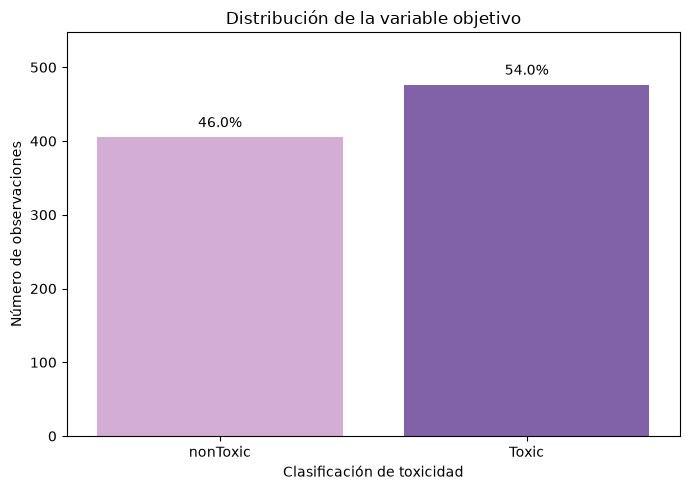

In [4]:
# Distribución de la variable objetivo
conteo_clases = df["class"].value_counts()
porcentaje_clases = df["class"].value_counts(normalize=True) * 100

tabla_clases = pd.DataFrame({
    "Frecuencia": conteo_clases,
    "Porcentaje (%)": porcentaje_clases.round(2)
})

display(tabla_clases)

# Visualización
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="class",
    order=["nonToxic", "Toxic"],
    hue="class",
    hue_order=["nonToxic", "Toxic"],
    palette=["#D9A7D9", "#8055B3"],
    legend=False
)

# Mostrar porcentajes
for barra in ax.patches:
    altura = barra.get_height()
    if altura > 0:
        porcentaje = altura / len(df) * 100
        ax.annotate(
            f"{porcentaje:.1f}%",
            (barra.get_x() + barra.get_width() / 2, altura),
            ha="center",
            va="bottom",
            xytext=(0, 5),
            textcoords="offset points"
        )

plt.title("Distribución de la variable objetivo")
plt.xlabel("Clasificación de toxicidad")
plt.ylabel("Número de observaciones")
plt.ylim(0, conteo_clases.max() * 1.15)
plt.tight_layout()
plt.show()

La distribución de la variable objetivo es relativamente equilibrada, con un 54% de observaciones clasificadas como tóxicas y un 46% como no tóxicas. Por lo tanto, no se identifica un desbalance importante entre las clases

#### 1.3. Distribución de las características fisicoquímicas

Se examinarán las distribuciones de las nueve variables numéricas mediante histogramas para identificar asimetrías, valores extremos y diferencias de escala que puedan influir en el entrenamiento de los modelos.

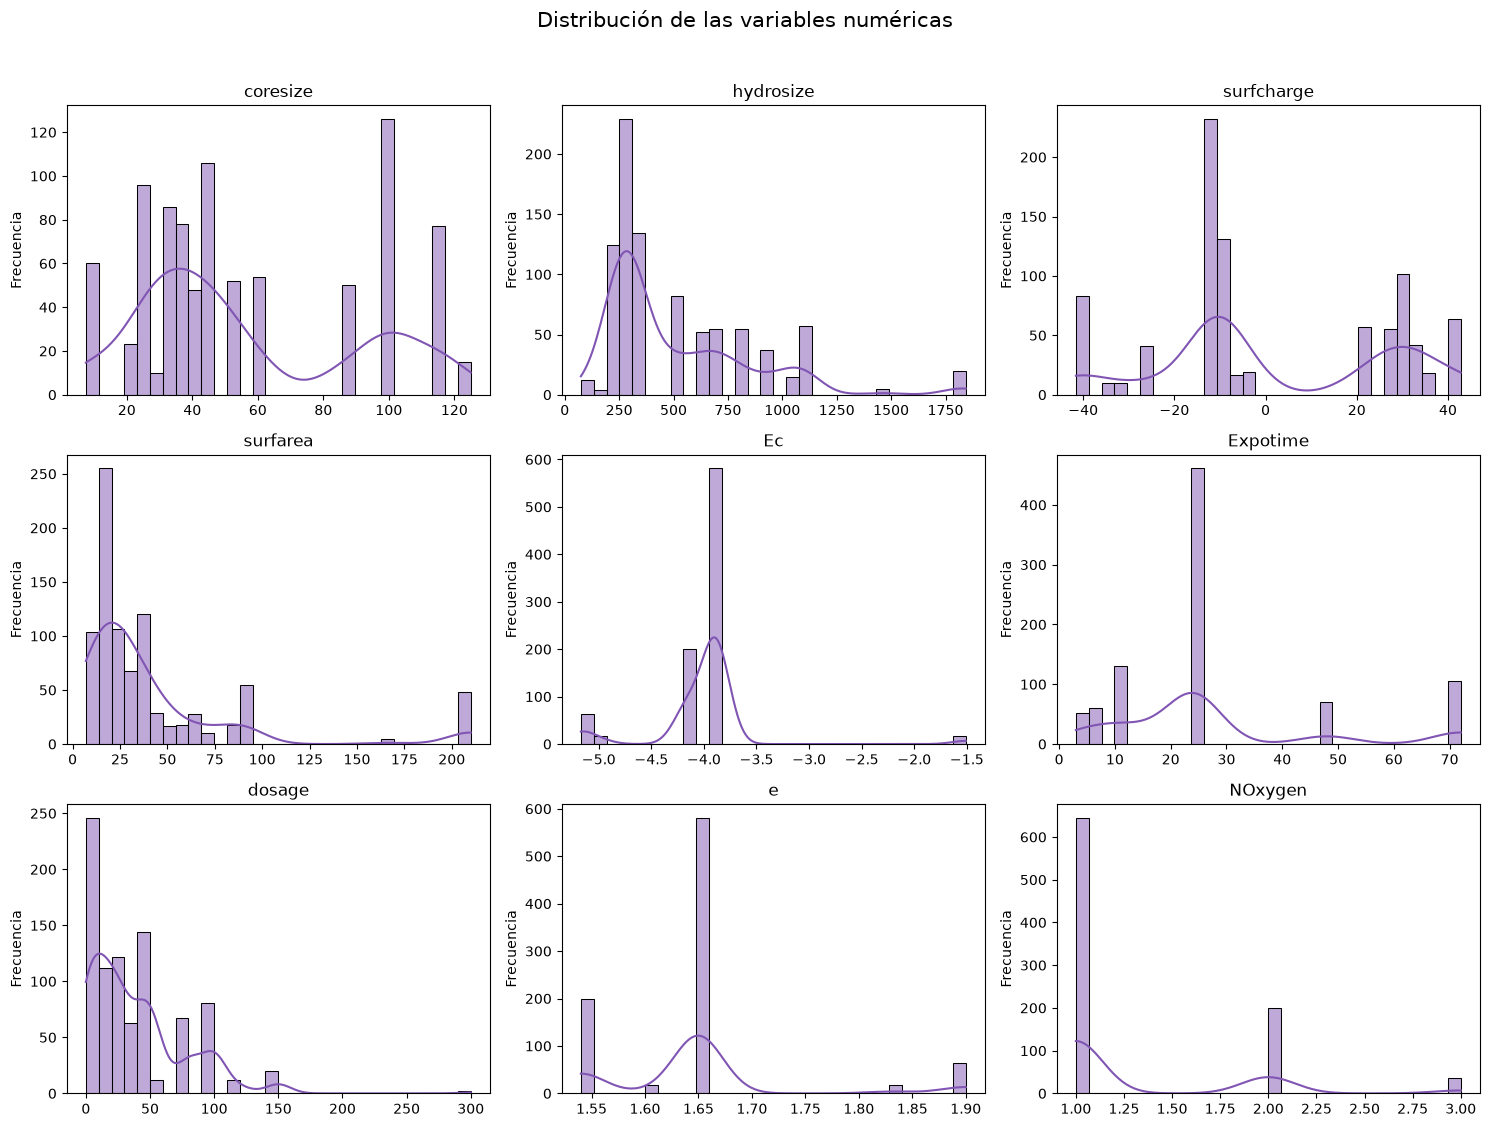

In [5]:
# Variables numéricas
variables_numericas = [
    "coresize", "hydrosize", "surfcharge",
    "surfarea", "Ec", "Expotime",
    "dosage", "e", "NOxygen"
]

# Histogramas
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for i, columna in enumerate(variables_numericas):
    sns.histplot(
        data=df,
        x=columna,
        bins=30,
        kde=True,
        color="#8055B3",
        ax=axes[i]
    )

    axes[i].set_title(columna)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frecuencia")

plt.suptitle(
    "Distribución de las variables numéricas",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()

Las variables numéricas presentan distribuciones heterogéneas, con asimetrías y concentraciones en valores específicos. Algunas características, como `hydrosize`, `surfarea` y `dosage`, muestran valores extremos que podrían corresponder a distintas condiciones experimentales. Además, las diferencias de escala entre variables deberán considerarse durante el preprocesamiento, especialmente al aplicar PCA y entrenar modelos sensibles a la escala.

#### 1.4. Distribución de características por tipo de nanopartícula

Se compararán las propiedades fisicoquímicas de los distintos tipos de nanopartículas mediante *boxplots*, con el propósito de identificar diferencias en sus distribuciones y posibles valores atípicos.

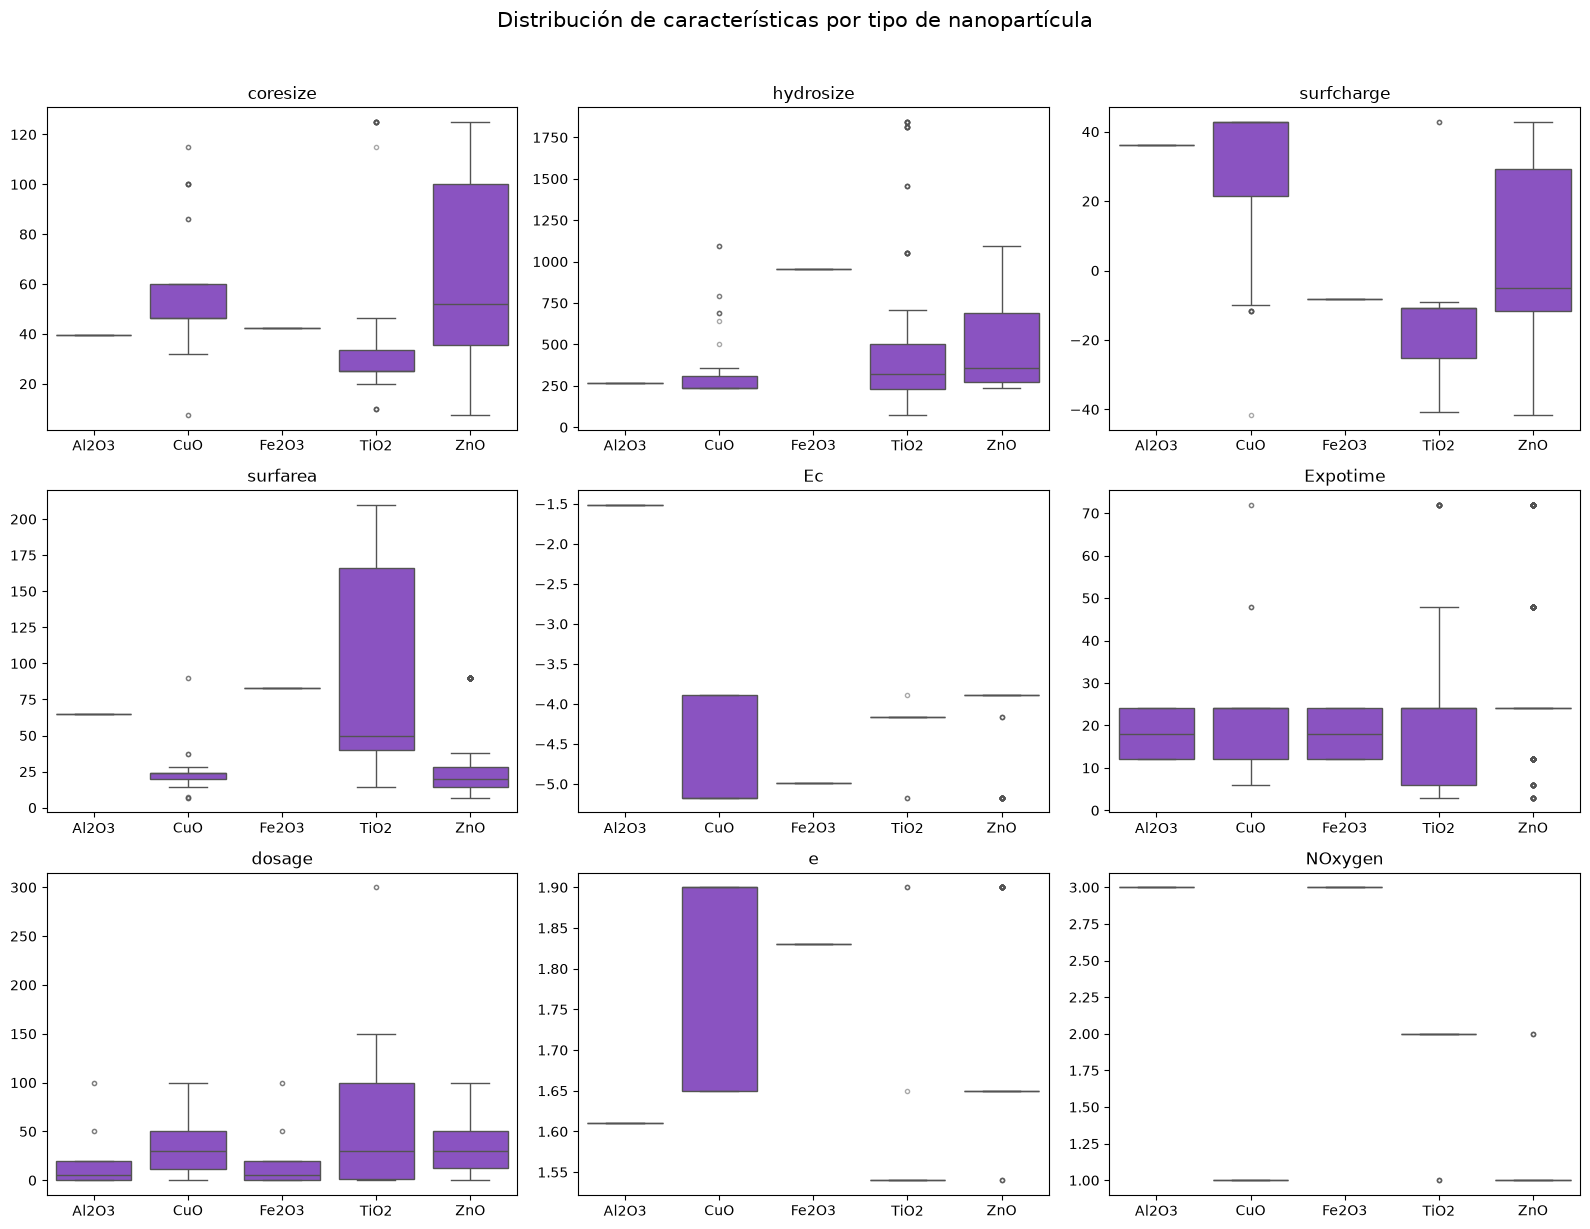

In [7]:
# Variables numéricas
variables_numericas = [
    "coresize", "hydrosize", "surfcharge",
    "surfarea", "Ec", "Expotime",
    "dosage", "e", "NOxygen"
]

# Diagramas de caja por tipo de nanopartícula
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, columna in enumerate(variables_numericas):
    sns.boxplot(
        data=df,
        x="NPs",
        y=columna,
        color="#8A41D3",
        ax=axes[i],
        flierprops={
            "marker": "o",
            "markersize": 3,
            "alpha": 0.5
        }
    )

    axes[i].set_title(columna)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

plt.suptitle(
    "Distribución de características por tipo de nanopartícula",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()


Las distribuciones muestran diferencias entre los tipos de nanopartículas, tanto en sus propiedades fisicoquímicas como en las condiciones de exposición. Algunas variables, particularmente `Ec`, `e` y `NOxygen`, presentan valores estrechamente asociados con determinados materiales, mientras que otras, como `coresize`, `hydrosize` y `surfarea`, muestran mayor variabilidad. Estas diferencias sugieren que algunas características podrían actuar como indicadores de la identidad de las nanopartículas, lo cual deberá considerarse al evaluar su importancia predictiva.

#### 1.5. Relación entre el tipo de nanopartícula y la toxicidad

Se analizará la distribución de las clases `Toxic` y `nonToxic` para cada tipo de nanopartícula, con el propósito de identificar posibles diferencias en la proporción de observaciones tóxicas entre materiales.

class,nonToxic,Toxic
NPs,,
Al2O3,18,0
CuO,11,40
Fe2O3,18,0
TiO2,194,6
ZnO,164,430


class,nonToxic,Toxic
NPs,,
Al2O3,100.00,0.00
CuO,21.57,78.43
Fe2O3,100.00,0.00
TiO2,97.00,3.00
ZnO,27.61,72.39


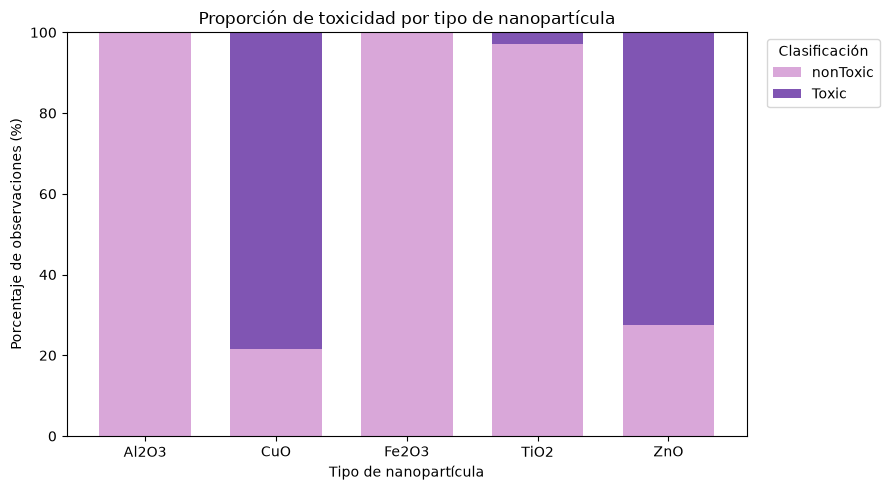

In [8]:
# Frecuencia de clases por tipo de nanopartícula
tabla_toxicidad = pd.crosstab(
    df["NPs"],
    df["class"]
).reindex(columns=["nonToxic", "Toxic"], fill_value=0)

display(tabla_toxicidad)

# Porcentaje de cada clase por nanopartícula
proporciones = (
    tabla_toxicidad.div(
        tabla_toxicidad.sum(axis=1), axis=0
    ) * 100
)

display(proporciones.round(2))

# Gráfico de barras apiladas
ax = proporciones.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#D9A7D9", "#8055B3"],
    width=0.7
)

plt.title("Proporción de toxicidad por tipo de nanopartícula")
plt.xlabel("Tipo de nanopartícula")
plt.ylabel("Porcentaje de observaciones (%)")
plt.xticks(rotation=0)
plt.yticks(range(0, 101, 20))
plt.ylim(0, 100)
plt.legend(
    title="Clasificación",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

La proporción de toxicidad varía considerablemente entre los tipos de nanopartículas. Todas las observaciones de Al₂O₃ y Fe₂O₃ se clasifican como no tóxicas, mientras que CuO y ZnO presentan una mayoría de observaciones tóxicas. Por su parte, TiO₂ muestra una proporción muy baja de toxicidad. Estos resultados evidencian una asociación entre el tipo de nanopartícula y la variable objetivo, aunque no permiten determinar si las diferencias se deben al material o a las condiciones experimentales.

#### 1.6. Correlaciones entre variables numéricas

Se calculará la matriz de correlación de Pearson para identificar relaciones lineales entre las variables numéricas y detectar posibles redundancias. Este análisis permitirá explorar si algunas características aportan información similar, lo cual será relevante al evaluar posteriormente las técnicas de reducción y selección de características.

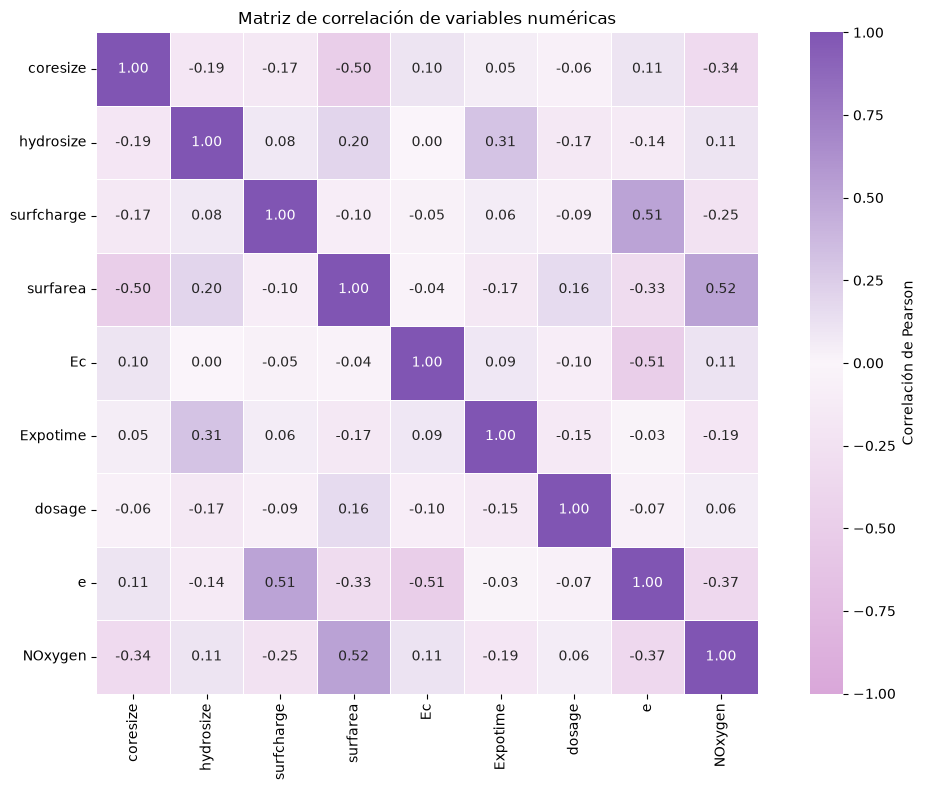

In [11]:
# Paleta de colores rosa - blanco - morad
colores = ["#D9A7D9", "#FAF5FA", "#8055B3"]

cmap_personalizado = LinearSegmentedColormap.from_list(
    "rosa_morado", colores
)

# Matriz de correlación de Pearson
correlacion = df[variables_numericas].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap=cmap_personalizado,
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Correlación de Pearson"}
)

plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()

La matriz muestra correlaciones principalmente débiles o moderadas entre las variables numéricas. Las asociaciones más destacadas se encuentran entre `surfarea` y `NOxygen` (0.52), `surfcharge` y `e` (0.51), `Ec` y `e` (−0.51), y `coresize` y `surfarea` (−0.50). No se identifican correlaciones lineales suficientemente elevadas como para considerar alguna variable redundante de manera evidente, por lo que se conservarán todas las características para evaluar posteriormente el efecto de PCA y Mutual Information sobre el desempeño de los modelos.

### 2. Análisis y tratamiento de registros duplicados

Se examinará la presencia de registros duplicados y combinaciones de características con etiquetas contradictorias. Posteriormente, se definirán distintas estrategias de tratamiento para evaluar cómo influyen estas observaciones en el desempeño de los modelos de clasificación.

#### 2.1. Identificación y cuantificación de duplicados exactos

Se identificarán los registros completamente idénticos, considerando tanto las características predictoras como la etiqueta de toxicidad. Se cuantificarán los grupos repetidos y las observaciones excedentes para determinar la magnitud de la duplicación en el conjunto de datos.

In [12]:
# Número total de registros
n_original = len(df)

# Identificar registros pertenecientes a grupos duplicados
mascara_duplicados = df.duplicated(keep=False)
n_registros_repetidos = mascara_duplicados.sum()

# Identificar registros excedentes
n_excedentes = df.duplicated(keep="first").sum()

# Contar la frecuencia de cada registro único
frecuencias = (
    df.value_counts(dropna=False)
    .reset_index(name="frecuencia")
)

# Identificar grupos con más de una aparición
grupos_repetidos = frecuencias[
    frecuencias["frecuencia"] > 1
].copy()

# Resumen de duplicados
resumen_duplicados = pd.DataFrame({
    "Indicador": [
        "Total de registros",
        "Registros en grupos duplicados",
        "Registros excedentes",
        "Grupos de registros repetidos",
        "Registros únicos"
    ],
    "Cantidad": [
        n_original,
        n_registros_repetidos,
        n_excedentes,
        len(grupos_repetidos),
        n_original - n_excedentes
    ]
})

resumen_duplicados["Porcentaje (%)"] = (
    resumen_duplicados["Cantidad"] / n_original * 100
).round(2)

display(resumen_duplicados)

,Indicador,Cantidad,Porcentaje (%)
0,Total de registros,881,100.00
1,Registros en grupos duplicados,657,74.57
2,Registros excedentes,487,55.28
3,Grupos de registros repetidos,170,19.30
4,Registros únicos,394,44.72


Se identificaron 657 observaciones pertenecientes a 170 grupos de registros repetidos, de las cuales 487 corresponden a copias adicionales. Esto representa el 55.28% del dataset, por lo que su eliminación reduciría las 881 observaciones originales a 394 registros únicos. La elevada proporción de duplicados hace necesario evaluar su influencia sobre el desempeño de los modelos antes de decidir cómo tratarlos.

#### 2.2. Análisis de frecuencia de duplicados

Se analizará la frecuencia de aparición de los registros repetidos para identificar si la duplicación se concentra en determinadas combinaciones de características y etiquetas de toxicidad.

,Número de grupos
frecuencia,
2,88
3,22
4,10
5,12
6,14
7,9
8,4
9,5
10,1


Los 10 registros más frecuentes:


,NPs,coresize,hydrosize,surfcharge,surfarea,Ec,Expotime,dosage,e,NOxygen,class,frecuencia
0,ZnO,115.0,360.0,-10.0,14.40,-3.89,24,50.0,1.65,1,Toxic,20
1,ZnO,35.6,295.5,-41.6,27.90,-3.89,24,10.0,1.65,1,Toxic,20
2,ZnO,35.6,295.5,-41.6,27.90,-3.89,24,100.0,1.65,1,Toxic,16
3,ZnO,115.0,500.0,-9.0,14.50,-3.89,24,50.0,1.65,1,Toxic,14
4,ZnO,100.0,273.4,-11.7,20.00,-3.89,24,80.0,1.65,1,Toxic,11
5,ZnO,115.0,360.0,-10.0,14.40,-3.89,24,30.0,1.65,1,Toxic,10
6,ZnO,115.0,500.0,-9.0,14.50,-3.89,24,80.0,1.65,1,Toxic,9
7,ZnO,60.0,936.0,-2.4,7.34,-3.89,24,20.0,1.65,1,Toxic,9
8,ZnO,52.0,640.0,29.4,15.00,-3.89,72,50.0,1.65,1,Toxic,9
9,ZnO,7.5,795.0,27.4,90.00,-3.89,24,25.0,1.65,1,Toxic,9


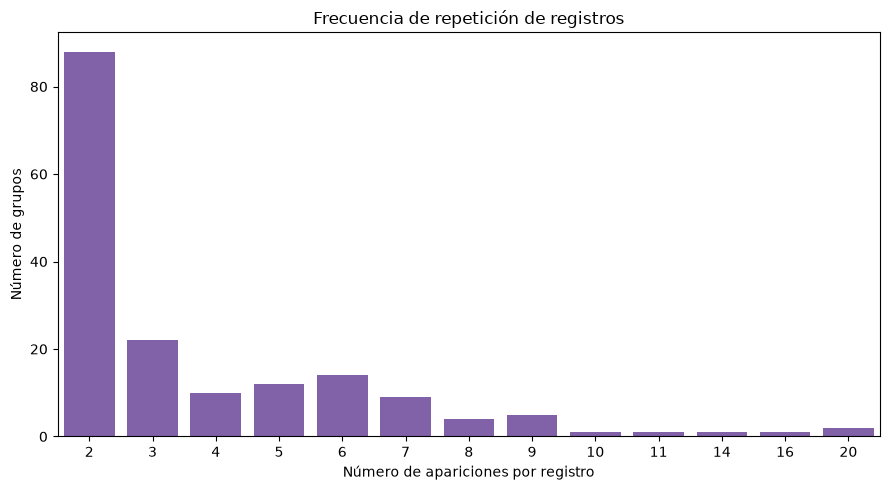

In [13]:
# Distribución de frecuencias de los grupos repetidos
distribucion_frecuencias = (
    grupos_repetidos["frecuencia"]
    .value_counts()
    .sort_index()
)

display(
    distribucion_frecuencias.to_frame("Número de grupos")
)

# Registros con mayor frecuencia de repetición
print("Los 10 registros más frecuentes:")
display(
    grupos_repetidos
    .sort_values("frecuencia", ascending=False)
    .head(10)
)

# Visualización
plt.figure(figsize=(9, 5))

sns.barplot(
    x=distribucion_frecuencias.index,
    y=distribucion_frecuencias.values,
    color="#8055B3"
)

plt.title("Frecuencia de repetición de registros")
plt.xlabel("Número de apariciones por registro")
plt.ylabel("Número de grupos")
plt.tight_layout()
plt.show()

La mayoría de los 170 grupos de registros repetidos aparecen entre dos y tres veces, aunque algunas combinaciones alcanzan hasta 20 apariciones. Los diez registros más frecuentes corresponden a nanopartículas de ZnO clasificadas como tóxicas, lo que sugiere que la duplicación podría favorecer determinadas condiciones experimentales y clases durante el entrenamiento. Por ello, será importante comparar el desempeño de los modelos con y sin registros duplicados.

#### 2.3. Identificación de etiquetas contradictorias

Se identificarán combinaciones de características predictoras que presentan diferentes etiquetas de toxicidad. Se cuantificarán estos casos y se examinará su distribución para evaluar posibles inconsistencias en el conjunto de datos.

In [14]:
# Variables predictoras
columnas_predictoras = df.columns.drop("class").tolist()

# Número de clases distintas por combinación de características
clases_por_combinacion = (
    df.groupby(columnas_predictoras, dropna=False)["class"]
    .nunique()
    .reset_index(name="n_clases")
)

# Combinaciones con etiquetas contradictorias
combinaciones_contradictorias = clases_por_combinacion[
    clases_por_combinacion["n_clases"] > 1
].copy()

# Recuperar todas las observaciones involucradas
registros_contradictorios = df.merge(
    combinaciones_contradictorias[columnas_predictoras],
    on=columnas_predictoras,
    how="inner"
)

# Resumen
print(
    "Combinaciones con etiquetas contradictorias:",
    len(combinaciones_contradictorias)
)

print(
    "Observaciones involucradas:",
    len(registros_contradictorios)
)

print(
    "Porcentaje del dataset:",
    f"{len(registros_contradictorios) / len(df) * 100:.2f}%"
)

# Distribución de clases en los registros contradictorios
display(
    registros_contradictorios["class"]
    .value_counts()
    .to_frame("Frecuencia")
)

# Resumen por combinación y etiqueta
resumen_contradicciones = (
    registros_contradictorios
    .groupby(
        columnas_predictoras + ["class"],
        dropna=False
    )
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

display(resumen_contradicciones)

Combinaciones con etiquetas contradictorias: 11
Observaciones involucradas: 64
Porcentaje del dataset: 7.26%


,Frecuencia
class,
Toxic,53
nonToxic,11


class,NPs,coresize,hydrosize,surfcharge,surfarea,Ec,Expotime,dosage,e,NOxygen,Toxic,nonToxic
0,ZnO,100.0,273.4,-11.7,20.0,-3.89,3,80.0,1.65,1,3,1
1,ZnO,100.0,273.4,-11.7,20.0,-3.89,6,80.0,1.65,1,6,1
2,ZnO,100.0,273.4,-11.7,20.0,-3.89,24,25.0,1.65,1,2,1
3,ZnO,100.0,273.4,-11.7,20.0,-3.89,24,30.0,1.65,1,5,1
4,ZnO,100.0,273.4,-11.7,20.0,-3.89,24,35.0,1.65,1,3,1
5,ZnO,100.0,273.4,-11.7,20.0,-3.89,24,40.0,1.65,1,5,1
6,ZnO,100.0,273.4,-11.7,20.0,-3.89,48,25.0,1.65,1,6,1
7,ZnO,100.0,273.4,-11.7,20.0,-3.89,48,30.0,1.65,1,7,1
8,ZnO,100.0,273.4,-11.7,20.0,-3.89,48,35.0,1.65,1,7,1
9,ZnO,100.0,273.4,-11.7,20.0,-3.89,48,40.0,1.65,1,5,1


Se identificaron 11 combinaciones de características con etiquetas contradictorias, que involucran 64 observaciones (7.26% del conjunto de datos). Todas corresponden a nanopartículas de ZnO y presentan una mayoría de etiquetas tóxicas (53 frente a 11 no tóxicas). Estas inconsistencias podrían introducir ambigüedad durante el aprendizaje, ya que observaciones con características idénticas tienen clasificaciones diferentes. Por ello, se evaluará posteriormente el efecto de conservar o excluir estas combinaciones, sin asumir que representan necesariamente errores de etiquetado.

#### 2.4. Impacto de los duplicados en la distribución de clases

Se comparará la distribución de toxicidad antes y después de eliminar los duplicados exactos, con el propósito de determinar si las observaciones repetidas modifican la proporción de las clases. También se analizará su distribución por tipo de nanopartícula para identificar posibles diferencias en la representación de los materiales.

,Original (%),Sin duplicados (%),Diferencia (pp)
class,,,
nonToxic,45.97,75.13,29.16
Toxic,54.03,24.87,-29.16


,Original (%),Sin duplicados (%)
NPs,,
Al2O3,2.04,4.57
CuO,5.79,9.39
Fe2O3,2.04,4.57
TiO2,22.70,31.22
ZnO,67.42,50.25


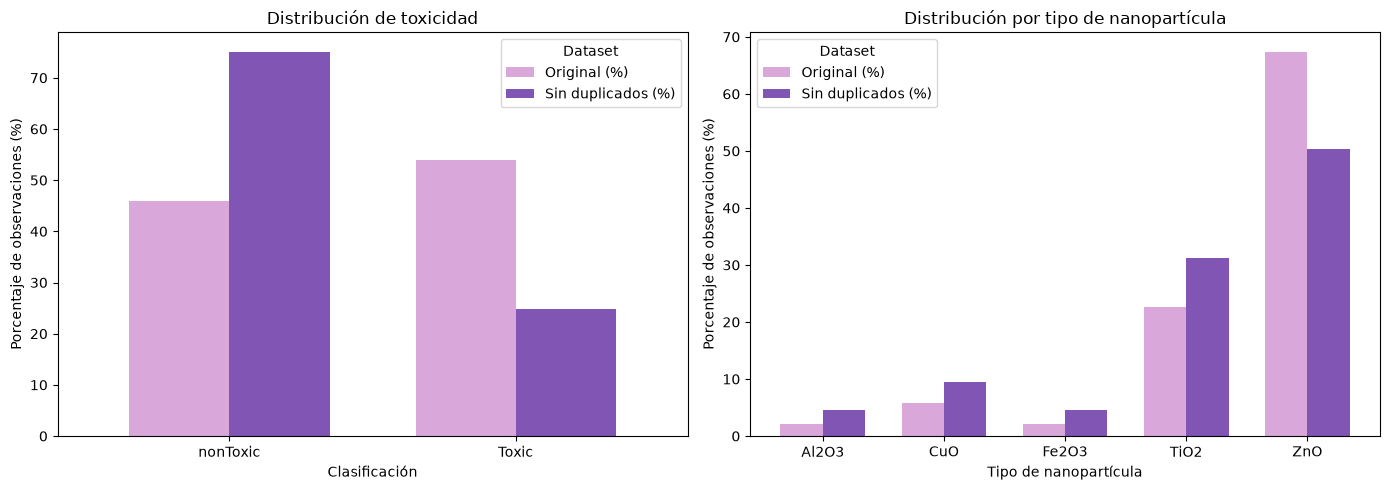

In [15]:
# Crear una versión sin duplicados exactos
df_sin_duplicados = df.drop_duplicates().copy()

# Comparar la distribución de clases
orden_clases = ["nonToxic", "Toxic"]

distribucion_original = (
    df["class"]
    .value_counts(normalize=True)
    .reindex(orden_clases, fill_value=0) * 100
)

distribucion_sin_duplicados = (
    df_sin_duplicados["class"]
    .value_counts(normalize=True)
    .reindex(orden_clases, fill_value=0) * 100
)

comparacion_clases = pd.DataFrame({
    "Original (%)": distribucion_original,
    "Sin duplicados (%)": distribucion_sin_duplicados
})

comparacion_clases["Diferencia (pp)"] = (
    comparacion_clases["Sin duplicados (%)"]
    - comparacion_clases["Original (%)"]
)

display(comparacion_clases.round(2))

# Comparar la representación de nanopartículas
orden_nps = sorted(df["NPs"].unique())

distribucion_nps = pd.DataFrame({
    "Original (%)": (
        df["NPs"].value_counts(normalize=True)
        .reindex(orden_nps, fill_value=0) * 100
    ),
    "Sin duplicados (%)": (
        df_sin_duplicados["NPs"]
        .value_counts(normalize=True)
        .reindex(orden_nps, fill_value=0) * 100
    )
})

display(distribucion_nps.round(2))

# Visualizaciones
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

comparacion_clases[
    ["Original (%)", "Sin duplicados (%)"]
].plot(
    kind="bar",
    ax=axes[0],
    color=["#D9A7D9", "#8055B3"],
    width=0.7
)

axes[0].set_title("Distribución de toxicidad")
axes[0].set_xlabel("Clasificación")
axes[0].set_ylabel("Porcentaje de observaciones (%)")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Dataset")

distribucion_nps.plot(
    kind="bar",
    ax=axes[1],
    color=["#D9A7D9", "#8055B3"],
    width=0.7
)

axes[1].set_title("Distribución por tipo de nanopartícula")
axes[1].set_xlabel("Tipo de nanopartícula")
axes[1].set_ylabel("Porcentaje de observaciones (%)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Dataset")

plt.tight_layout()
plt.show()

La eliminación de duplicados produjo cambios importantes en la composición del conjunto de datos. La proporción de observaciones tóxicas disminuyó del 54.03% al 24.87%, mientras que la representación de ZnO se redujo del 67.42% al 50.25%. Estos resultados muestran que los registros repetidos favorecen determinadas clases y materiales, por lo que su presencia podría influir en el aprendizaje y la evaluación de los modelos.

#### 2.5. Definición de estrategias de tratamiento de duplicados

Se definirán tres estrategias de tratamiento: conservar los registros originales, eliminar duplicados exactos y excluir adicionalmente las combinaciones con etiquetas contradictorias. Estas estrategias se compararán posteriormente utilizando las mismas particiones de validación y los mismos modelos, con el propósito de evaluar su efecto sobre el desempeño predictivo.

Los tratamientos se aplicarán únicamente a los datos de entrenamiento, manteniendo las observaciones de evaluación sin modificaciones para garantizar una comparación consistente.

In [17]:
#Estrategias de tratamiento de duplicados

def tratar_duplicados(df_train, estrategia="original"):
    """
    Aplica una estrategia de tratamiento a los datos.

    Estrategias:
    - original: conserva todos los registros.
    - sin_duplicados: elimina duplicados exactos.
    - sin_duplicados_ni_contradicciones:
      elimina duplicados exactos y combinaciones
      con etiquetas contradictorias.
    """

    datos = df_train.copy()

    if estrategia == "original":
        return datos

    elif estrategia == "sin_duplicados":
        return datos.drop_duplicates().copy()

    elif estrategia == "sin_duplicados_ni_contradicciones":

        # Eliminar duplicados exactos
        datos = datos.drop_duplicates().copy()

        # Identificar variables predictoras
        predictores = datos.columns.drop("class").tolist()

        # Contar etiquetas distintas por combinación
        n_clases = datos.groupby(
            predictores,
            dropna=False
        )["class"].transform("nunique")

        # Conservar solo combinaciones sin contradicciones
        return datos.loc[n_clases == 1].copy()

    else:
        raise ValueError(
            f"Estrategia no reconocida: {estrategia}"
        )


# Definir las tres estrategias
estrategias = [
    "original",
    "sin_duplicados",
    "sin_duplicados_ni_contradicciones"
]


# Comparación descriptiva de las estrategias
resumen_estrategias = []

for estrategia in estrategias:

    datos = tratar_duplicados(df, estrategia)

    resumen_estrategias.append({
        "Estrategia": estrategia,
        "Registros": len(datos),
        "Toxic (%)": round(
            (datos["class"] == "Toxic").mean() * 100, 2
        ),
        "nonToxic (%)": round(
            (datos["class"] == "nonToxic").mean() * 100, 2
        )
    })


# Mostrar resultados
resumen_estrategias = pd.DataFrame(resumen_estrategias)

display(resumen_estrategias)

,Estrategia,Registros,Toxic (%),nonToxic (%)
0,original,881,54.03,45.97
1,sin_duplicados,394,24.87,75.13
2,sin_duplicados_ni_contradicciones,372,23.39,76.61


Se definieron tres estrategias de tratamiento que produjeron conjuntos de 881, 394 y 372 observaciones, respectivamente. La eliminación de duplicados exactos generó el cambio más importante en la distribución de clases, mientras que la exclusión adicional de combinaciones contradictorias tuvo un efecto menor. Estas estrategias permitirán evaluar posteriormente si las diferencias en la composición de los datos influyen en el desempeño predictivo de los modelos.

### 3. Preparación de datos y estrategia de validación

Se definirán las variables predictoras, la variable objetivo y los grupos de observaciones relacionadas. Posteriormente, se establecerá una estrategia de validación cruzada estratificada por grupos para reducir el riesgo de fuga de información y garantizar que los tratamientos de duplicados se evalúen sobre particiones comparables.

#### 3.1. Definición de variables predictoras y variable objetivo

Se separarán las nueve variables numéricas y la variable categórica `NPs` de la variable objetivo `class`. Esta última se codificará de forma binaria, asignando 1 a las observaciones tóxicas y 0 a las no tóxicas.

In [18]:
# Variables predictoras
variables_numericas = [
    "coresize", "hydrosize", "surfcharge",
    "surfarea", "Ec", "Expotime",
    "dosage", "e", "NOxygen"
]

variables_categoricas = ["NPs"]

columnas_predictoras = (
    variables_numericas + variables_categoricas
)

X = df[columnas_predictoras].copy()

# Codificación de la variable objetivo
y = df["class"].map({
    "nonToxic": 0,
    "Toxic": 1
})

# Verificar que no existan etiquetas desconocidas
assert y.notna().all(), (
    "Se encontraron etiquetas de toxicidad no reconocidas."
)

y = y.astype(int)

# Resumen
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nDistribución de clases:")
display(
    y.value_counts()
    .rename(index={0: "nonToxic", 1: "Toxic"})
    .to_frame("Frecuencia")
)

print("\nVariables predictoras:")
display(pd.DataFrame({
    "Variable": columnas_predictoras,
    "Tipo": (
        ["Numérica"] * len(variables_numericas)
        + ["Categórica"] * len(variables_categoricas)
    )
}))

Dimensiones de X: (881, 10)
Dimensiones de y: (881,)

Distribución de clases:


,Frecuencia
class,
Toxic,476
nonToxic,405



Variables predictoras:


,Variable,Tipo
0,coresize,Numérica
1,hydrosize,Numérica
2,surfcharge,Numérica
3,surfarea,Numérica
4,Ec,Numérica
5,Expotime,Numérica
6,dosage,Numérica
7,e,Numérica
8,NOxygen,Numérica
9,NPs,Categórica


#### 3.2. Identificación de grupos de observaciones relacionadas

Se agruparán las observaciones que compartan el mismo tipo de nanopartícula y las mismas propiedades fisicoquímicas, sin considerar la dosis ni el tiempo de exposición. Estos grupos se utilizarán durante la validación cruzada para mantener separadas las observaciones relacionadas y reducir el riesgo de fuga de información.

In [19]:
# Características utilizadas para identificar grupos
columnas_grupo = [
    "NPs", "coresize", "hydrosize",
    "surfcharge", "surfarea", "Ec",
    "e", "NOxygen"
]

# Crear identificadores de grupo sobre el dataset original
groups = pd.Series(
    df.groupby(
        columnas_grupo,
        dropna=False,
        sort=False
    ).ngroup(),
    index=df.index,
    name="grupo"
)

# Resumen de los grupos
resumen_grupos = (
    df.assign(grupo=groups)
    .groupby("grupo")
    .agg(
        registros=("class", "size"),
        toxicos=("class", lambda x: (x == "Toxic").sum()),
        no_toxicos=("class", lambda x: (x == "nonToxic").sum()),
        nanoparticula=("NPs", "first")
    )
    .sort_values("registros", ascending=False)
)

print("Número de grupos:", groups.nunique())
print("Tamaño mínimo:", resumen_grupos["registros"].min())
print("Tamaño máximo:", resumen_grupos["registros"].max())

print("\nLos 10 grupos más grandes:")
display(resumen_grupos.head(10))

# Verificar que registros con predictores idénticos
# no pertenezcan a grupos diferentes
verificacion = (
    df.assign(grupo=groups)
    .groupby(columnas_predictoras, dropna=False)["grupo"]
    .nunique()
)

assert verificacion.max() == 1, (
    "Existen observaciones idénticas en grupos diferentes."
)

print("\nVerificación de grupos: correcta.")

Número de grupos: 42
Tamaño mínimo: 1
Tamaño máximo: 119

Los 10 grupos más grandes:


,registros,toxicos,no_toxicos,nanoparticula
grupo,,,,
22,119,60,59,ZnO
27,55,50,5,ZnO
26,54,39,15,ZnO
25,53,39,14,ZnO
24,51,36,15,ZnO
4,48,0,48,TiO2
3,48,0,48,TiO2
23,47,32,15,ZnO
17,42,38,4,ZnO



Verificación de grupos: correcta.


Se identificaron 42 grupos de observaciones con características fisicoquímicas compartidas, cuyos tamaños varían entre 1 y 119 registros. Los grupos más grandes corresponden principalmente a ZnO y presentan diferentes proporciones de toxicidad. Esta heterogeneidad deberá considerarse al construir las particiones de validación, ya que podría dificultar el equilibrio de clases entre pliegues. La verificación confirmó que las observaciones con características predictoras idénticas permanecen dentro del mismo grupo.

#### 3.3. Construcción y verificación de las particiones de validación

Se utilizará validación cruzada estratificada por grupos (`StratifiedGroupKFold`) con cinco pliegues. Se verificará la distribución de clases y el número de observaciones en cada partición, así como la ausencia de grupos compartidos entre entrenamiento y validación.

Las mismas particiones se utilizarán posteriormente para comparar las estrategias de tratamiento de duplicados y los distintos modelos de clasificación.

In [20]:
# Configuración de validación cruzada
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Guardar las particiones para reutilizarlas
particiones_cv = list(
    cv.split(X, y, groups=groups)
)

resumen_cv = []

for i, (idx_train, idx_val) in enumerate(particiones_cv, 1):

    y_train = y.iloc[idx_train]
    y_val = y.iloc[idx_val]

    grupos_train = set(groups.iloc[idx_train])
    grupos_val = set(groups.iloc[idx_val])

    # Verificar ausencia de grupos compartidos
    grupos_compartidos = grupos_train.intersection(grupos_val)

    resumen_cv.append({
        "Pliegue": i,
        "Entrenamiento": len(idx_train),
        "Validación": len(idx_val),
        "Grupos train": len(grupos_train),
        "Grupos val": len(grupos_val),
        "Toxic train (%)": round(y_train.mean() * 100, 2),
        "Toxic val (%)": round(y_val.mean() * 100, 2),
        "Clases train": y_train.nunique(),
        "Clases val": y_val.nunique(),
        "Grupos compartidos": len(grupos_compartidos)
    })

resumen_cv = pd.DataFrame(resumen_cv)

display(resumen_cv)

# Verificaciones
assert (resumen_cv["Grupos compartidos"] == 0).all(), (
    "Se detectaron grupos compartidos."
)

assert (resumen_cv["Clases train"] == 2).all(), (
    "Algún entrenamiento contiene una sola clase."
)

assert (resumen_cv["Clases val"] == 2).all(), (
    "Alguna validación contiene una sola clase."
)

# Verificar que cada observación aparezca una vez en validación
indices_validacion = np.concatenate(
    [idx_val for _, idx_val in particiones_cv]
)

assert len(indices_validacion) == len(X)
assert len(np.unique(indices_validacion)) == len(X)

print("\nVerificación de particiones completada.")


,Pliegue,Entrenamiento,Validación,Grupos train,Grupos val,Toxic train (%),Toxic val (%),Clases train,Clases val,Grupos compartidos
0,1,724,157,34,8,54.56,51.59,2,2,0
1,2,731,150,35,7,53.63,56.00,2,2,0
2,3,729,152,33,9,54.05,53.95,2,2,0
3,4,613,268,32,10,54.49,52.99,2,2,0
4,5,727,154,34,8,53.51,56.49,2,2,0



Verificación de particiones completada.


Las cinco particiones conservaron ambas clases y presentaron proporciones de toxicidad relativamente similares, entre 51.59% y 56.49%. No se identificaron grupos compartidos entre entrenamiento y validación, lo que reduce el riesgo de fuga de información entre observaciones relacionadas. Aunque los tamaños de los pliegues fueron diferentes debido a la distribución de los grupos, las particiones resultaron adecuadas para continuar con la evaluación de los modelos.

#### 3.4. Aplicación de las estrategias de tratamiento en las particiones

Se aplicarán las tres estrategias de tratamiento de duplicados únicamente a los conjuntos de entrenamiento de cada pliegue. Se comparará el número de observaciones y la distribución de clases resultantes, manteniendo sin modificaciones los conjuntos de validación.

In [21]:
# Comparación de estrategias dentro de los pliegues

resultados_tratamiento = []

for i, (idx_train, idx_val) in enumerate(particiones_cv, 1):

    # Recuperar entrenamiento original
    df_train = df.iloc[idx_train].copy()

    # Validación sin modificaciones
    df_val = df.iloc[idx_val].copy()

    for estrategia in estrategias:

        # Aplicar tratamiento solo al entrenamiento
        df_train_tratado = tratar_duplicados(
            df_train,
            estrategia
        )

        resultados_tratamiento.append({
            "Pliegue": i,
            "Estrategia": estrategia,
            "Registros train": len(df_train_tratado),
            "Registros val": len(df_val),
            "Toxic train (%)": round(
                (df_train_tratado["class"] == "Toxic").mean()
                * 100, 2
            ),
            "Toxic val (%)": round(
                (df_val["class"] == "Toxic").mean()
                * 100, 2
            )
        })

# Tabla comparativa
resultados_tratamiento = pd.DataFrame(
    resultados_tratamiento
)

display(resultados_tratamiento)

# Resumen por estrategia
resumen_tratamiento_cv = (
    resultados_tratamiento
    .groupby("Estrategia")
    .agg({
        "Registros train": ["mean", "min", "max"],
        "Toxic train (%)": ["mean", "std"]
    })
    .round(2)
)

print("\nResumen por estrategia:")
display(resumen_tratamiento_cv)

,Pliegue,Estrategia,Registros train,Registros val,Toxic train (%),Toxic val (%)
0,1,original,724,157,54.56,51.59
1,1,sin_duplicados,319,157,23.51,51.59
2,1,sin_duplicados_ni_contradicciones,297,157,21.55,51.59
3,2,original,731,150,53.63,56.00
4,2,sin_duplicados,330,150,26.36,56.00
5,2,sin_duplicados_ni_contradicciones,308,150,24.68,56.00
6,3,original,729,152,54.05,53.95
7,3,sin_duplicados,324,152,22.84,53.95
8,3,sin_duplicados_ni_contradicciones,302,152,20.86,53.95
9,4,original,613,268,54.49,52.99



Resumen por estrategia:


Registros train           Toxic train (%)  \
                                             mean  min  max            mean   
Estrategia                                                                    
original                                    704.8  613  731           54.05   
sin_duplicados                              315.2  287  330           24.88   
sin_duplicados_ni_contradicciones           297.6  285  308           23.40   

                                         
                                    std  
Estrategia                               
original                           0.48  
sin_duplicados                     1.62  
sin_duplicados_ni_contradicciones  2.03

La aplicación de las estrategias de tratamiento redujo considerablemente el número de observaciones disponibles para entrenamiento. En promedio, los conjuntos pasaron de 704.8 registros originales a 315.2 sin duplicados y 297.6 al excluir también las contradicciones. La proporción de observaciones tóxicas disminuyó aproximadamente del 54% al 25% y 23%, respectivamente. Estas diferencias se mantuvieron relativamente consistentes entre pliegues, mientras que los conjuntos de validación permanecieron sin modificaciones, permitiendo realizar comparaciones bajo las mismas condiciones de evaluación.

### 4. Representación de características

Se compararán tres estrategias de representación: conservar las características originales, aplicar reducción de dimensionalidad mediante PCA y realizar selección de características mediante Mutual Information. El objetivo será determinar cómo influyen estas técnicas en el desempeño de los modelos y cuáles resultan más adecuadas para la predicción de toxicidad.

#### 4.1. Representación sin reducción de dimensionalidad

Se construirá una representación que conservará todas las características predictoras del conjunto de datos. Las variables numéricas se estandarizarán mediante `StandardScaler`, mientras que la variable categórica `NPs` se transformará mediante `OneHotEncoder`.

Esta representación servirá como referencia para evaluar posteriormente el efecto de PCA y Mutual Information sobre el desempeño de los modelos.

In [24]:
# Pipeline para variables numéricas
pipeline_numerico = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline para variables categóricas
pipeline_categorico = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Representación sin reducción de dimensionalidad
preprocesamiento_base = ColumnTransformer(
    transformers=[
        ("num", pipeline_numerico, variables_numericas),
        ("cat", pipeline_categorico, variables_categoricas)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

print("Preprocesamiento base definido correctamente.")

Preprocesamiento base definido correctamente.


In [25]:
# Primer pliegue de validación
idx_train, idx_val = particiones_cv[0]

X_train = X.iloc[idx_train]
X_val = X.iloc[idx_val]

# Crear una copia independiente del preprocesamiento
preprocesador_prueba = clone(preprocesamiento_base)

# Ajustar únicamente con entrenamiento
X_train_transformado = preprocesador_prueba.fit_transform(
    X_train
)

# Transformar validación sin volver a ajustar
X_val_transformado = preprocesador_prueba.transform(
    X_val
)

# Nombres de las características resultantes
nombres_caracteristicas = (
    preprocesador_prueba.get_feature_names_out()
)

print("Dimensiones originales:", X_train.shape)
print("Dimensiones transformadas:", X_train_transformado.shape)
print("Dimensiones de validación:", X_val_transformado.shape)

print("\nCaracterísticas resultantes:")
display(pd.DataFrame({
    "Característica": nombres_caracteristicas
}))

# Verificaciones
assert X_train_transformado.shape[1] == X_val_transformado.shape[1]
assert np.isfinite(X_train_transformado).all()
assert np.isfinite(X_val_transformado).all()

print("\nVerificación completada correctamente.")

Dimensiones originales: (724, 10)
Dimensiones transformadas: (724, 14)
Dimensiones de validación: (157, 14)

Características resultantes:


,Característica
0,coresize
1,hydrosize
2,surfcharge
3,surfarea
4,Ec
5,Expotime
6,dosage
7,e
8,NOxygen
9,NPs_Al2O3



Verificación completada correctamente.


El preprocesamiento generó 14 características a partir de las 10 variables predictoras originales: nueve variables numéricas estandarizadas y cinco columnas binarias correspondientes a los tipos de nanopartículas. Las dimensiones fueron consistentes entre entrenamiento y validación, confirmando que la representación puede aplicarse a ambos conjuntos sin modificar su estructura.

#### 4.2. Reducción de dimensionalidad mediante PCA

Se aplicará el Análisis de Componentes Principales (PCA) sobre las variables numéricas estandarizadas, conservando los componentes necesarios para explicar al menos el 95% de la varianza acumulada. La variable categórica `NPs` se mantendrá mediante One-Hot Encoding.

Se examinará la cantidad de componentes seleccionados y la varianza explicada para determinar el grado de reducción alcanzado.

Preprocesamiento con PCA definido correctamente.
Componentes seleccionados: 7
Varianza acumulada: 95.07%
Dimensiones transformadas: (724, 12)
Dimensiones de validación: (157, 12)


,Componente,Varianza explicada (%),Varianza acumulada (%)
0,PC1,27.29,27.29
1,PC2,16.99,44.28
2,PC3,15.98,60.26
3,PC4,11.91,72.17
4,PC5,10.02,82.19
5,PC6,7.08,89.27
6,PC7,5.81,95.07


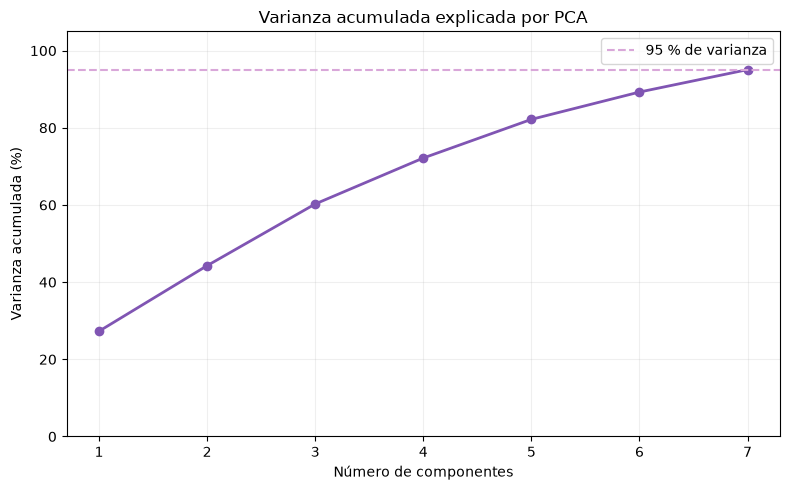

In [27]:
# Pipeline numérico con PCA
pipeline_numerico_pca = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95))
])

# Representación con PCA
preprocesamiento_pca = ColumnTransformer(
    transformers=[
        ("num", pipeline_numerico_pca, variables_numericas),
        ("cat", clone(pipeline_categorico), variables_categoricas)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

print("Preprocesamiento con PCA definido correctamente.")

# Ajustar PCA únicamente con entrenamiento
preprocesador_pca_prueba = clone(preprocesamiento_pca)

X_train_pca = preprocesador_pca_prueba.fit_transform(X_train)
X_val_pca = preprocesador_pca_prueba.transform(X_val)

# Recuperar el PCA ajustado
pca_ajustado = (
    preprocesador_pca_prueba
    .named_transformers_["num"]
    .named_steps["pca"]
)

# Varianza explicada
varianza = pca_ajustado.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza)

tabla_pca = pd.DataFrame({
    "Componente": [
        f"PC{i+1}" for i in range(len(varianza))
    ],
    "Varianza explicada (%)": varianza * 100,
    "Varianza acumulada (%)": varianza_acumulada * 100
})

print("Componentes seleccionados:", pca_ajustado.n_components_)
print("Varianza acumulada:", f"{varianza_acumulada[-1]*100:.2f}%")
print("Dimensiones transformadas:", X_train_pca.shape)
print("Dimensiones de validación:", X_val_pca.shape)

display(tabla_pca.round(2))

# Visualización
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(varianza_acumulada) + 1),
    varianza_acumulada * 100,
    marker="o",
    color="#8055B3",
    linewidth=2
)

plt.axhline(
    y=95,
    color="#D9A7D9",
    linestyle="--",
    label="95 % de varianza"
)

plt.title("Varianza acumulada explicada por PCA")
plt.xlabel("Número de componentes")
plt.ylabel("Varianza acumulada (%)")
plt.xticks(range(1, len(varianza_acumulada) + 1))
plt.ylim(0, 105)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


PCA permitió reducir las nueve variables numéricas a siete componentes principales, conservando aproximadamente el 95% de la varianza acumulada. Al mantener las cinco variables binarias correspondientes al tipo de nanopartícula, la representación pasó de 14 a 12 características. Aunque la reducción fue relativamente pequeña, esta representación permitirá evaluar si la transformación de las variables originales mejora el desempeño predictivo de los modelos.

#### 4.3. Selección de características mediante Mutual Information

Se utilizará Mutual Information para estimar la dependencia entre las variables numéricas y la clasificación de toxicidad. A partir de estos valores, se seleccionarán las características con mayor información predictiva, conservando por separado la codificación de la variable categórica `NPs`.

La selección se integrará posteriormente en los pipelines para evitar utilizar información de los conjuntos de validación durante el entrenamiento.

In [28]:
# Configurar Mutual Information para variables continuas
mi_score = partial(
    mutual_info_classif,
    discrete_features=False,
    random_state=42
)

# Pipeline numérico con selección de características
pipeline_numerico_mi = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(
        score_func=mi_score,
        k=5
    ))
])

# Representación con Mutual Information
preprocesamiento_mi = ColumnTransformer(
    transformers=[
        ("num", pipeline_numerico_mi, variables_numericas),
        ("cat", clone(pipeline_categorico), variables_categoricas)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

print("Preprocesamiento con Mutual Information definido correctamente.")

Preprocesamiento con Mutual Information definido correctamente.


,Variable,Mutual Information,Seleccionada
1,hydrosize,0.3086,True
6,dosage,0.2902,True
0,coresize,0.2722,True
2,surfcharge,0.2672,True
3,surfarea,0.2549,True
7,e,0.2509,False
4,Ec,0.2236,False
8,NOxygen,0.2106,False
5,Expotime,0.0353,False


Dimensiones transformadas: (724, 10)
Dimensiones de validación: (157, 10)


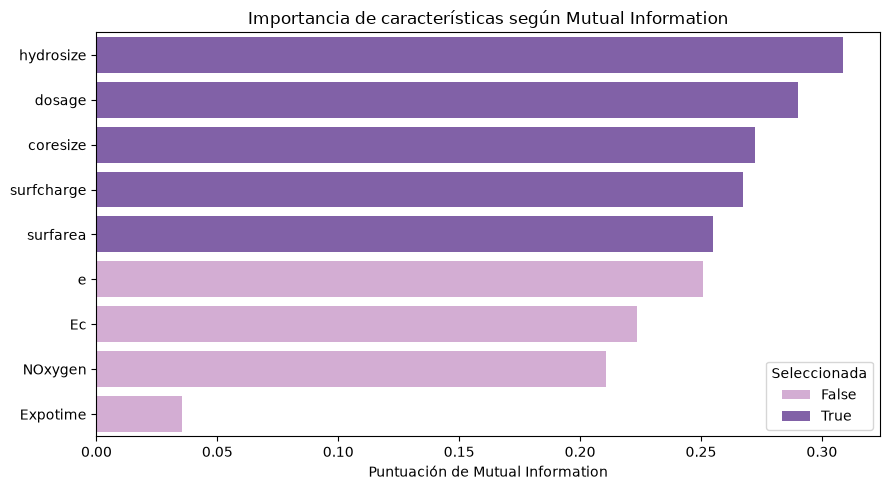

In [30]:
# Ajustar MI solo con entrenamiento
preprocesador_mi_prueba = clone(preprocesamiento_mi)

X_train_mi = preprocesador_mi_prueba.fit_transform(
    X_train,
    y.iloc[idx_train]
)

X_val_mi = preprocesador_mi_prueba.transform(X_val)

# Recuperar selector ajustado
selector_mi = (
    preprocesador_mi_prueba
    .named_transformers_["num"]
    .named_steps["selector"]
)

# Tabla de puntuaciones
tabla_mi = pd.DataFrame({
    "Variable": variables_numericas,
    "Mutual Information": selector_mi.scores_,
    "Seleccionada": selector_mi.get_support()
}).sort_values(
    "Mutual Information",
    ascending=False
)

display(tabla_mi.round(4))

print("Dimensiones transformadas:", X_train_mi.shape)
print("Dimensiones de validación:", X_val_mi.shape)

# Visualización
plt.figure(figsize=(9, 5))

sns.barplot(
    data=tabla_mi,
    x="Mutual Information",
    y="Variable",
    hue="Seleccionada",
    palette={
        True: "#8055B3",
        False: "#D9A7D9"
    },
    dodge=False
)

plt.title("Importancia de características según Mutual Information")
plt.xlabel("Puntuación de Mutual Information")
plt.ylabel("")
plt.legend(title="Seleccionada")
plt.tight_layout()
plt.show()

Mutual Information identificó a `hydrosize`, `dosage`, `coresize`, `surfcharge` y `surfarea` como las cinco variables numéricas con mayor dependencia respecto a la clasificación de toxicidad. En contraste, `Expotime` presentó la puntuación más baja. La selección redujo la representación de 14 a 10 características, conservando las cinco variables binarias correspondientes al tipo de nanopartícula. Estos resultados sugieren que las propiedades relacionadas con el tamaño y la superficie, así como la dosis, podrían ser relevantes para la predicción, aunque su utilidad deberá confirmarse mediante la evaluación de los modelos.

### 5. Balanceo de clases

Debido a que la eliminación de duplicados modificó considerablemente la distribución de toxicidad, se evaluarán tres estrategias de balanceo: sin balanceo, sobremuestreo aleatorio (*RandomOverSampler*) y generación de observaciones sintéticas mediante SMOTENC.

El objetivo será determinar si el balanceo mejora la capacidad de los modelos para identificar nanopartículas tóxicas y comparar el efecto de ambas técnicas de sobremuestreo. Estas estrategias se aplicarán únicamente a los conjuntos de entrenamiento de cada partición, evitando introducir información artificial en los datos de validación.

#### 5.1. Definición de las estrategias de balanceo

Se compararán tres estrategias: sin balanceo, sobremuestreo aleatorio mediante RandomOverSampler y generación de observaciones sintéticas mediante SMOTENC.

In [31]:
# Índice de la variable categórica NPs
indice_categorico = [
    columnas_predictoras.index("NPs")
]

# Definir estrategias de balanceo
estrategias_balanceo = {
    "sin_balanceo": None,

    "oversampling": RandomOverSampler(
        sampling_strategy="auto",
        random_state=42
    ),

    "SMOTENC": SMOTENC(
        categorical_features=indice_categorico,
        sampling_strategy="auto",
        random_state=42,
        k_neighbors=3
    )
}

# Verificar estrategias
print("Estrategias de balanceo definidas:")

for nombre in estrategias_balanceo:
    print("-", nombre)

print("\nÍndice categórico:", indice_categorico)


Estrategias de balanceo definidas:
- sin_balanceo
- oversampling
- SMOTENC

Índice categórico: [9]


#### 5.2. Verificación del balanceo de clases

Debido a que el conjunto original presenta una distribución relativamente equilibrada, se conservará sin aplicar técnicas de sobremuestreo. En cambio, para las estrategias sin duplicados y sin duplicados ni contradicciones, se compararán tres configuraciones: sin balanceo, RandomOverSampler y SMOTENC.

Se analizarán los cambios en la distribución de clases utilizando únicamente los datos de entrenamiento, con el propósito de verificar el funcionamiento de las técnicas antes de incorporarlas a los modelos de clasificación.

In [34]:
# Primer pliegue de entrenamiento
idx_train, idx_val = particiones_cv[0]
df_train = df.iloc[idx_train].copy()

resultados_balanceo = []

for estrategia_dup in estrategias:

    # Aplicar tratamiento de duplicados
    datos = tratar_duplicados(
        df_train,
        estrategia_dup
    )

    X_train_bal = datos[X.columns].copy()

    y_train_bal = datos["class"].map({
        "nonToxic": 0,
        "Toxic": 1
    }).astype(int)

    # Definir balanceos según el tratamiento
    if estrategia_dup == "original":
        balanceos = ["sin_balanceo"]
    else:
        balanceos = [
            "sin_balanceo",
            "oversampling",
            "SMOTENC"
        ]

    # Imputar valores faltantes solo en entrenamiento
    imputador = SimpleImputer(strategy="median")

    X_train_bal[variables_numericas] = (
        imputador.fit_transform(
            X_train_bal[variables_numericas]
        )
    )

    X_train_bal["NPs"] = (
        X_train_bal["NPs"].fillna(
            X_train_bal["NPs"].mode().iloc[0]
        )
    )

    for nombre_balanceo in balanceos:

        sampler = estrategias_balanceo[nombre_balanceo]

        if sampler is None:
            y_res = y_train_bal.copy()

        else:
            sampler_actual = clone(sampler)

            _, y_res = sampler_actual.fit_resample(
                X_train_bal,
                y_train_bal
            )

        conteos = pd.Series(y_res).value_counts()

        resultados_balanceo.append({
            "Tratamiento duplicados": estrategia_dup,
            "Balanceo": nombre_balanceo,
            "Registros": len(y_res),
            "nonToxic": conteos.get(0, 0),
            "Toxic": conteos.get(1, 0),
            "Toxic (%)": round(
                conteos.get(1, 0) / len(y_res) * 100,
                2
            )
        })

# Tabla comparativa
resultados_balanceo = pd.DataFrame(
    resultados_balanceo
)

display(resultados_balanceo)

,Tratamiento duplicados,Balanceo,Registros,nonToxic,Toxic,Toxic (%)
0,original,sin_balanceo,724,329,395,54.56
1,sin_duplicados,sin_balanceo,319,244,75,23.51
2,sin_duplicados,oversampling,488,244,244,50.00
3,sin_duplicados,SMOTENC,488,244,244,50.00
4,sin_duplicados_ni_contradicciones,sin_balanceo,297,233,64,21.55
5,sin_duplicados_ni_contradicciones,oversampling,466,233,233,50.00
6,sin_duplicados_ni_contradicciones,SMOTENC,466,233,233,50.00


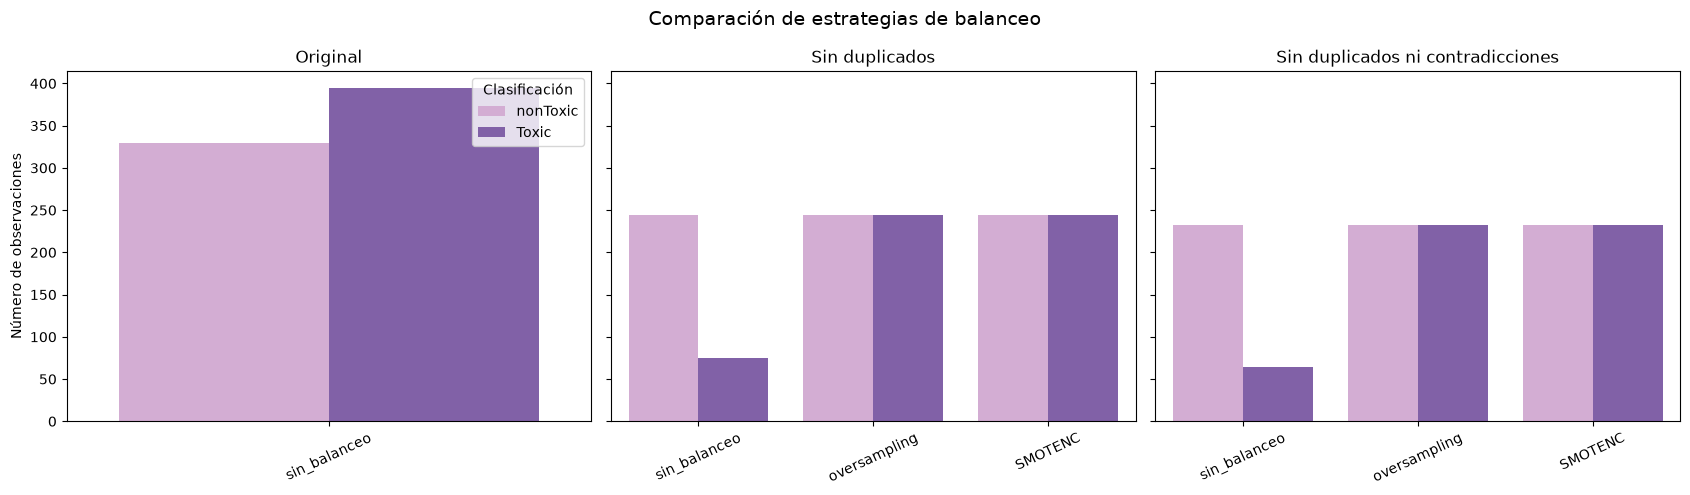

In [36]:
nombres = {
    "original": "Original",
    "sin_duplicados": "Sin duplicados",
    "sin_duplicados_ni_contradicciones":
        "Sin duplicados ni contradicciones"
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    sharey=True
)

for ax, estrategia_dup in zip(axes, estrategias):

    datos_grafica = resultados_balanceo[
        resultados_balanceo["Tratamiento duplicados"]
        == estrategia_dup
    ]

    datos_largos = datos_grafica.melt(
        id_vars="Balanceo",
        value_vars=["nonToxic", "Toxic"],
        var_name="Clase",
        value_name="Observaciones"
    )

    sns.barplot(
        data=datos_largos,
        x="Balanceo",
        y="Observaciones",
        hue="Clase",
        palette={
            "nonToxic": "#D9A7D9",
            "Toxic": "#8055B3"
        },
        ax=ax
    )

    ax.set_title(nombres[estrategia_dup])
    ax.set_xlabel("")
    ax.set_ylabel("Número de observaciones")
    ax.tick_params(axis="x", rotation=25)

    if ax != axes[0]:
        ax.get_legend().remove()

axes[0].legend(title="Clasificación")

plt.suptitle(
    "Comparación de estrategias de balanceo",
    fontsize=14
)

plt.tight_layout()
plt.show()

Los resultados confirmaron que el conjunto original presenta una distribución relativamente equilibrada, por lo que no se aplicó sobremuestreo. En cambio, las estrategias sin duplicados mostraron una proporción de observaciones tóxicas cercana al 22–24%. Tanto RandomOverSampler como SMOTENC lograron equilibrar ambas clases al 50%, aumentando el número de observaciones de la clase minoritaria. Aunque ambas técnicas produjeron distribuciones equivalentes, su efecto sobre el desempeño predictivo deberá evaluarse posteriormente mediante los modelos de clasificación.

### 6. Modelos tradicionales de Machine Learning

Se evaluarán tres algoritmos de clasificación: regresión logística, árbol de decisión y Support Vector Machine (SVM). Estos modelos servirán como referencia para comparar posteriormente el desempeño de métodos de ensamble y redes neuronales.

Para cada algoritmo se utilizarán las tres estrategias de representación de características y las siete configuraciones de tratamiento de duplicados y balanceo definidas anteriormente. La evaluación se realizará mediante validación cruzada estratificada por grupos, utilizando F1 de la clase tóxica como métrica principal, además de precisión, sensibilidad y F1-macro.

#### 6.1. Regresión logística

Se entrenará un clasificador de regresión logística para predecir la toxicidad de las nanopartículas. Se compararán las representaciones sin reducción, PCA y Mutual Information, junto con las estrategias de tratamiento de duplicados y balanceo.

Se utilizará inicialmente una configuración de hiperparámetros estándar, con el propósito de establecer una referencia antes de realizar ajustes de optimización.

##### 6.1.1. Construcción de pipelines

Se construirán tres pipelines de regresión logística, correspondientes a las representaciones sin reducción de dimensionalidad, PCA y Mutual Information. Cada pipeline incorporará el preprocesamiento necesario y el clasificador, permitiendo ajustar las transformaciones exclusivamente con los datos de entrenamiento.

In [37]:
# Representaciones definidas en la sección 4
representaciones = {
    "Sin reducción": preprocesamiento_base,
    "PCA": preprocesamiento_pca,
    "Mutual Information": preprocesamiento_mi
}

# Crear pipelines de regresión logística
pipelines_lr = {}

for nombre, preprocesador in representaciones.items():

    pipelines_lr[nombre] = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("modelo", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ])

print("Pipelines de regresión logística:")

for nombre in pipelines_lr:
    print("-", nombre)

Pipelines de regresión logística:
- Sin reducción
- PCA
- Mutual Information


##### 6.1.2. Evaluación inicial mediante validación cruzada

Se evaluarán las 21 configuraciones experimentales mediante cinco pliegues de validación cruzada estratificada por grupos. Para cada partición se aplicará el tratamiento de duplicados y, cuando corresponda, el balanceo de clases únicamente sobre los datos de entrenamiento.

Se calcularán F1, precisión, sensibilidad y F1-macro para comparar el desempeño de las distintas configuraciones de regresión logística.

In [38]:
# Configuraciones experimentales
configuraciones = [
    ("original", "sin_balanceo"),

    ("sin_duplicados", "sin_balanceo"),
    ("sin_duplicados", "oversampling"),
    ("sin_duplicados", "SMOTENC"),

    ("sin_duplicados_ni_contradicciones", "sin_balanceo"),
    ("sin_duplicados_ni_contradicciones", "oversampling"),
    ("sin_duplicados_ni_contradicciones", "SMOTENC")
]

resultados_lr = []

for estrategia_dup, balanceo in configuraciones:

    print(f"Evaluando: {estrategia_dup} | {balanceo}")

    for pliegue, (idx_train, idx_val) in enumerate(
        particiones_cv, 1
    ):

        # Separar entrenamiento y validación
        df_train = df.iloc[idx_train].copy()

        X_val = X.iloc[idx_val].copy()
        y_val = y.iloc[idx_val].copy()

        # Aplicar tratamiento de duplicados
        datos_train = tratar_duplicados(
            df_train,
            estrategia_dup
        )

        X_train = datos_train[X.columns].copy()
        y_train = datos_train["class"].map({
            "nonToxic": 0,
            "Toxic": 1
        }).astype(int)

        # Aplicar balanceo cuando corresponda
        if balanceo != "sin_balanceo":

            # Imputar antes del sobremuestreo
            X_train = X_train.copy()

            imputador = SimpleImputer(
                strategy="median"
            )

            X_train[variables_numericas] = (
                imputador.fit_transform(
                    X_train[variables_numericas]
                )
            )

            moda_np = X_train["NPs"].mode().iloc[0]
            X_train["NPs"] = X_train["NPs"].fillna(
                moda_np
            )

            sampler = clone(
                estrategias_balanceo[balanceo]
            )

            X_train, y_train = sampler.fit_resample(
                X_train,
                y_train
            )

        # Evaluar las tres representaciones
        for representacion, pipeline in pipelines_lr.items():

            modelo = clone(pipeline)

            modelo.fit(X_train, y_train)

            y_pred = modelo.predict(X_val)

            resultados_lr.append({
                "Modelo": "Regresión logística",
                "Tratamiento": estrategia_dup,
                "Balanceo": balanceo,
                "Representación": representacion,
                "Pliegue": pliegue,

                "F1": f1_score(
                    y_val, y_pred, zero_division=0
                ),

                "Precisión": precision_score(
                    y_val, y_pred, zero_division=0
                ),

                "Sensibilidad": recall_score(
                    y_val, y_pred, zero_division=0
                ),

                "F1-macro": f1_score(
                    y_val, y_pred,
                    average="macro",
                    zero_division=0
                )
            })

# Guardar resultados
resultados_lr = pd.DataFrame(resultados_lr)

print("\nEvaluaciones completadas:", len(resultados_lr))

display(resultados_lr.head())

Evaluando: original | sin_balanceo
Evaluando: sin_duplicados | sin_balanceo
Evaluando: sin_duplicados | oversampling
Evaluando: sin_duplicados | SMOTENC
Evaluando: sin_duplicados_ni_contradicciones | sin_balanceo
Evaluando: sin_duplicados_ni_contradicciones | oversampling
Evaluando: sin_duplicados_ni_contradicciones | SMOTENC

Evaluaciones completadas: 105


,Modelo,Tratamiento,Balanceo,Representación,Pliegue,F1,Precisión,Sensibilidad,F1-macro
0,Regresión logística,original,sin_balanceo,Sin reducción,1,0.602941,0.745455,0.506173,0.649785
1,Regresión logística,original,sin_balanceo,PCA,1,0.652482,0.766667,0.567901,0.684623
2,Regresión logística,original,sin_balanceo,Mutual Information,1,0.602941,0.745455,0.506173,0.649785
3,Regresión logística,original,sin_balanceo,Sin reducción,2,0.738255,0.846154,0.654762,0.739988
4,Regresión logística,original,sin_balanceo,PCA,2,0.709677,0.774648,0.654762,0.699666


##### 6.1.3. Comparación de resultados

Se comparará el desempeño promedio de las configuraciones de regresión logística, considerando principalmente el F1 de la clase tóxica. También se analizará la variabilidad entre pliegues y las métricas complementarias para identificar las configuraciones más prometedoras.

In [39]:
# Resumen de resultados por configuración
resumen_lr = (
    resultados_lr
    .groupby([
        "Tratamiento",
        "Balanceo",
        "Representación"
    ])
    .agg(
        F1_promedio=("F1", "mean"),
        F1_std=("F1", "std"),
        Precision=("Precisión", "mean"),
        Sensibilidad=("Sensibilidad", "mean"),
        F1_macro=("F1-macro", "mean")
    )
    .reset_index()
    .sort_values(
        "F1_promedio",
        ascending=False
    )
)

# Mostrar resultados ordenados
display(resumen_lr.round(4))

print("\nMejor configuración inicial:")
display(resumen_lr.head(1).round(4))

,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
14,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8097,0.0880,0.8418,0.7991,0.7936
5,sin_duplicados,SMOTENC,Sin reducción,0.7943,0.1090,0.8266,0.7890,0.7763
4,sin_duplicados,SMOTENC,PCA,0.7837,0.1085,0.8128,0.7768,0.7640
8,sin_duplicados,oversampling,Sin reducción,0.7831,0.0927,0.8254,0.7659,0.7704
1,original,sin_balanceo,PCA,0.7822,0.1033,0.7920,0.7958,0.7595
13,sin_duplicados_ni_contradicciones,SMOTENC,PCA,0.7810,0.1132,0.7978,0.7814,0.7616
3,sin_duplicados,SMOTENC,Mutual Information,0.7804,0.1181,0.8011,0.7935,0.7617
7,sin_duplicados,oversampling,PCA,0.7783,0.0964,0.8137,0.7659,0.7637
2,original,sin_balanceo,Sin reducción,0.7759,0.1194,0.8013,0.7788,0.7580
17,sin_duplicados_ni_contradicciones,oversampling,Sin reducción,0.7758,0.1179,0.8156,0.7657,0.7636



Mejor configuración inicial:


,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
14,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8097,0.088,0.8418,0.7991,0.7936


La regresión logística alcanzó su mejor desempeño utilizando el conjunto sin duplicados ni contradicciones, balanceado mediante SMOTENC y sin reducción de características, con un F1 promedio de 0.8097 ± 0.0880. La eliminación de duplicados sin balanceo redujo el desempeño, mientras que la incorporación de SMOTENC permitió mejorar la identificación de observaciones tóxicas. Asimismo, la representación sin reducción superó a PCA y Mutual Information en la mejor configuración, lo que sugiere que conservar todas las características puede resultar beneficioso para este modelo.

#### 6.2. Árbol de decisión

Se evaluará un clasificador basado en árboles de decisión para identificar relaciones no lineales entre las características de las nanopartículas y su toxicidad. Se compararán las tres representaciones de características junto con las estrategias de tratamiento de duplicados y balanceo.

El modelo se evaluará inicialmente sin optimización de hiperparámetros, utilizando las mismas particiones y métricas que en la regresión logística. Esto permitirá comparar ambos enfoques bajo condiciones equivalentes.

##### 6.2.1. Construcción de pipelines

Se construirán tres pipelines para el árbol de decisión, correspondientes a las representaciones sin reducción, PCA y Mutual Information. Se utilizará inicialmente un clasificador con parámetros predeterminados para establecer su desempeño de referencia.

In [40]:
# Crear pipelines del árbol de decisión
pipelines_dt = {}

for nombre, preprocesador in representaciones.items():

    pipelines_dt[nombre] = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("modelo", DecisionTreeClassifier(
            random_state=42
        ))
    ])

print("Pipelines del árbol de decisión:")

for nombre in pipelines_dt:
    print("-", nombre)

Pipelines del árbol de decisión:
- Sin reducción
- PCA
- Mutual Information


##### 6.2.2. Evaluación mediante validación cruzada

Se evaluarán las 21 configuraciones del árbol de decisión mediante los cinco pliegues de validación cruzada estratificada por grupos. En cada partición se aplicarán las estrategias de tratamiento de duplicados y balanceo correspondientes, y se calcularán las métricas F1, precisión, sensibilidad y F1-macro.

Los resultados permitirán identificar las configuraciones más prometedoras y compararlas posteriormente con la regresión logística.

In [41]:
resultados_dt = []

for estrategia_dup, balanceo in configuraciones:

    print(f"Evaluando: {estrategia_dup} | {balanceo}")

    for pliegue, (idx_train, idx_val) in enumerate(
        particiones_cv, 1
    ):

        # Separar entrenamiento y validación
        df_train = df.iloc[idx_train].copy()

        X_val = X.iloc[idx_val].copy()
        y_val = y.iloc[idx_val].copy()

        # Tratamiento de duplicados
        datos_train = tratar_duplicados(
            df_train,
            estrategia_dup
        )

        X_train = datos_train[X.columns].copy()

        y_train = datos_train["class"].map({
            "nonToxic": 0,
            "Toxic": 1
        }).astype(int)

        # Balanceo únicamente en entrenamiento
        if balanceo != "sin_balanceo":

            imputador = SimpleImputer(
                strategy="median"
            )

            X_train[variables_numericas] = (
                imputador.fit_transform(
                    X_train[variables_numericas]
                )
            )

            X_train["NPs"] = X_train["NPs"].fillna(
                X_train["NPs"].mode().iloc[0]
            )

            sampler = clone(
                estrategias_balanceo[balanceo]
            )

            X_train, y_train = sampler.fit_resample(
                X_train,
                y_train
            )

        # Evaluar representaciones
        for representacion, pipeline in pipelines_dt.items():

            modelo = clone(pipeline)
            modelo.fit(X_train, y_train)

            y_pred = modelo.predict(X_val)

            resultados_dt.append({
                "Modelo": "Árbol de decisión",
                "Tratamiento": estrategia_dup,
                "Balanceo": balanceo,
                "Representación": representacion,
                "Pliegue": pliegue,

                "F1": f1_score(
                    y_val, y_pred, zero_division=0
                ),

                "Precisión": precision_score(
                    y_val, y_pred, zero_division=0
                ),

                "Sensibilidad": recall_score(
                    y_val, y_pred, zero_division=0
                ),

                "F1-macro": f1_score(
                    y_val, y_pred,
                    average="macro",
                    zero_division=0
                )
            })

resultados_dt = pd.DataFrame(resultados_dt)

print("\nEvaluaciones completadas:", len(resultados_dt))

display(resultados_dt.head())

Evaluando: original | sin_balanceo
Evaluando: sin_duplicados | sin_balanceo
Evaluando: sin_duplicados | oversampling
Evaluando: sin_duplicados | SMOTENC
Evaluando: sin_duplicados_ni_contradicciones | sin_balanceo
Evaluando: sin_duplicados_ni_contradicciones | oversampling
Evaluando: sin_duplicados_ni_contradicciones | SMOTENC

Evaluaciones completadas: 105


,Modelo,Tratamiento,Balanceo,Representación,Pliegue,F1,Precisión,Sensibilidad,F1-macro
0,Árbol de decisión,original,sin_balanceo,Sin reducción,1,0.941935,0.986486,0.901235,0.942666
1,Árbol de decisión,original,sin_balanceo,PCA,1,0.528000,0.750000,0.407407,0.607915
2,Árbol de decisión,original,sin_balanceo,Mutual Information,1,0.915254,0.843750,1.000000,0.902883
3,Árbol de decisión,original,sin_balanceo,Sin reducción,2,0.727273,1.000000,0.571429,0.756494
4,Árbol de decisión,original,sin_balanceo,PCA,2,0.607143,0.607143,0.607143,0.553571


##### 6.2.3. Comparación de resultados

Se calcularán el promedio y la desviación estándar del F1 obtenido en los cinco pliegues para cada configuración. También se analizarán la precisión, la sensibilidad y el F1-macro, con el propósito de identificar el efecto de las estrategias de representación, balanceo y tratamiento de duplicados.

In [42]:
# Resumen de resultados por configuración
resumen_dt = (
    resultados_dt
    .groupby([
        "Tratamiento",
        "Balanceo",
        "Representación"
    ])
    .agg(
        F1_promedio=("F1", "mean"),
        F1_std=("F1", "std"),
        Precision=("Precisión", "mean"),
        Sensibilidad=("Sensibilidad", "mean"),
        F1_macro=("F1-macro", "mean")
    )
    .reset_index()
    .sort_values(
        "F1_promedio",
        ascending=False
    )
)

display(resumen_dt.round(4))

print("\nMejor configuración inicial:")
display(resumen_dt.head(1).round(4))

,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
5,sin_duplicados,SMOTENC,Sin reducción,0.8856,0.0662,0.9089,0.8735,0.8789
8,sin_duplicados,oversampling,Sin reducción,0.8855,0.0942,0.9074,0.8713,0.8826
14,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8848,0.0944,0.9239,0.8733,0.8831
20,sin_duplicados_ni_contradicciones,sin_balanceo,Sin reducción,0.8776,0.0705,0.9399,0.8391,0.8776
3,sin_duplicados,SMOTENC,Mutual Information,0.8737,0.0852,0.8703,0.8875,0.8600
2,original,sin_balanceo,Sin reducción,0.8725,0.0871,0.9252,0.8500,0.8684
17,sin_duplicados_ni_contradicciones,oversampling,Sin reducción,0.8635,0.0979,0.9153,0.8406,0.8638
18,sin_duplicados_ni_contradicciones,sin_balanceo,Mutual Information,0.8540,0.0691,0.8706,0.8479,0.8446
4,sin_duplicados,SMOTENC,PCA,0.8516,0.0929,0.8668,0.8549,0.8437
11,sin_duplicados,sin_balanceo,Sin reducción,0.8514,0.0690,0.9164,0.8026,0.8511



Mejor configuración inicial:


,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
5,sin_duplicados,SMOTENC,Sin reducción,0.8856,0.0662,0.9089,0.8735,0.8789


El árbol de decisión alcanzó su mejor desempeño utilizando el conjunto sin duplicados, balanceado mediante SMOTENC y sin reducción de características, con un F1 promedio de 0.8856 ± 0.0662. Este resultado superó al obtenido por la regresión logística. Además, RandomOverSampler presentó un desempeño prácticamente equivalente al de SMOTENC, mientras que algunas configuraciones sin balanceo también resultaron competitivas. La representación sin reducción obtuvo los mejores resultados, seguida de Mutual Information, lo que sugiere que conservar las características originales favorece la clasificación mediante árboles de decisión.

#### 6.3. Support Vector Machine (SVM)

Se evaluará un clasificador Support Vector Machine (SVM) con kernel RBF para identificar posibles relaciones no lineales entre las características de las nanopartículas y su toxicidad. Se compararán las tres representaciones de características y las siete configuraciones de tratamiento de duplicados y balanceo. El modelo se evaluará inicialmente con hiperparámetros predeterminados, utilizando las mismas particiones y métricas que los clasificadores anteriores.

##### 6.3.1. Construcción de pipelines

Se construirán tres pipelines para SVM, correspondientes a las representaciones sin reducción, PCA y Mutual Information. Se utilizará un kernel RBF con parámetros iniciales predeterminados, con el propósito de establecer una referencia antes de realizar la optimización de hiperparámetros.

In [47]:
# Crear pipelines de SVM
pipelines_svm = {}

for nombre, preprocesador in representaciones.items():

    pipelines_svm[nombre] = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("modelo", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            random_state=42
        ))
    ])

print("Pipelines de SVM:")

for nombre in pipelines_svm:
    print("-", nombre)


Pipelines de SVM:
- Sin reducción
- PCA
- Mutual Information


##### 6.3.2. Evaluación mediante validación cruzada

Se evaluarán las 21 configuraciones de SVM mediante cinco pliegues de validación cruzada estratificada por grupos. El tratamiento de duplicados y el balanceo se aplicarán únicamente a los conjuntos de entrenamiento de cada partición, manteniendo intactos los datos de validación.

Se calcularán F1, precisión, sensibilidad y F1-macro para comparar las configuraciones e identificar las más prometedoras.

In [52]:
resultados_svm = []

for estrategia_dup, balanceo in configuraciones:

    print(f"Evaluando: {estrategia_dup} | {balanceo}")

    for pliegue, (idx_train, idx_val) in enumerate(
        particiones_cv, 1
    ):

        # Separar entrenamiento y validación
        df_train = df.iloc[idx_train].copy()

        X_val = X.iloc[idx_val].copy()
        y_val = y.iloc[idx_val].copy()

        # Tratamiento de duplicados
        datos_train = tratar_duplicados(
            df_train,
            estrategia_dup
        )

        X_train = datos_train[X.columns].copy()

        y_train = datos_train["class"].map({
            "nonToxic": 0,
            "Toxic": 1
        }).astype(int)

        # Balanceo solo en entrenamiento
        if balanceo != "sin_balanceo":

            X_train = X_train.copy()

            imputador = SimpleImputer(
                strategy="median"
            )

            X_train[variables_numericas] = (
                imputador.fit_transform(
                    X_train[variables_numericas]
                )
            )

            X_train["NPs"] = X_train["NPs"].fillna(
                X_train["NPs"].mode().iloc[0]
            )

            sampler = clone(
                estrategias_balanceo[balanceo]
            )

            X_train, y_train = sampler.fit_resample(
                X_train,
                y_train
            )

        # Evaluar las tres representaciones
        for representacion, pipeline in pipelines_svm.items():

            modelo = clone(pipeline)
            modelo.fit(X_train, y_train)

            y_pred = modelo.predict(X_val)

            resultados_svm.append({
                "Modelo": "SVM",
                "Tratamiento": estrategia_dup,
                "Balanceo": balanceo,
                "Representación": representacion,
                "Pliegue": pliegue,

                "F1": f1_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Precisión": precision_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Sensibilidad": recall_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "F1-macro": f1_score(
                    y_val, y_pred,
                    average="macro",
                    zero_division=0
                )
            })

# Guardar resultados
resultados_svm = pd.DataFrame(resultados_svm)

print("\nEvaluaciones completadas:", len(resultados_svm))

display(resultados_svm.head())

Evaluando: original | sin_balanceo
Evaluando: sin_duplicados | sin_balanceo
Evaluando: sin_duplicados | oversampling
Evaluando: sin_duplicados | SMOTENC
Evaluando: sin_duplicados_ni_contradicciones | sin_balanceo
Evaluando: sin_duplicados_ni_contradicciones | oversampling
Evaluando: sin_duplicados_ni_contradicciones | SMOTENC

Evaluaciones completadas: 105


,Modelo,Tratamiento,Balanceo,Representación,Pliegue,F1,Precisión,Sensibilidad,F1-macro
0,SVM,original,sin_balanceo,Sin reducción,1,0.920455,0.852632,1.000000,0.909503
1,SVM,original,sin_balanceo,PCA,1,0.863905,0.829545,0.901235,0.852642
2,SVM,original,sin_balanceo,Mutual Information,1,0.962963,0.962963,0.962963,0.961745
3,SVM,original,sin_balanceo,Sin reducción,2,0.754967,0.850746,0.678571,0.753322
4,SVM,original,sin_balanceo,PCA,2,0.760000,0.863636,0.678571,0.760000


##### 6.3.3. Comparación de resultados

Se resumirán los resultados de SVM mediante el promedio y la desviación estándar del F1 obtenido en los cinco pliegues. También se analizarán la precisión, sensibilidad y F1-macro para determinar el efecto de las distintas estrategias de tratamiento, balanceo y representación de características.

In [53]:
# Resumen de resultados por configuración
resumen_svm = (
    resultados_svm
    .groupby([
        "Tratamiento",
        "Balanceo",
        "Representación"
    ])
    .agg(
        F1_promedio=("F1", "mean"),
        F1_std=("F1", "std"),
        Precision=("Precisión", "mean"),
        Sensibilidad=("Sensibilidad", "mean"),
        F1_macro=("F1-macro", "mean")
    )
    .reset_index()
    .sort_values(
        "F1_promedio",
        ascending=False
    )
)

display(resumen_svm.round(4))

print("\nMejor configuración inicial:")
display(resumen_svm.head(1).round(4))

,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
8,sin_duplicados,oversampling,Sin reducción,0.9056,0.1095,0.9222,0.9013,0.9048
7,sin_duplicados,oversampling,PCA,0.9045,0.1069,0.9233,0.8990,0.9033
13,sin_duplicados_ni_contradicciones,SMOTENC,PCA,0.9043,0.0784,0.9090,0.9165,0.8957
17,sin_duplicados_ni_contradicciones,oversampling,Sin reducción,0.8986,0.1051,0.9120,0.8978,0.8962
14,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8972,0.0765,0.9021,0.9091,0.8876
16,sin_duplicados_ni_contradicciones,oversampling,PCA,0.8937,0.1038,0.9128,0.8856,0.8912
4,sin_duplicados,SMOTENC,PCA,0.8747,0.1137,0.8854,0.8848,0.8632
5,sin_duplicados,SMOTENC,Sin reducción,0.8729,0.1121,0.8816,0.8848,0.8615
2,original,sin_balanceo,Sin reducción,0.8713,0.0766,0.8566,0.9030,0.8527
0,original,sin_balanceo,Mutual Information,0.8681,0.1018,0.8567,0.8938,0.8461



Mejor configuración inicial:


,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
8,sin_duplicados,oversampling,Sin reducción,0.9056,0.1095,0.9222,0.9013,0.9048


SVM alcanzó su mejor desempeño utilizando el conjunto sin duplicados, balanceado mediante RandomOverSampler y sin reducción de características, con un F1 promedio de 0.9056 ± 0.1095. El balanceo mejoró considerablemente el desempeño respecto a las configuraciones sin sobremuestreo. Además, PCA obtuvo resultados prácticamente equivalentes a la representación original, mientras que Mutual Information presentó un desempeño menor. Aunque SVM superó a los otros modelos tradicionales, la variabilidad entre pliegues indica que será importante evaluar su estabilidad y capacidad de generalización.

#### 6.4. Comparación de los modelos tradicionales

Se compararán los resultados de regresión logística, árbol de decisión y SVM utilizando las métricas obtenidas durante la validación cruzada. Se identificarán las mejores configuraciones iniciales de cada modelo y se analizarán las diferencias de desempeño, considerando tanto el F1 promedio como su variabilidad entre pliegues.

Esta comparación servirá como referencia para evaluar posteriormente si los métodos de ensamble y las redes neuronales ofrecen mejoras predictivas.

In [54]:
# Recuperar mejor configuración de cada modelo
mejores_tradicionales = pd.concat([
    resumen_lr.head(1).assign(
        Modelo="Regresión logística"
    ),
    resumen_dt.head(1).assign(
        Modelo="Árbol de decisión"
    ),
    resumen_svm.head(1).assign(
        Modelo="SVM"
    )
], ignore_index=True)

# Ordenar columnas
columnas = [
    "Modelo",
    "Tratamiento",
    "Balanceo",
    "Representación",
    "F1_promedio",
    "F1_std",
    "Precision",
    "Sensibilidad",
    "F1_macro"
]

mejores_tradicionales = (
    mejores_tradicionales[columnas]
    .sort_values("F1_promedio", ascending=False)
)

display(mejores_tradicionales.round(4))

,Modelo,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
2,SVM,sin_duplicados,oversampling,Sin reducción,0.9056,0.1095,0.9222,0.9013,0.9048
1,Árbol de decisión,sin_duplicados,SMOTENC,Sin reducción,0.8856,0.0662,0.9089,0.8735,0.8789
0,Regresión logística,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8097,0.0880,0.8418,0.7991,0.7936


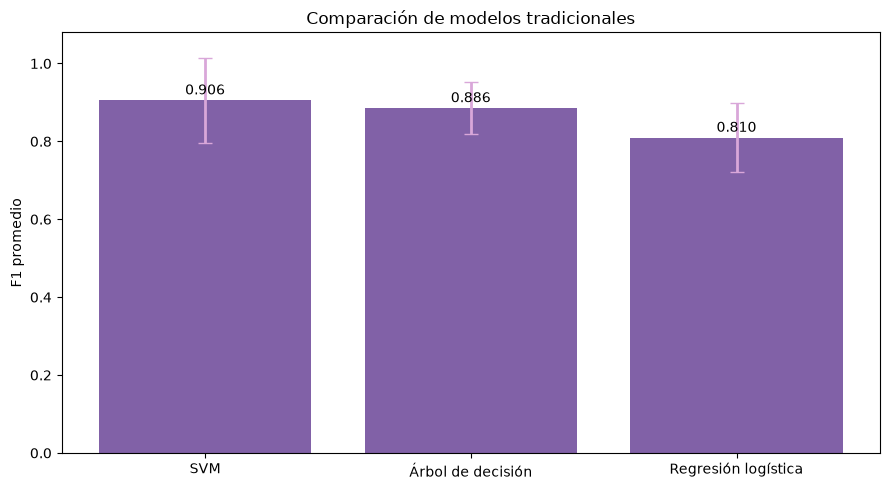

In [55]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=mejores_tradicionales,
    x="Modelo",
    y="F1_promedio",
    color="#8055B3"
)

# Mostrar valores y desviación estándar
for i, (_, fila) in enumerate(
    mejores_tradicionales.iterrows()
):
    ax.errorbar(
        i,
        fila["F1_promedio"],
        yerr=fila["F1_std"],
        fmt="none",
        color="#D9A7D9",
        capsize=5,
        linewidth=2
    )

    ax.text(
        i,
        fila["F1_promedio"] + 0.015,
        f'{fila["F1_promedio"]:.3f}',
        ha="center",
        fontsize=10
    )

plt.title("Comparación de modelos tradicionales")
plt.ylabel("F1 promedio")
plt.xlabel("")
plt.ylim(0, 1.08)
plt.tight_layout()
plt.show()

La comparación de los modelos tradicionales mostró que SVM obtuvo el mayor F1 promedio (0.9056), seguido del árbol de decisión (0.8856) y la regresión logística (0.8097). Estos resultados sugieren que las relaciones no lineales podrían ser importantes para predecir la toxicidad de las nanopartículas. Sin embargo, SVM presentó mayor variabilidad entre pliegues, mientras que el árbol de decisión mostró un desempeño más estable. Por lo tanto, será necesario considerar tanto el desempeño promedio como su variabilidad al comparar estos resultados con los modelos de ensamble.

### 7. Random Forest

Se evaluará Random Forest, un algoritmo de ensamble basado en múltiples árboles de decisión entrenados mediante *bagging* y selección aleatoria de características. Esta técnica permite combinar las predicciones de distintos árboles para reducir la varianza y mejorar la estabilidad del modelo.

Se compararán las tres representaciones de características y las siete configuraciones de tratamiento de duplicados y balanceo, utilizando las mismas particiones de validación cruzada que en los modelos tradicionales. Esto permitirá determinar si Random Forest ofrece mejoras respecto al árbol de decisión individual y SVM.

#### 7.1. Construcción de pipelines

Se construirán tres pipelines de Random Forest, correspondientes a las representaciones sin reducción, PCA y Mutual Information. Se utilizará inicialmente un ensamble de 200 árboles con parámetros estándar, con el propósito de establecer una referencia antes de realizar la optimización de hiperparámetros.

In [56]:
# Crear pipelines de Random Forest
pipelines_rf = {}

for nombre, preprocesador in representaciones.items():

    pipelines_rf[nombre] = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("modelo", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ])

print("Pipelines de Random Forest:")

for nombre in pipelines_rf:
    print("-", nombre)

Pipelines de Random Forest:
- Sin reducción
- PCA
- Mutual Information


#### 7.2. Evaluación mediante validación cruzada

Se evaluarán las 21 configuraciones de Random Forest mediante cinco pliegues de validación cruzada estratificada por grupos. Para cada partición, el tratamiento de duplicados y el balanceo se aplicarán exclusivamente sobre los datos de entrenamiento.

Se calcularán F1, precisión, sensibilidad y F1-macro para identificar las configuraciones más prometedoras y comparar su desempeño con los modelos tradicionales.

In [57]:
resultados_rf = []

for estrategia_dup, balanceo in configuraciones:

    print(f"Evaluando: {estrategia_dup} | {balanceo}")

    for pliegue, (idx_train, idx_val) in enumerate(
        particiones_cv, 1
    ):

        # Separar entrenamiento y validación
        df_train = df.iloc[idx_train].copy()

        X_val = X.iloc[idx_val].copy()
        y_val = y.iloc[idx_val].copy()

        # Tratamiento de duplicados
        datos_train = tratar_duplicados(
            df_train,
            estrategia_dup
        )

        X_train = datos_train[X.columns].copy()

        y_train = datos_train["class"].map({
            "nonToxic": 0,
            "Toxic": 1
        }).astype(int)

        # Balanceo únicamente en entrenamiento
        if balanceo != "sin_balanceo":

            X_train = X_train.copy()

            imputador = SimpleImputer(
                strategy="median"
            )

            X_train[variables_numericas] = (
                imputador.fit_transform(
                    X_train[variables_numericas]
                )
            )

            X_train["NPs"] = X_train["NPs"].fillna(
                X_train["NPs"].mode().iloc[0]
            )

            sampler = clone(
                estrategias_balanceo[balanceo]
            )

            X_train, y_train = sampler.fit_resample(
                X_train,
                y_train
            )

        # Evaluar las tres representaciones
        for representacion, pipeline in pipelines_rf.items():

            modelo = clone(pipeline)

            modelo.fit(X_train, y_train)

            y_pred = modelo.predict(X_val)

            resultados_rf.append({
                "Modelo": "Random Forest",
                "Tratamiento": estrategia_dup,
                "Balanceo": balanceo,
                "Representación": representacion,
                "Pliegue": pliegue,

                "F1": f1_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Precisión": precision_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Sensibilidad": recall_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "F1-macro": f1_score(
                    y_val, y_pred,
                    average="macro",
                    zero_division=0
                )
            })

# Guardar resultados
resultados_rf = pd.DataFrame(resultados_rf)

print("\nEvaluaciones completadas:", len(resultados_rf))

display(resultados_rf.head())

Evaluando: original | sin_balanceo
Evaluando: sin_duplicados | sin_balanceo
Evaluando: sin_duplicados | oversampling
Evaluando: sin_duplicados | SMOTENC
Evaluando: sin_duplicados_ni_contradicciones | sin_balanceo
Evaluando: sin_duplicados_ni_contradicciones | oversampling
Evaluando: sin_duplicados_ni_contradicciones | SMOTENC

Evaluaciones completadas: 105


,Modelo,Tratamiento,Balanceo,Representación,Pliegue,F1,Precisión,Sensibilidad,F1-macro
0,Random Forest,original,sin_balanceo,Sin reducción,1,0.879518,0.858824,0.901235,0.872191
1,Random Forest,original,sin_balanceo,PCA,1,0.616541,0.788462,0.506173,0.667387
2,Random Forest,original,sin_balanceo,Mutual Information,1,0.981818,0.964286,1.000000,0.980842
3,Random Forest,original,sin_balanceo,Sin reducción,2,0.791667,0.950000,0.678571,0.799679
4,Random Forest,original,sin_balanceo,PCA,2,0.728571,0.910714,0.607143,0.745536


#### 7.3. Comparación de resultados

Se comparará el desempeño de las configuraciones de Random Forest mediante el F1 promedio y su desviación estándar entre pliegues. También se analizarán la precisión, sensibilidad y F1-macro para determinar el efecto de las estrategias de tratamiento de duplicados, balanceo y representación de características.

In [58]:
# Resumen de resultados por configuración
resumen_rf = (
    resultados_rf
    .groupby([
        "Tratamiento",
        "Balanceo",
        "Representación"
    ])
    .agg(
        F1_promedio=("F1", "mean"),
        F1_std=("F1", "std"),
        Precision=("Precisión", "mean"),
        Sensibilidad=("Sensibilidad", "mean"),
        F1_macro=("F1-macro", "mean")
    )
    .reset_index()
    .sort_values(
        "F1_promedio",
        ascending=False
    )
)

display(resumen_rf.round(4))

print("\nMejor configuración inicial:")
display(resumen_rf.head(1).round(4))

,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
0,original,sin_balanceo,Mutual Information,0.8960,0.0930,0.8836,0.9169,0.8845
2,original,sin_balanceo,Sin reducción,0.8855,0.0755,0.8867,0.9022,0.8722
3,sin_duplicados,SMOTENC,Mutual Information,0.8809,0.0896,0.8739,0.9048,0.8660
5,sin_duplicados,SMOTENC,Sin reducción,0.8761,0.0712,0.8959,0.8790,0.8652
4,sin_duplicados,SMOTENC,PCA,0.8748,0.0764,0.8750,0.8826,0.8654
15,sin_duplicados_ni_contradicciones,oversampling,Mutual Information,0.8747,0.0829,0.8539,0.9096,0.8566
8,sin_duplicados,oversampling,Sin reducción,0.8724,0.0774,0.8850,0.8720,0.8616
6,sin_duplicados,oversampling,Mutual Information,0.8705,0.0965,0.8640,0.8882,0.8536
12,sin_duplicados_ni_contradicciones,SMOTENC,Mutual Information,0.8688,0.0808,0.8666,0.8876,0.8528
11,sin_duplicados,sin_balanceo,Sin reducción,0.8686,0.0755,0.9094,0.8488,0.8625



Mejor configuración inicial:


,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
0,original,sin_balanceo,Mutual Information,0.896,0.093,0.8836,0.9169,0.8845


Random Forest alcanzó su mejor desempeño utilizando el conjunto original, sin balanceo y con selección de características mediante Mutual Information, obteniendo un F1 promedio de 0.8960 ± 0.0930. A diferencia de los modelos anteriores, el tratamiento de duplicados y el balanceo no mejoraron su mejor resultado. Asimismo, Mutual Information superó ligeramente a la representación sin reducción, mientras que PCA presentó un desempeño inferior. Aunque Random Forest superó al árbol de decisión individual, no logró superar a SVM. Estos resultados sugieren que la complejidad adicional de un ensamble no garantiza necesariamente un mejor desempeño predictivo.

### 8. XGBoost

Se evaluará XGBoost, un algoritmo de ensamble basado en *gradient boosting*, que construye árboles de decisión secuencialmente para corregir los errores de los modelos anteriores.

Se compararán las tres representaciones de características y las siete configuraciones de tratamiento de duplicados y balanceo, utilizando las mismas particiones de validación cruzada que en los modelos anteriores. Esto permitirá analizar si XGBoost ofrece mejoras respecto a Random Forest y los clasificadores tradicionales.

#### 8.1. Construcción de pipelines

Se construirán tres pipelines de XGBoost, correspondientes a las representaciones sin reducción, PCA y Mutual Information. Se utilizará inicialmente una configuración fija de hiperparámetros, sin realizar todavía una búsqueda de optimización.

El preprocesamiento se ajustará exclusivamente sobre los datos de entrenamiento de cada pliegue, manteniendo las mismas condiciones de evaluación que en los modelos anteriores.

In [60]:
# Crear pipelines de XGBoost
pipelines_xgb = {}

for nombre, preprocesador in representaciones.items():

    pipelines_xgb[nombre] = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("modelo", XGBClassifier(
            n_estimators=200,
            max_depth=6,
            learning_rate=0.1,
            subsample=1.0,
            colsample_bytree=1.0,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ))
    ])

print("Pipelines de XGBoost:")

for nombre in pipelines_xgb:
    print("-", nombre)

Pipelines de XGBoost:
- Sin reducción
- PCA
- Mutual Information


#### 8.2. Evaluación mediante validación cruzada

Se evaluarán las 21 configuraciones de XGBoost mediante cinco pliegues de validación cruzada estratificada por grupos. Para cada partición, el tratamiento de duplicados y el balanceo se aplicarán únicamente sobre el conjunto de entrenamiento, manteniendo intactos los datos de validación.

Se calcularán F1, precisión, sensibilidad y F1-macro para identificar las configuraciones más prometedoras y compararlas con los modelos evaluados anteriormente.

In [61]:
resultados_xgb = []

for estrategia_dup, balanceo in configuraciones:

    print(f"Evaluando: {estrategia_dup} | {balanceo}")

    for pliegue, (idx_train, idx_val) in enumerate(
        particiones_cv, 1
    ):

        # Separar entrenamiento y validación
        df_train = df.iloc[idx_train].copy()

        X_val = X.iloc[idx_val].copy()
        y_val = y.iloc[idx_val].copy()

        # Tratamiento de duplicados
        datos_train = tratar_duplicados(
            df_train,
            estrategia_dup
        )

        X_train = datos_train[X.columns].copy()

        y_train = datos_train["class"].map({
            "nonToxic": 0,
            "Toxic": 1
        }).astype(int)

        # Balanceo únicamente en entrenamiento
        if balanceo != "sin_balanceo":

            X_train = X_train.copy()

            imputador = SimpleImputer(
                strategy="median"
            )

            X_train[variables_numericas] = (
                imputador.fit_transform(
                    X_train[variables_numericas]
                )
            )

            X_train["NPs"] = X_train["NPs"].fillna(
                X_train["NPs"].mode().iloc[0]
            )

            sampler = clone(
                estrategias_balanceo[balanceo]
            )

            X_train, y_train = sampler.fit_resample(
                X_train,
                y_train
            )

        # Evaluar las tres representaciones
        for representacion, pipeline in pipelines_xgb.items():

            modelo = clone(pipeline)

            modelo.fit(X_train, y_train)

            y_pred = modelo.predict(X_val)

            resultados_xgb.append({
                "Modelo": "XGBoost",
                "Tratamiento": estrategia_dup,
                "Balanceo": balanceo,
                "Representación": representacion,
                "Pliegue": pliegue,

                "F1": f1_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Precisión": precision_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Sensibilidad": recall_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "F1-macro": f1_score(
                    y_val, y_pred,
                    average="macro",
                    zero_division=0
                )
            })

# Guardar resultados
resultados_xgb = pd.DataFrame(resultados_xgb)

print("\nEvaluaciones completadas:", len(resultados_xgb))

display(resultados_xgb.head())

Evaluando: original | sin_balanceo
Evaluando: sin_duplicados | sin_balanceo
Evaluando: sin_duplicados | oversampling
Evaluando: sin_duplicados | SMOTENC
Evaluando: sin_duplicados_ni_contradicciones | sin_balanceo
Evaluando: sin_duplicados_ni_contradicciones | oversampling
Evaluando: sin_duplicados_ni_contradicciones | SMOTENC

Evaluaciones completadas: 105


,Modelo,Tratamiento,Balanceo,Representación,Pliegue,F1,Precisión,Sensibilidad,F1-macro
0,XGBoost,original,sin_balanceo,Sin reducción,1,0.935897,0.973333,0.901235,0.936303
1,XGBoost,original,sin_balanceo,PCA,1,0.616541,0.788462,0.506173,0.667387
2,XGBoost,original,sin_balanceo,Mutual Information,1,0.975000,0.987342,0.962963,0.974513
3,XGBoost,original,sin_balanceo,Sin reducción,2,0.802817,0.982759,0.678571,0.812801
4,XGBoost,original,sin_balanceo,PCA,2,0.780822,0.919355,0.678571,0.786515


#### 8.3. Comparación de resultados

Se compararán las configuraciones de XGBoost mediante el F1 promedio y su desviación estándar entre pliegues. También se analizarán la precisión, sensibilidad y F1-macro para determinar el efecto de las estrategias de tratamiento de duplicados, balanceo y representación de características.

Los resultados se utilizarán para identificar las configuraciones más prometedoras antes de realizar la optimización de hiperparámetros.

In [62]:
# Resumen de resultados por configuración
resumen_xgb = (
    resultados_xgb
    .groupby([
        "Tratamiento",
        "Balanceo",
        "Representación"
    ])
    .agg(
        F1_promedio=("F1", "mean"),
        F1_std=("F1", "std"),
        Precision=("Precisión", "mean"),
        Sensibilidad=("Sensibilidad", "mean"),
        F1_macro=("F1-macro", "mean")
    )
    .reset_index()
    .sort_values(
        "F1_promedio",
        ascending=False
    )
)

display(resumen_xgb.round(4))

print("\nMejor configuración inicial:")
display(resumen_xgb.head(1).round(4))

,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
2,original,sin_balanceo,Sin reducción,0.9056,0.0691,0.9200,0.9091,0.8977
14,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8992,0.0690,0.9254,0.8927,0.8899
0,original,sin_balanceo,Mutual Information,0.8962,0.0834,0.9086,0.8924,0.8886
5,sin_duplicados,SMOTENC,Sin reducción,0.8962,0.0690,0.9310,0.8838,0.8874
8,sin_duplicados,oversampling,Sin reducción,0.8960,0.0698,0.9234,0.8838,0.8902
11,sin_duplicados,sin_balanceo,Sin reducción,0.8905,0.0724,0.9130,0.8838,0.8824
18,sin_duplicados_ni_contradicciones,sin_balanceo,Mutual Information,0.8876,0.0675,0.9238,0.8663,0.8823
12,sin_duplicados_ni_contradicciones,SMOTENC,Mutual Information,0.8838,0.0944,0.8965,0.8851,0.8698
4,sin_duplicados,SMOTENC,PCA,0.8786,0.0974,0.8902,0.8734,0.8705
17,sin_duplicados_ni_contradicciones,oversampling,Sin reducción,0.8747,0.0710,0.8995,0.8647,0.8646



Mejor configuración inicial:


,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
2,original,sin_balanceo,Sin reducción,0.9056,0.0691,0.92,0.9091,0.8977


XGBoost alcanzó su mejor desempeño utilizando el conjunto original, sin balanceo ni reducción de características, con un F1 promedio de 0.9056 ± 0.0691. Las estrategias de eliminación de duplicados y balanceo mediante SMOTENC produjeron resultados cercanos, aunque ligeramente inferiores. Asimismo, conservar todas las características permitió obtener el mejor desempeño, seguido de Mutual Information, mientras que PCA presentó resultados menores. En comparación con los modelos anteriores, XGBoost igualó el F1 promedio de SVM en las cifras reportadas, pero mostró una menor variabilidad entre pliegues.

### 9. Red neuronal multicapa (MLP)

Se evaluará una red neuronal multicapa (MLP) como representante de los métodos de aprendizaje profundo. Este modelo permite aprender relaciones no lineales entre las características fisicoquímicas de las nanopartículas y su toxicidad mediante capas de neuronas interconectadas.

Se compararán las mismas tres representaciones de características y siete configuraciones de tratamiento de duplicados y balanceo utilizadas en los modelos anteriores. Esto permitirá determinar si una arquitectura neuronal ofrece ventajas frente a los modelos tradicionales y de ensamble.

Cabse señaral que aunque se incluirá MLP para comparar su desempeño con los modelos tradicionales, no se espera necesariamente que obtenga los mejores resultados. Esto se debe principalmente al tamaño reducido del conjunto de datos y a que los modelos de *deep learning* suelen requerir mayores cantidades de información para aprovechar su capacidad de aprendizaje. Además, en problemas con datos tabulares, los métodos tradicionales de *machine learning*, especialmente los basados en árboles y ensambles, suelen ofrecer resultados competitivos e incluso superiores a las redes neuronales. Por ello, MLP se utilizará principalmente como un modelo de comparación para evaluar si una mayor complejidad se traduce en un mejor desempeño predictivo.

#### 9.1. Construcción de pipelines

Se construirán tres pipelines de MLP, correspondientes a las representaciones sin reducción, PCA y Mutual Information. Se utilizará inicialmente una arquitectura de dos capas ocultas, con 64 y 32 neuronas respectivamente, activación ReLU y optimizador Adam.

Se incorporará detención temprana para limitar el sobreajuste y reducir el tiempo de entrenamiento. La arquitectura se mantendrá fija durante esta evaluación inicial y podrá ajustarse posteriormente mediante optimización de hiperparámetros.

In [63]:
# Crear pipelines de MLP
pipelines_mlp = {}

for nombre, preprocesador in representaciones.items():

    pipelines_mlp[nombre] = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("modelo", MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            alpha=0.001,
            learning_rate_init=0.001,
            max_iter=500,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=20,
            random_state=42
        ))
    ])

print("Pipelines de MLP:")

for nombre in pipelines_mlp:
    print("-", nombre)

Pipelines de MLP:
- Sin reducción
- PCA
- Mutual Information


#### 9.2. Evaluación mediante validación cruzada

Se evaluarán las 21 configuraciones de MLP mediante cinco pliegues de validación cruzada estratificada por grupos. Para cada partición, el tratamiento de duplicados y el balanceo se aplicarán exclusivamente sobre los datos de entrenamiento. Se calcularán F1, precisión, sensibilidad y F1-macro para comparar el desempeño de la red neuronal con los modelos tradicionales y de ensamble.

In [64]:
resultados_mlp = []

for estrategia_dup, balanceo in configuraciones:

    print(f"Evaluando: {estrategia_dup} | {balanceo}")

    for pliegue, (idx_train, idx_val) in enumerate(
        particiones_cv, 1
    ):

        # Separar entrenamiento y validación
        df_train = df.iloc[idx_train].copy()

        X_val = X.iloc[idx_val].copy()
        y_val = y.iloc[idx_val].copy()

        # Tratamiento de duplicados
        datos_train = tratar_duplicados(
            df_train,
            estrategia_dup
        )

        X_train = datos_train[X.columns].copy()

        y_train = datos_train["class"].map({
            "nonToxic": 0,
            "Toxic": 1
        }).astype(int)

        # Balanceo únicamente en entrenamiento
        if balanceo != "sin_balanceo":

            X_train = X_train.copy()

            imputador = SimpleImputer(
                strategy="median"
            )

            X_train[variables_numericas] = (
                imputador.fit_transform(
                    X_train[variables_numericas]
                )
            )

            X_train["NPs"] = X_train["NPs"].fillna(
                X_train["NPs"].mode().iloc[0]
            )

            sampler = clone(
                estrategias_balanceo[balanceo]
            )

            X_train, y_train = sampler.fit_resample(
                X_train,
                y_train
            )

        # Evaluar las tres representaciones
        for representacion, pipeline in pipelines_mlp.items():

            modelo = clone(pipeline)

            modelo.fit(X_train, y_train)

            y_pred = modelo.predict(X_val)

            resultados_mlp.append({
                "Modelo": "MLP",
                "Tratamiento": estrategia_dup,
                "Balanceo": balanceo,
                "Representación": representacion,
                "Pliegue": pliegue,

                "F1": f1_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Precisión": precision_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "Sensibilidad": recall_score(
                    y_val, y_pred,
                    zero_division=0
                ),

                "F1-macro": f1_score(
                    y_val, y_pred,
                    average="macro",
                    zero_division=0
                )
            })

# Guardar resultados
resultados_mlp = pd.DataFrame(resultados_mlp)

print("\nEvaluaciones completadas:", len(resultados_mlp))

display(resultados_mlp.head())

Evaluando: original | sin_balanceo
Evaluando: sin_duplicados | sin_balanceo
Evaluando: sin_duplicados | oversampling
Evaluando: sin_duplicados | SMOTENC
Evaluando: sin_duplicados_ni_contradicciones | sin_balanceo
Evaluando: sin_duplicados_ni_contradicciones | oversampling
Evaluando: sin_duplicados_ni_contradicciones | SMOTENC

Evaluaciones completadas: 105


,Modelo,Tratamiento,Balanceo,Representación,Pliegue,F1,Precisión,Sensibilidad,F1-macro
0,MLP,original,sin_balanceo,Sin reducción,1,0.784314,0.833333,0.740741,0.789672
1,MLP,original,sin_balanceo,PCA,1,0.661871,0.793103,0.567901,0.696650
2,MLP,original,sin_balanceo,Mutual Information,1,0.672000,0.954545,0.518519,0.727534
3,MLP,original,sin_balanceo,Sin reducción,2,0.739130,0.944444,0.607143,0.758454
4,MLP,original,sin_balanceo,PCA,2,0.774648,0.948276,0.654762,0.786058


#### 9.3. Comparación de resultados

Se comparará el desempeño de las configuraciones de MLP mediante el F1 promedio y su desviación estándar entre pliegues. También se analizarán la precisión, sensibilidad y F1-macro para determinar el efecto de las estrategias de tratamiento de duplicados, balanceo y representación de características.

Los resultados permitirán investigar si la red neuronal ofrece mejoras respecto a los modelos tradicionales y de ensamble, considerando también la complejidad computacional de su entrenamiento.

In [66]:
# Resumen de resultados por configuración
resumen_mlp = (
    resultados_mlp
    .groupby([
        "Tratamiento",
        "Balanceo",
        "Representación"
    ])
    .agg(
        F1_promedio=("F1", "mean"),
        F1_std=("F1", "std"),
        Precision=("Precisión", "mean"),
        Sensibilidad=("Sensibilidad", "mean"),
        F1_macro=("F1-macro", "mean")
    )
    .reset_index()
    .sort_values(
        "F1_promedio",
        ascending=False
    )
)

display(resumen_mlp.round(4))

print("\nMejor configuración inicial:")
display(resumen_mlp.head(1).round(4))

,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
5,sin_duplicados,SMOTENC,Sin reducción,0.8625,0.0894,0.8807,0.8575,0.8538
14,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8561,0.0942,0.8394,0.8888,0.8361
2,original,sin_balanceo,Sin reducción,0.8403,0.1020,0.8613,0.8472,0.8228
1,original,sin_balanceo,PCA,0.8366,0.1303,0.8658,0.8376,0.8282
13,sin_duplicados_ni_contradicciones,SMOTENC,PCA,0.8290,0.1059,0.8522,0.8332,0.8109
16,sin_duplicados_ni_contradicciones,oversampling,PCA,0.8123,0.1074,0.8454,0.7959,0.8042
0,original,sin_balanceo,Mutual Information,0.8118,0.1181,0.8759,0.7861,0.8087
17,sin_duplicados_ni_contradicciones,oversampling,Sin reducción,0.8116,0.1549,0.8073,0.8392,0.7953
3,sin_duplicados,SMOTENC,Mutual Information,0.8106,0.1273,0.8656,0.7911,0.8034
8,sin_duplicados,oversampling,Sin reducción,0.7950,0.1794,0.8136,0.8188,0.7762



Mejor configuración inicial:


,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
5,sin_duplicados,SMOTENC,Sin reducción,0.8625,0.0894,0.8807,0.8575,0.8538


MLP alcanzó su mejor desempeño utilizando el conjunto sin duplicados, balanceado mediante SMOTENC y sin reducción de características, obteniendo un F1 promedio de 0.8625 ± 0.0894. El balanceo resultó especialmente importante, ya que las configuraciones sin duplicados y sin balanceo presentaron una disminución considerable en el desempeño. Asimismo, conservar todas las características permitió obtener el mejor resultado. Aunque la red neuronal mostró una capacidad predictiva competitiva, no logró superar a los mejores modelos tradicionales y de ensamble. Esto sugiere que, para este conjunto de datos tabulares de tamaño reducido, una mayor complejidad del modelo no necesariamente se traduce en un mejor desempeño.

### 10. Comparación general de modelos

Se compararán los resultados iniciales de los seis algoritmos evaluados: regresión logística, árbol de decisión, SVM, Random Forest, XGBoost y MLP.

El análisis se centrará en el F1 promedio y su desviación estándar entre los cinco pliegues de validación cruzada, considerando también la precisión, sensibilidad y F1-macro. Además, se examinará cómo influyen las estrategias de tratamiento de duplicados, balanceo y representación de características en el desempeño de los modelos. Esta comparación permitirá identificar los algoritmos y configuraciones más prometedores para la posterior optimización de hiperparámetros.

#### 10.1. Comparación del desempeño predictivo

Se identificarán las configuraciones con mayor F1 promedio de cada modelo y se compararán sus métricas de evaluación. También se visualizará la variabilidad entre pliegues mediante barras de error, con el propósito de analizar tanto el desempeño predictivo como su estabilidad.

In [67]:
# Reunir los resúmenes de los seis modelos
resumenes = {
    "Regresión logística": resumen_lr,
    "Árbol de decisión": resumen_dt,
    "SVM": resumen_svm,
    "Random Forest": resumen_rf,
    "XGBoost": resumen_xgb,
    "MLP": resumen_mlp
}

# Obtener la mejor configuración de cada modelo
mejores_modelos = []

for nombre, resumen in resumenes.items():

    mejor = resumen.loc[
        resumen["F1_promedio"].idxmax()
    ].copy()

    mejor["Modelo"] = nombre
    mejores_modelos.append(mejor)

comparacion_modelos = pd.DataFrame(
    mejores_modelos
)

# Ordenar por F1 promedio
comparacion_modelos = (
    comparacion_modelos
    .sort_values(
        "F1_promedio",
        ascending=False
    )
    .reset_index(drop=True)
)

columnas = [
    "Modelo",
    "Tratamiento",
    "Balanceo",
    "Representación",
    "F1_promedio",
    "F1_std",
    "Precision",
    "Sensibilidad",
    "F1_macro"
]

display(
    comparacion_modelos[columnas].round(4)
)

,Modelo,Tratamiento,Balanceo,Representación,F1_promedio,F1_std,Precision,Sensibilidad,F1_macro
0,SVM,sin_duplicados,oversampling,Sin reducción,0.9056,0.1095,0.9222,0.9013,0.9048
1,XGBoost,original,sin_balanceo,Sin reducción,0.9056,0.0691,0.9200,0.9091,0.8977
2,Random Forest,original,sin_balanceo,Mutual Information,0.8960,0.0930,0.8836,0.9169,0.8845
3,Árbol de decisión,sin_duplicados,SMOTENC,Sin reducción,0.8856,0.0662,0.9089,0.8735,0.8789
4,MLP,sin_duplicados,SMOTENC,Sin reducción,0.8625,0.0894,0.8807,0.8575,0.8538
5,Regresión logística,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8097,0.0880,0.8418,0.7991,0.7936


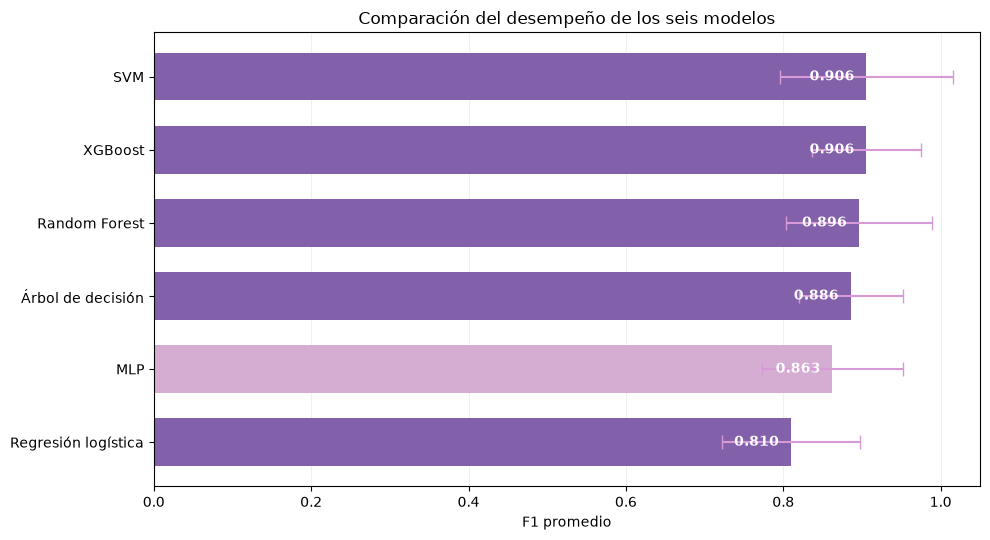

In [68]:
# Ordenar para visualización horizontal
datos = comparacion_modelos.sort_values(
    "F1_promedio",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 5.5))

colores = [
    "#D5ADD3" if modelo == "MLP" else "#8260AA"
    for modelo in datos["Modelo"]
]

barras = ax.barh(
    datos["Modelo"],
    datos["F1_promedio"],
    xerr=datos["F1_std"],
    color=colores,
    ecolor="#D89AD7",
    capsize=5,
    height=0.65
)

# Etiquetas de valores
for barra, valor in zip(
    barras,
    datos["F1_promedio"]
):
    ax.text(
        valor - 0.015,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.3f}",
        va="center",
        ha="right",
        color="white",
        fontweight="bold"
    )

ax.set_xlim(0, 1.05)
ax.set_xlabel("F1 promedio")
ax.set_title(
    "Comparación del desempeño de los seis modelos"
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Los resultados mostraron que SVM y XGBoost alcanzaron el mayor F1 promedio (0.9056), aunque XGBoost presentó una menor variabilidad entre pliegues. Random Forest y el árbol de decisión también obtuvieron resultados competitivos, mientras que MLP y regresión logística presentaron un desempeño inferior. En particular, la red neuronal no superó a los modelos tradicionales más destacados, lo que sugiere que una mayor complejidad no necesariamente implica una mejor capacidad predictiva en conjuntos de datos tabulares pequeños. No obstante, las diferencias observadas deberán interpretarse con cautela, ya que corresponden a las mejores configuraciones seleccionadas durante la evaluación inicial.

#### 10.2. Efecto del tratamiento de duplicados

Se analizará el desempeño de los seis modelos bajo las tres estrategias de tratamiento de datos: conjunto original, eliminación de duplicados y eliminación de duplicados junto con registros contradictorios.

Para facilitar la comparación, se utilizará inicialmente la representación sin reducción y sin balanceo, manteniendo constantes estas condiciones entre estrategias. Posteriormente, se podrán considerar las configuraciones balanceadas para distinguir el efecto de la eliminación de duplicados del efecto producido por el desbalance de clases.

In [69]:
# Unificar todos los resultados
resultados_todos = []

for nombre, resumen in resumenes.items():

    temporal = resumen.copy()
    temporal["Modelo"] = nombre

    resultados_todos.append(temporal)

resultados_todos = pd.concat(
    resultados_todos,
    ignore_index=True
)

# Mantener constantes representación y balanceo
comparacion_duplicados = resultados_todos[
    (resultados_todos["Representación"] == "Sin reducción") &
    (resultados_todos["Balanceo"] == "sin_balanceo")
].copy()

orden_tratamientos = [
    "original",
    "sin_duplicados",
    "sin_duplicados_ni_contradicciones"
]

tabla_duplicados = comparacion_duplicados.pivot(
    index="Modelo",
    columns="Tratamiento",
    values="F1_promedio"
)

tabla_duplicados = tabla_duplicados.reindex(
    columns=orden_tratamientos
)

display(tabla_duplicados.round(4))

Tratamiento,original,sin_duplicados,sin_duplicados_ni_contradicciones
Modelo,,,
MLP,0.8403,0.3693,0.5000
Random Forest,0.8855,0.8686,0.8613
Regresión logística,0.7759,0.6901,0.6966
SVM,0.8713,0.7867,0.7857
XGBoost,0.9056,0.8905,0.8549
Árbol de decisión,0.8725,0.8514,0.8776


La comparación mostró que la mayoría de los modelos disminuyeron su F1 promedio después de eliminar los registros duplicados. La reducción fue especialmente notable en MLP, mientras que Random Forest y XGBoost presentaron cambios relativamente pequeños. Por otra parte, eliminar adicionalmente los registros contradictorios no produjo mejoras consistentes entre los modelos.

Sin embargo, estos resultados no permiten atribuir las diferencias exclusivamente a los duplicados, ya que su eliminación también redujo considerablemente el tamaño del conjunto de entrenamiento y modificó la distribución de clases. Por ello, será necesario considerar el efecto del balanceo antes de establecer conclusiones definitivas sobre la influencia de los registros repetidos.

#### 10.3. Efecto de la representación de características

Se compararán las tres estrategias de representación de características: sin reducción, PCA y Mutual Information. Para cada modelo se mantendrán constantes el tratamiento de duplicados y el balanceo correspondientes a su mejor configuración inicial. De esta manera, se analizará cómo cambia el desempeño al modificar únicamente la representación de las características.

In [70]:
comparacion_representaciones = []

for _, mejor in comparacion_modelos.iterrows():

    modelo = mejor["Modelo"]

    subset = resultados_todos[
        (resultados_todos["Modelo"] == modelo) &
        (resultados_todos["Tratamiento"] == mejor["Tratamiento"]) &
        (resultados_todos["Balanceo"] == mejor["Balanceo"])
    ].copy()

    comparacion_representaciones.append(subset)

comparacion_representaciones = pd.concat(
    comparacion_representaciones,
    ignore_index=True
)

tabla_representaciones = (
    comparacion_representaciones
    .pivot(
        index="Modelo",
        columns="Representación",
        values="F1_promedio"
    )
)

tabla_representaciones = tabla_representaciones[
    ["Sin reducción", "PCA", "Mutual Information"]
]

display(tabla_representaciones.round(4))

Representación,Sin reducción,PCA,Mutual Information
Modelo,,,
MLP,0.8625,0.7869,0.8106
Random Forest,0.8855,0.8236,0.8960
Regresión logística,0.8097,0.7810,0.7667
SVM,0.9056,0.9045,0.8556
XGBoost,0.9056,0.8373,0.8962
Árbol de decisión,0.8856,0.8516,0.8737


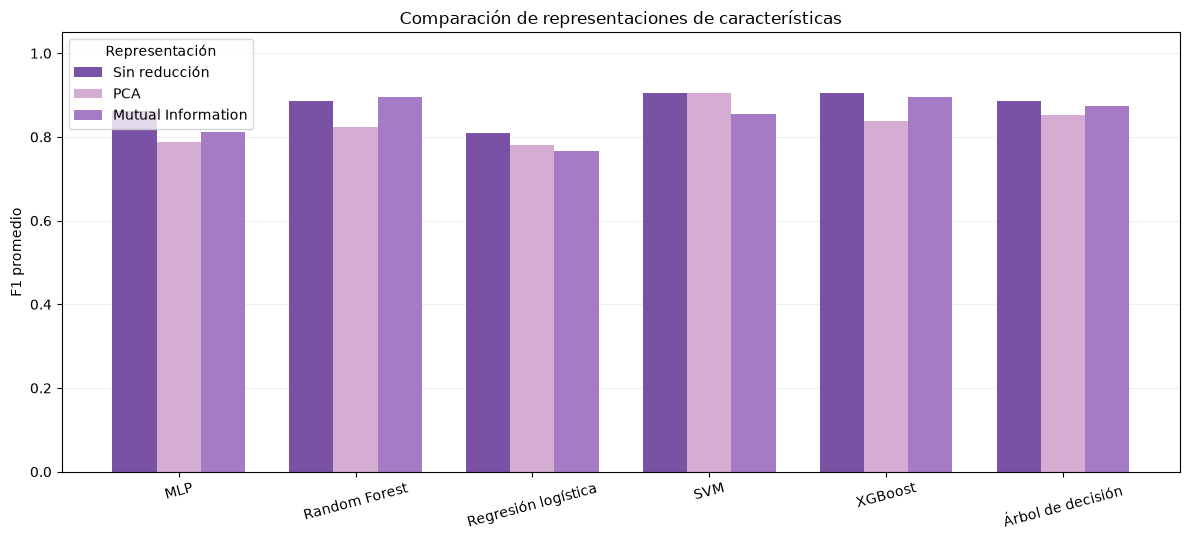

In [71]:
datos = tabla_representaciones

x = np.arange(len(datos.index))
ancho = 0.25

representaciones_nombres = [
    "Sin reducción",
    "PCA",
    "Mutual Information"
]

colores = [
    "#7952A6",
    "#D5ADD3",
    "#A67BC5"
]

fig, ax = plt.subplots(figsize=(12, 5.5))

for i, representacion in enumerate(
    representaciones_nombres
):

    ax.bar(
        x + (i - 1) * ancho,
        datos[representacion],
        width=ancho,
        label=representacion,
        color=colores[i]
    )

ax.set_xticks(x)
ax.set_xticklabels(datos.index, rotation=15)

ax.set_ylabel("F1 promedio")
ax.set_ylim(0, 1.05)

ax.set_title(
    "Comparación de representaciones de características"
)

ax.legend(title="Representación")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

La comparación mostró que conservar todas las características produjo el mejor desempeño en cinco de los seis modelos evaluados. La excepción fue Random Forest, que obtuvo una ligera mejora mediante Mutual Information. Por otro lado, PCA presentó resultados inferiores a la representación sin reducción en todos los modelos. Esto sugiere que, debido al número relativamente pequeño de variables predictoras, la reducción de dimensionalidad no necesariamente aporta ventajas. No obstante, Mutual Information permitió obtener resultados competitivos con menos características, lo que podría facilitar la interpretación y reducir la complejidad del modelo.

#### 10.4. Síntesis de resultados iniciales

Se resumirán los resultados de la evaluación inicial para identificar los modelos con mayor potencial predictivo. La selección considerará el F1 promedio, su variabilidad entre pliegues y la complejidad de los algoritmos.

Estos resultados servirán como referencia para la optimización de hiperparámetros. Las conclusiones definitivas sobre el desempeño y la capacidad de generalización se establecerán después de las evaluaciones adicionales.

In [72]:
# Resumen ordenado de los seis modelos
tabla_final = comparacion_modelos[
    [
        "Modelo",
        "Tratamiento",
        "Balanceo",
        "Representación",
        "F1_promedio",
        "F1_std"
    ]
].copy()

tabla_final["Ranking"] = range(
    1,
    len(tabla_final) + 1
)

tabla_final = tabla_final[
    [
        "Ranking",
        "Modelo",
        "Tratamiento",
        "Balanceo",
        "Representación",
        "F1_promedio",
        "F1_std"
    ]
]

display(tabla_final.round(4))

,Ranking,Modelo,Tratamiento,Balanceo,Representación,F1_promedio,F1_std
0,1,SVM,sin_duplicados,oversampling,Sin reducción,0.9056,0.1095
1,2,XGBoost,original,sin_balanceo,Sin reducción,0.9056,0.0691
2,3,Random Forest,original,sin_balanceo,Mutual Information,0.8960,0.0930
3,4,Árbol de decisión,sin_duplicados,SMOTENC,Sin reducción,0.8856,0.0662
4,5,MLP,sin_duplicados,SMOTENC,Sin reducción,0.8625,0.0894
5,6,Regresión logística,sin_duplicados_ni_contradicciones,SMOTENC,Sin reducción,0.8097,0.0880


La comparación inicial mostró que SVM y XGBoost obtuvieron el mayor F1 promedio (0.9056), aunque XGBoost presentó una menor variabilidad entre pliegues. Random Forest también alcanzó un desempeño competitivo (0.8960), mientras que el árbol de decisión, MLP y regresión logística obtuvieron resultados inferiores.

En general, conservar las características originales resultó favorable para la mayoría de los modelos, mientras que el efecto del tratamiento de duplicados y el balanceo dependió del algoritmo utilizado. A partir de estos resultados, se seleccionaron SVM, XGBoost y Random Forest para la optimización de hiperparámetros, con el propósito de investigar si es posible mejorar su desempeño predictivo.

### 11. Optimización de hiperparámetros

Después de la evaluación inicial, se optimizarán los hiperparámetros de SVM, Random Forest y XGBoost, seleccionados por su desempeño predictivo.

Se utilizará `RandomizedSearchCV` para explorar distintas combinaciones de hiperparámetros mediante validación cruzada estratificada por grupos, utilizando el F1 de la clase tóxica como métrica principal.

La búsqueda se realizará sobre las configuraciones de preprocesamiento más prometedoras, manteniendo el tratamiento de duplicados, el balanceo y la representación de características dentro del procedimiento de validación. Posteriormente, se compararán los resultados obtenidos antes y después de la optimización.

#### 11.1. Optimización de SVM

Se optimizarán los hiperparámetros del clasificador SVM, que obtuvo uno de los mejores desempeños durante la evaluación inicial. Se utilizará la configuración sin duplicados, con oversampling y sin reducción de características.

La optimización se realizará en dos etapas: primero, una búsqueda aleatoria para identificar combinaciones prometedoras y, posteriormente, una búsqueda más específica alrededor de los mejores valores encontrados.

Se conservará la validación cruzada estratificada por grupos, aplicando la eliminación de duplicados y el balanceo exclusivamente al entrenamiento de cada pliegue para evitar fugas de información.

In [76]:
class ClasificadorSinDuplicados(
    ClassifierMixin, BaseEstimator
):
    def __init__(self, pipeline=None):
        self.pipeline = pipeline

    def fit(self, X, y):
        X = pd.DataFrame(X).copy()
        y = pd.Series(
            np.asarray(y),
            index=X.index
        )

        # Eliminar duplicados exactos, considerando
        # características y etiqueta.
        datos = X.copy()
        datos["_target_"] = y.to_numpy()

        datos = datos.drop_duplicates()

        X_train = datos.drop(columns="_target_")
        y_train = datos["_target_"]

        self.pipeline_ = clone(self.pipeline)
        self.pipeline_.fit(X_train, y_train)

        self.classes_ = self.pipeline_.classes_
        return self

    def predict(self, X):
        return self.pipeline_.predict(X)

    def predict_proba(self, X):
        return self.pipeline_.predict_proba(X)

    def decision_function(self, X):
        return self.pipeline_.decision_function(X)


# Pipeline: representación, balanceo y SVM
pipeline_svm = ImbPipeline([
    (
        "preprocesamiento",
        clone(representaciones["Sin reducción"])
    ),
    (
        "balanceo",
        RandomOverSampler(random_state=42)
    ),
    (
        "modelo",
        SVC(random_state=42)
    )
])

estimador_svm = ClasificadorSinDuplicados(
    pipeline=pipeline_svm
)

# Validación cruzada por grupos
cv_svm = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Métrica principal
f1_toxic = make_scorer(
    f1_score,
    pos_label=1,
    zero_division=0
)

print("Preparación de SVM completada.")


Preparación de SVM completada.


##### 11.1.1. Búsqueda inicial de hiperparámetros

Se realizará una búsqueda aleatoria mediante `RandomizedSearchCV`, evaluando 20 combinaciones de hiperparámetros con cinco pliegues de validación cruzada estratificada por grupos.

Se explorarán diferentes valores de regularización (`C`), coeficiente gamma (`gamma`) y tipos de kernel (lineal y RBF). El F1 de la clase tóxica se utilizará como métrica principal para seleccionar la mejor configuración.

In [84]:
# Espacio de búsqueda
parametros_svm = [
    {
        "pipeline__modelo__kernel": ["rbf"],
        "pipeline__modelo__C": [
            0.1, 1, 10, 100, 1000
        ],
        "pipeline__modelo__gamma": [
            "scale", 0.001, 0.01, 0.1, 1
        ]
    },
    {
        "pipeline__modelo__kernel": ["linear"],
        "pipeline__modelo__C": [
            0.01, 0.1, 1, 10, 100
        ]
    }
]

# Conservar los mismos pliegues para ambas búsquedas
pliegues_svm = list(
    cv_svm.split(X, y, groups)
)

# Búsqueda aleatoria
busqueda_svm = RandomizedSearchCV(
    estimator=estimador_svm,
    param_distributions=parametros_svm,
    n_iter=20,
    scoring=f1_toxic,
    cv=pliegues_svm,
    refit=True,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

busqueda_svm.fit(X, y)

print("\nMejores hiperparámetros:")
print(busqueda_svm.best_params_)

print(
    "\nMejor F1 promedio:",
    round(busqueda_svm.best_score_, 4)
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits

Mejores hiperparámetros:
{'pipeline__modelo__kernel': 'rbf', 'pipeline__modelo__gamma': 'scale', 'pipeline__modelo__C': 1}

Mejor F1 promedio: 0.8983


In [86]:
# Resultados de la búsqueda inicial
resultados_busqueda_svm = pd.DataFrame(
    busqueda_svm.cv_results_
)

columnas = [
    "param_pipeline__modelo__kernel",
    "param_pipeline__modelo__C",
    "param_pipeline__modelo__gamma",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

tabla_opt_svm = (
    resultados_busqueda_svm[columnas]
    .sort_values("rank_test_score")
    .head(10)
)

display(tabla_opt_svm.round(4))


,param_pipeline__modelo__kernel,param_pipeline__modelo__C,param_pipeline__modelo__gamma,mean_test_score,std_test_score,rank_test_score
12,rbf,1.0,scale,0.8983,0.0940,1
4,rbf,1.0,0.1,0.8937,0.0918,2
15,rbf,1000.0,0.01,0.8682,0.0937,3
13,rbf,10.0,0.1,0.8640,0.0978,4
3,rbf,100.0,0.01,0.8590,0.0987,5
1,rbf,100.0,scale,0.8435,0.0724,6
9,rbf,0.1,scale,0.8421,0.0799,7
14,rbf,10.0,0.001,0.8401,0.0803,8
19,rbf,0.1,0.1,0.8400,0.0769,9
8,rbf,10.0,0.01,0.8360,0.0724,10


La búsqueda inicial identificó como mejor configuración un kernel RBF con C = 1 y gamma = scale, alcanzando un F1 promedio de 0.8983 ± 0.0940. Estos valores corresponden a los hiperparámetros predeterminados de SVM, por lo que no se encontró una mejora respecto a la configuración base dentro de las combinaciones evaluadas.

Debido a que varias configuraciones con kernel RBF obtuvieron resultados cercanos, se realizará una búsqueda más específica para explorar valores intermedios de los hiperparámetros.

In [87]:
# Espacio de búsqueda refinado
parametros_svm_refinado = {
    "pipeline__modelo__kernel": ["rbf"],
    "pipeline__modelo__C": [
        0.5, 0.75, 1, 1.5, 2, 3, 5, 7.5, 10
    ],
    "pipeline__modelo__gamma": [
        "scale", 0.03, 0.05, 0.075,
        0.1, 0.15, 0.2
    ]
}

# Búsqueda exhaustiva de 63 combinaciones
busqueda_svm_refinada = GridSearchCV(
    estimator=estimador_svm,
    param_grid=parametros_svm_refinado,
    scoring=f1_toxic,
    cv=pliegues_svm,
    refit=True,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

busqueda_svm_refinada.fit(X, y)

print("Mejores hiperparámetros:")
print(busqueda_svm_refinada.best_params_)

print(
    "\nMejor F1 promedio:",
    round(busqueda_svm_refinada.best_score_, 4)
)

print(
    "Desviación estándar:",
    round(
        busqueda_svm_refinada.cv_results_[
            "std_test_score"
        ][busqueda_svm_refinada.best_index_],
        4
    )
)


Fitting 5 folds for each of 63 candidates, totalling 315 fits
Mejores hiperparámetros:
{'pipeline__modelo__C': 1, 'pipeline__modelo__gamma': 0.15, 'pipeline__modelo__kernel': 'rbf'}

Mejor F1 promedio: 0.9091
Desviación estándar: 0.0775


El refinamiento identificó como mejor configuración un kernel RBF con C = 1 y gamma = 0.15, alcanzando un F1 promedio de 0.9091 ± 0.0775. En comparación con la búsqueda inicial se observó una mejora de 0.0108 puntos y una menor variabilidad entre pliegues. Esto sugiere que un ajuste más específico de gamma puede favorecer el desempeño del clasificador.

Sin embargo, esta mejora corresponde a los resultados de validación utilizados durante la selección de hiperparámetros, por lo que no constituye todavía evidencia de una mejora en datos independientes.

##### 11.1.3. Comparación de resultados de la optimización

Se compararán los resultados de la búsqueda inicial y el refinamiento de hiperparámetros de SVM, considerando el F1 promedio y su desviación estándar entre pliegues. Esta comparación permitirá identificar los cambios en el desempeño y seleccionar la configuración final del clasificador para las evaluaciones posteriores.

In [88]:
# Recuperar los mejores resultados de cada búsqueda
busquedas = {
    "Búsqueda inicial": busqueda_svm,
    "Búsqueda refinada": busqueda_svm_refinada
}

comparacion_opt_svm = []

for nombre, busqueda in busquedas.items():

    mejor_idx = busqueda.best_index_

    comparacion_opt_svm.append({
        "Búsqueda": nombre,
        "Kernel": busqueda.best_params_[
            "pipeline__modelo__kernel"
        ],
        "C": busqueda.best_params_[
            "pipeline__modelo__C"
        ],
        "Gamma": busqueda.best_params_.get(
            "pipeline__modelo__gamma", "-"
        ),
        "F1_promedio": busqueda.best_score_,
        "F1_std": busqueda.cv_results_[
            "std_test_score"
        ][mejor_idx]
    })

comparacion_opt_svm = pd.DataFrame(
    comparacion_opt_svm
)

display(comparacion_opt_svm.round(4))

,Búsqueda,Kernel,C,Gamma,F1_promedio,F1_std
0,Búsqueda inicial,rbf,1,scale,0.8983,0.0940
1,Búsqueda refinada,rbf,1,0.15,0.9091,0.0775


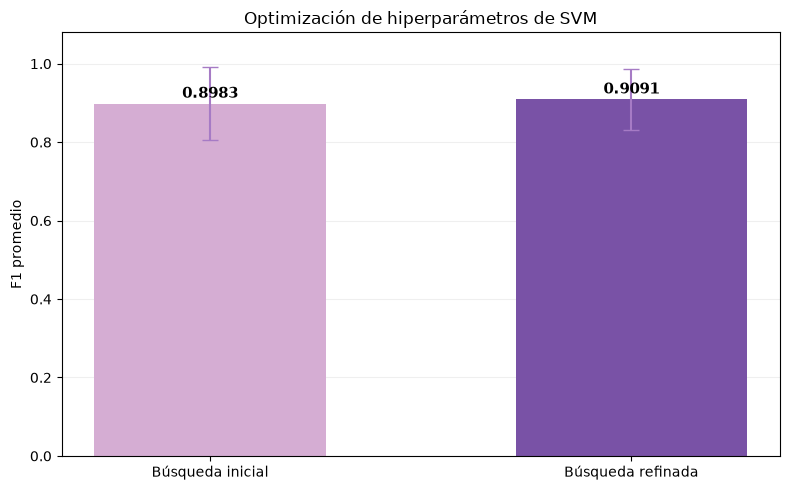

In [89]:
datos = comparacion_opt_svm

fig, ax = plt.subplots(figsize=(8, 5))

colores = ["#D5ADD3", "#7952A6"]

x = np.arange(len(datos))

barras = ax.bar(
    x,
    datos["F1_promedio"],
    yerr=datos["F1_std"],
    color=colores,
    ecolor="#A67BC5",
    capsize=6,
    width=0.55
)

for barra, valor in zip(
    barras, datos["F1_promedio"]
):
    ax.text(
        barra.get_x() + barra.get_width()/2,
        valor + 0.015,
        f"{valor:.4f}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_xticks(x)
ax.set_xticklabels(datos["Búsqueda"])

ax.set_ylabel("F1 promedio")
ax.set_title("Optimización de hiperparámetros de SVM")
ax.set_ylim(0, 1.08)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

La comparación mostró que el refinamiento de hiperparámetros permitió aumentar el F1 promedio de 0.8983 a 0.9091 y reducir la desviación estándar de 0.0940 a 0.0775. La principal diferencia entre las configuraciones fue el valor de gamma, que pasó de scale a 0.15, mientras que el kernel RBF y C = 1 se mantuvieron.

Por lo tanto, se seleccionó la configuración refinada como candidata para las evaluaciones posteriores. Sin embargo, la mejora observada corresponde a los mismos pliegues utilizados durante la optimización, por lo que deberá comprobarse mediante una evaluación independiente antes de concluir que ofrece una mejor capacidad de generalización.

#### 11.2. Optimización de Random Forest

Se optimizarán los hiperparámetros del clasificador Random Forest, que obtuvo un F1 promedio de 0.8960 ± 0.0930 durante la evaluación inicial. Se utilizará la configuración que presentó el mejor desempeño: datos originales, sin balanceo y con selección de características mediante Mutual Information.

Se explorarán hiperparámetros relacionados con la cantidad de árboles, su profundidad y las condiciones de división de los nodos. Se mantendrá la validación cruzada estratificada por grupos, aplicando la selección de características exclusivamente sobre los datos de entrenamiento de cada pliegue. La optimización buscará mejorar el F1 de la clase tóxica sin incrementar innecesariamente la complejidad del modelo.

In [90]:
# Pipeline de Random Forest
pipeline_rf = Pipeline([
    (
        "preprocesamiento",
        clone(representaciones["Mutual Information"])
    ),
    (
        "modelo",
        RandomForestClassifier(
            random_state=42,
            n_jobs=1
        )
    )
])

# Reutilizar los mismos pliegues de SVM
pliegues_rf = pliegues_svm

# Métrica principal
f1_rf = f1_toxic

print("Preparación de Random Forest completada.")
print("Configuración: datos originales, sin balanceo, MI")
print("Número de pliegues:", len(pliegues_rf))

Preparación de Random Forest completada.
Configuración: datos originales, sin balanceo, MI
Número de pliegues: 5


##### 11.2.1. Búsqueda inicial de hiperparámetros

Se realizará una búsqueda aleatoria mediante `RandomizedSearchCV` para optimizar los hiperparámetros de Random Forest. Se evaluarán 30 combinaciones utilizando cinco pliegues de validación cruzada estratificada por grupos.

Se explorarán diferentes cantidades de árboles (`n_estimators`), profundidades máximas (`max_depth`), cantidades mínimas de muestras para dividir nodos (`min_samples_split`) y formar hojas (`min_samples_leaf`), así como el número de características consideradas en cada división (`max_features`). La selección de características mediante Mutual Information se realizará dentro de cada pliegue de entrenamiento, utilizando el F1 de la clase tóxica como métrica principal.

In [91]:
# Espacio de búsqueda
parametros_rf = {
    "modelo__n_estimators": [100, 200, 300, 400],
    "modelo__max_depth": [None, 5, 10, 15, 20, 30],
    "modelo__min_samples_split": [2, 5, 10],
    "modelo__min_samples_leaf": [1, 2, 4],
    "modelo__max_features": ["sqrt", "log2", None]
}

# Búsqueda inicial
busqueda_rf = RandomizedSearchCV(
    estimator=pipeline_rf,
    param_distributions=parametros_rf,
    n_iter=30,
    scoring=f1_rf,
    cv=pliegues_rf,
    refit=True,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

busqueda_rf.fit(X, y)

# Resultados principales
mejor_idx = busqueda_rf.best_index_

print("\nMejores hiperparámetros:")
print(busqueda_rf.best_params_)

print(
    "\nMejor F1 promedio:",
    round(busqueda_rf.best_score_, 4)
)

print(
    "Desviación estándar:",
    round(
        busqueda_rf.cv_results_[
            "std_test_score"
        ][mejor_idx],
        4
    )
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits

Mejores hiperparámetros:
{'modelo__n_estimators': 100, 'modelo__min_samples_split': 5, 'modelo__min_samples_leaf': 1, 'modelo__max_features': 'sqrt', 'modelo__max_depth': 10}

Mejor F1 promedio: 0.9005
Desviación estándar: 0.0828


In [92]:
resultados_busqueda_rf = pd.DataFrame(
    busqueda_rf.cv_results_
)

columnas_rf = [
    "param_modelo__n_estimators",
    "param_modelo__max_depth",
    "param_modelo__min_samples_split",
    "param_modelo__min_samples_leaf",
    "param_modelo__max_features",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

tabla_opt_rf = (
    resultados_busqueda_rf[columnas_rf]
    .sort_values("rank_test_score")
    .head(10)
)

display(tabla_opt_rf.round(4))

,param_modelo__n_estimators,param_modelo__max_depth,param_modelo__min_samples_split,param_modelo__min_samples_leaf,param_modelo__max_features,mean_test_score,std_test_score,rank_test_score
1,100,10,5,1,sqrt,0.9005,0.0828,1
2,200,30,5,2,log2,0.8917,0.0845,2
5,100,20,5,2,sqrt,0.8917,0.0845,2
16,300,15,2,1,log2,0.8917,0.0845,2
20,100,15,5,2,sqrt,0.8917,0.0845,2
22,200,15,5,2,sqrt,0.8917,0.0845,2
19,300,None,10,1,sqrt,0.8917,0.0845,2
17,300,30,10,2,log2,0.8904,0.0831,8
25,300,15,10,2,sqrt,0.8904,0.0831,8
23,300,None,5,2,log2,0.8862,0.0808,10


La búsqueda inicial identificó como mejor configuración un Random Forest de 100 árboles, profundidad máxima de 10, mínimo de 5 muestras para dividir un nodo y una muestra por hoja, utilizando la raíz cuadrada del número de características en cada división.

Esta configuración obtuvo un F1 promedio de 0.9005 ± 0.0828, ligeramente superior al resultado inicial de 0.8960. También se observó que varias combinaciones con mayor cantidad de árboles y profundidad obtuvieron resultados similares o inferiores, lo que sugiere que incrementar la complejidad del modelo no necesariamente mejora su capacidad predictiva.

##### 11.2.2. Refinamiento de hiperparámetros

A partir de los resultados de la búsqueda inicial, se realizará una exploración más detallada de los hiperparámetros de Random Forest. Se evaluarán 72 combinaciones, considerando valores cercanos a la mejor configuración encontrada. Se mantendrá `max_features="sqrt"` y se explorarán diferentes cantidades de árboles, profundidades máximas y condiciones de división de los nodos.

La evaluación utilizará los mismos cinco pliegues de validación cruzada estratificada por grupos y el F1 de la clase tóxica como métrica principal.

In [93]:
# Espacio de búsqueda refinado
parametros_rf_refinado = {
    "modelo__n_estimators": [75, 100, 150],
    "modelo__max_depth": [8, 10, 12, 15],
    "modelo__min_samples_split": [3, 5, 7],
    "modelo__min_samples_leaf": [1, 2],
    "modelo__max_features": ["sqrt"]
}

# Búsqueda exhaustiva
busqueda_rf_refinada = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=parametros_rf_refinado,
    scoring=f1_rf,
    cv=pliegues_rf,
    refit=True,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

busqueda_rf_refinada.fit(X, y)

# Resultados principales
mejor_idx = busqueda_rf_refinada.best_index_

print("\nMejores hiperparámetros:")
print(busqueda_rf_refinada.best_params_)

print(
    "\nMejor F1 promedio:",
    round(busqueda_rf_refinada.best_score_, 4)
)

print(
    "Desviación estándar:",
    round(
        busqueda_rf_refinada.cv_results_[
            "std_test_score"
        ][mejor_idx],
        4
    )
)

Fitting 5 folds for each of 72 candidates, totalling 360 fits

Mejores hiperparámetros:
{'modelo__max_depth': 12, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__min_samples_split': 5, 'modelo__n_estimators': 100}

Mejor F1 promedio: 0.9046
Desviación estándar: 0.084


In [94]:
# Resultados del refinamiento
resultados_refinamiento_rf = pd.DataFrame(
    busqueda_rf_refinada.cv_results_
)

columnas_rf = [
    "param_modelo__n_estimators",
    "param_modelo__max_depth",
    "param_modelo__min_samples_split",
    "param_modelo__min_samples_leaf",
    "param_modelo__max_features",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

tabla_refinamiento_rf = (
    resultados_refinamiento_rf[columnas_rf]
    .sort_values(
        ["rank_test_score", "std_test_score"]
    )
    .head(10)
)

display(tabla_refinamiento_rf.round(4))

,param_modelo__n_estimators,param_modelo__max_depth,param_modelo__min_samples_split,param_modelo__min_samples_leaf,param_modelo__max_features,mean_test_score,std_test_score,rank_test_score
40,100,12,5,1,sqrt,0.9046,0.0840,1
55,100,15,3,1,sqrt,0.9046,0.0840,1
58,100,15,5,1,sqrt,0.9046,0.0840,1
21,75,10,5,1,sqrt,0.9042,0.0856,4
39,75,12,5,1,sqrt,0.9025,0.0833,5
54,75,15,3,1,sqrt,0.9025,0.0833,5
57,75,15,5,1,sqrt,0.9025,0.0833,5
18,75,10,3,1,sqrt,0.9005,0.0828,8
22,100,10,5,1,sqrt,0.9005,0.0828,8
24,75,10,7,1,sqrt,0.9005,0.0828,8


El refinamiento de hiperparámetros permitió aumentar el F1 promedio de 0.9005 a 0.9046. Tres configuraciones alcanzaron el mismo desempeño, todas con 100 árboles, una muestra mínima por hoja y `max_features="sqrt"`. Se seleccionó la configuración con profundidad máxima de 12 y un mínimo de 5 muestras para dividir un nodo, ya que obtuvo el mejor resultado sin requerir árboles más profundos.

Aunque se observó una mejora respecto a la búsqueda inicial, esta fue pequeña y la desviación estándar aumentó ligeramente. Por ello, no se considera necesario continuar refinando el modelo. Además, los resultados corresponden a los pliegues utilizados durante la optimización y deberán verificarse mediante una evaluación independiente.

##### 11.2.3. Comparación de resultados de la optimización

Se compararán los resultados de la búsqueda inicial y del refinamiento de hiperparámetros de Random Forest, considerando el F1 promedio y su desviación estándar entre los cinco pliegues de validación.

Esta comparación permitirá evaluar los cambios en el desempeño y seleccionar la configuración final del modelo para los análisis posteriores.

In [95]:
busquedas_rf = {
    "Búsqueda inicial": busqueda_rf,
    "Búsqueda refinada": busqueda_rf_refinada
}

comparacion_opt_rf = []

for nombre, busqueda in busquedas_rf.items():
    idx = busqueda.best_index_
    params = busqueda.best_params_

    comparacion_opt_rf.append({
        "Búsqueda": nombre,
        "Árboles": params["modelo__n_estimators"],
        "Profundidad": params["modelo__max_depth"],
        "Mín. división": params["modelo__min_samples_split"],
        "Mín. hoja": params["modelo__min_samples_leaf"],
        "Max. características": params["modelo__max_features"],
        "F1_promedio": busqueda.best_score_,
        "F1_std": busqueda.cv_results_[
            "std_test_score"
        ][idx]
    })

comparacion_opt_rf = pd.DataFrame(comparacion_opt_rf)

display(comparacion_opt_rf.round(4))

,Búsqueda,Árboles,Profundidad,Mín. división,Mín. hoja,Max. características,F1_promedio,F1_std
0,Búsqueda inicial,100,10,5,1,sqrt,0.9005,0.0828
1,Búsqueda refinada,100,12,5,1,sqrt,0.9046,0.0840


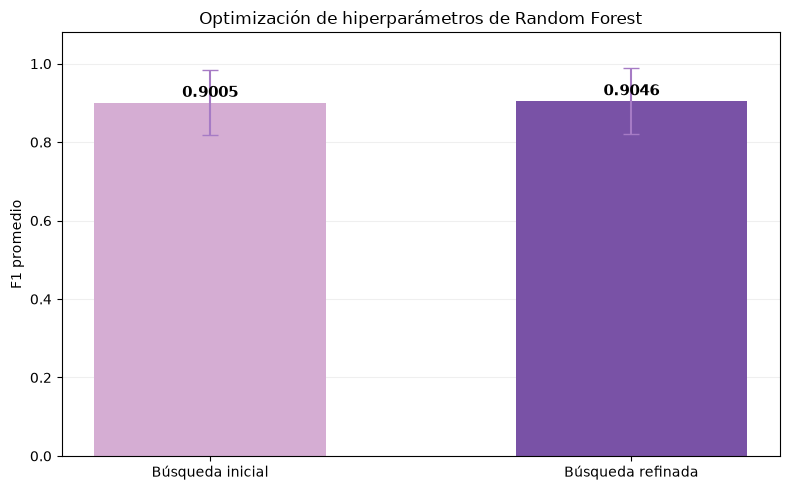

In [96]:
datos = comparacion_opt_rf

fig, ax = plt.subplots(figsize=(8, 5))

colores = ["#D5ADD3", "#7952A6"]
x = np.arange(len(datos))

barras = ax.bar(
    x,
    datos["F1_promedio"],
    yerr=datos["F1_std"],
    color=colores,
    ecolor="#A67BC5",
    capsize=6,
    width=0.55
)

for barra, valor in zip(
    barras, datos["F1_promedio"]
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.015,
        f"{valor:.4f}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_xticks(x)
ax.set_xticklabels(datos["Búsqueda"])

ax.set_ylabel("F1 promedio")
ax.set_title("Optimización de hiperparámetros de Random Forest")
ax.set_ylim(0, 1.08)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


La optimización de Random Forest permitió aumentar el F1 promedio de 0.9005 en la búsqueda inicial a 0.9046 en el refinamiento. La configuración seleccionada utilizó 100 árboles, profundidad máxima de 12, un mínimo de 5 muestras para dividir un nodo, una muestra por hoja y `max_features="sqrt"`.

Aunque el refinamiento produjo una mejora de 0.0041 puntos, la desviación estándar aumentó ligeramente de 0.0828 a 0.0840. Esto indica que el incremento en el desempeño fue moderado y no estuvo acompañado de una reducción en la variabilidad entre pliegues.

Por lo tanto, se seleccionó la configuración refinada como candidata final de Random Forest. Sin embargo, la mejora deberá comprobarse mediante una evaluación independiente, ya que los mismos pliegues se utilizaron para seleccionar los hiperparámetros.

#### 11.3. Optimización de XGBoost

Se optimizarán los hiperparámetros del clasificador XGBoost, que obtuvo un F1 promedio de 0.9056 ± 0.0691 durante la evaluación inicial. Se utilizará la configuración que presentó el mejor desempeño: datos originales, sin balanceo y sin reducción de características.

La optimización se enfocará en ajustar la cantidad de árboles, la profundidad máxima, la tasa de aprendizaje y los parámetros de regularización y muestreo. Se mantendrá la validación cruzada estratificada por grupos, utilizando el F1 de la clase tóxica como métrica principal.

In [97]:
# Pipeline de XGBoost
pipeline_xgb = Pipeline([
    (
        "preprocesamiento",
        clone(representaciones["Sin reducción"])
    ),
    (
        "modelo",
        XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=1,
            tree_method="hist"
        )
    )
])

# Reutilizar los mismos pliegues
pliegues_xgb = pliegues_svm

# Métrica principal
f1_xgb = f1_toxic

print("Preparación de XGBoost completada.")
print("Configuración: datos originales, sin balanceo, sin reducción")
print("Número de pliegues:", len(pliegues_xgb))

Preparación de XGBoost completada.
Configuración: datos originales, sin balanceo, sin reducción
Número de pliegues: 5


##### 11.3.1. Búsqueda inicial de hiperparámetros

Se realizará una búsqueda aleatoria mediante `RandomizedSearchCV`, evaluando 30 combinaciones de hiperparámetros de XGBoost con cinco pliegues de validación cruzada estratificada por grupos.

Se explorarán diferentes cantidades de árboles, profundidades máximas, tasas de aprendizaje y parámetros de muestreo y regularización. Se utilizará el F1 de la clase tóxica como métrica principal.

In [99]:
# Espacio de búsqueda de hiperparámetros
parametros_xgb = {
    "modelo__n_estimators": [100, 200, 300, 400],
    "modelo__max_depth": [2, 3, 4, 5, 6],
    "modelo__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "modelo__subsample": [0.7, 0.85, 1.0],
    "modelo__colsample_bytree": [0.7, 0.85, 1.0],
    "modelo__min_child_weight": [1, 3, 5],
    "modelo__reg_lambda": [0.1, 1, 5, 10]
}

# Búsqueda aleatoria
busqueda_xgb = RandomizedSearchCV(
    estimator=pipeline_xgb,
    param_distributions=parametros_xgb,
    n_iter=30,
    scoring=f1_xgb,
    cv=pliegues_xgb,
    refit=True,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

busqueda_xgb.fit(X, y)

# Resultados principales
mejor_idx = busqueda_xgb.best_index_

print("\nMejores hiperparámetros:")
print(busqueda_xgb.best_params_)

print(
    "\nMejor F1 promedio:",
    round(busqueda_xgb.best_score_, 4)
)

print(
    "Desviación estándar:",
    round(
        busqueda_xgb.cv_results_[
            "std_test_score"
        ][mejor_idx],
        4
    ) 
)   

Fitting 5 folds for each of 30 candidates, totalling 150 fits

Mejores hiperparámetros:
{'modelo__subsample': 0.85, 'modelo__reg_lambda': 0.1, 'modelo__n_estimators': 300, 'modelo__min_child_weight': 3, 'modelo__max_depth': 5, 'modelo__learning_rate': 0.1, 'modelo__colsample_bytree': 0.85}

Mejor F1 promedio: 0.9011
Desviación estándar: 0.0767


In [100]:
resultados_busqueda_xgb = pd.DataFrame(
    busqueda_xgb.cv_results_
)

columnas_xgb = [
    "param_modelo__n_estimators",
    "param_modelo__max_depth",
    "param_modelo__learning_rate",
    "param_modelo__subsample",
    "param_modelo__colsample_bytree",
    "param_modelo__min_child_weight",
    "param_modelo__reg_lambda",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

tabla_opt_xgb = (
    resultados_busqueda_xgb[columnas_xgb]
    .sort_values(
        ["rank_test_score", "std_test_score"]
    )
    .head(10)
)

display(tabla_opt_xgb.round(4))

,param_modelo__n_estimators,param_modelo__max_depth,param_modelo__learning_rate,param_modelo__subsample,param_modelo__colsample_bytree,param_modelo__min_child_weight,param_modelo__reg_lambda,mean_test_score,std_test_score,rank_test_score
5,300,5,0.10,0.85,0.85,3,0.1,0.9011,0.0767,1
18,300,5,0.03,1.00,0.70,1,5.0,0.9009,0.0661,2
26,300,6,0.05,0.85,0.70,1,5.0,0.9004,0.0616,3
21,200,6,0.10,0.70,0.85,3,0.1,0.9001,0.0738,4
17,400,6,0.10,0.70,0.85,3,0.1,0.8991,0.0779,5
20,300,5,0.20,0.85,0.70,3,0.1,0.8991,0.0779,5
24,200,4,0.10,1.00,0.70,5,0.1,0.8989,0.0749,7
14,300,3,0.10,0.70,0.70,5,10.0,0.8978,0.0702,8
29,200,6,0.10,1.00,1.00,3,0.1,0.8968,0.0770,9
22,300,2,0.05,1.00,1.00,1,0.1,0.8960,0.0658,10


La búsqueda inicial de hiperparámetros identificó como mejor configuración un XGBoost de 300 árboles, profundidad máxima de 5 y tasa de aprendizaje de 0.1, obteniendo un F1 promedio de 0.9011 ± 0.0767.

Se observó que varias combinaciones con diferentes profundidades, tasas de aprendizaje y parámetros de regularización alcanzaron resultados similares. La búsqueda no superó el F1 de 0.9056 obtenido durante la evaluación inicial, aunque la comparación requiere considerar las condiciones de validación utilizadas.

Debido a la similitud entre las mejores configuraciones, se realizará un refinamiento dirigido para determinar si pequeños ajustes permiten mejorar el desempeño.

##### 11.3.2. Refinamiento de hiperparámetros

A partir de los resultados de la búsqueda inicial, se realizará una segunda búsqueda aleatoria enfocada en los rangos de hiperparámetros que presentaron los mejores desempeños.

Se evaluarán 30 combinaciones adicionales mediante `RandomizedSearchCV`, utilizando los mismos cinco pliegues de validación cruzada estratificada por grupos y el F1 de la clase tóxica como métrica principal.

El objetivo será determinar si un ajuste más específico de la cantidad de árboles, profundidad, tasa de aprendizaje y parámetros de regularización permite mejorar el desempeño de XGBoost.

In [101]:
# Espacio de búsqueda refinado
parametros_xgb_refinado = {
    "modelo__n_estimators": [200, 300, 400],
    "modelo__max_depth": [4, 5, 6],
    "modelo__learning_rate": [0.03, 0.05, 0.1],
    "modelo__subsample": [0.8, 0.85, 1.0],
    "modelo__colsample_bytree": [0.7, 0.85, 1.0],
    "modelo__min_child_weight": [1, 3],
    "modelo__reg_lambda": [0.1, 1, 5]
}

# Búsqueda refinada
busqueda_xgb_refinada = RandomizedSearchCV(
    estimator=pipeline_xgb,
    param_distributions=parametros_xgb_refinado,
    n_iter=30,
    scoring=f1_xgb,
    cv=pliegues_xgb,
    refit=True,
    random_state=21,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

busqueda_xgb_refinada.fit(X, y)

# Resultados principales
mejor_idx = busqueda_xgb_refinada.best_index_

print("\nMejores hiperparámetros:")
print(busqueda_xgb_refinada.best_params_)

print(
    "\nMejor F1 promedio:",
    round(busqueda_xgb_refinada.best_score_, 4)
)

print(
    "Desviación estándar:",
    round(
        busqueda_xgb_refinada.cv_results_[
            "std_test_score"
        ][mejor_idx],
        4
    )
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits

Mejores hiperparámetros:
{'modelo__subsample': 1.0, 'modelo__reg_lambda': 0.1, 'modelo__n_estimators': 200, 'modelo__min_child_weight': 1, 'modelo__max_depth': 6, 'modelo__learning_rate': 0.1, 'modelo__colsample_bytree': 0.85}

Mejor F1 promedio: 0.9074
Desviación estándar: 0.0687


In [102]:
# Resultados del refinamiento
resultados_refinamiento_xgb = pd.DataFrame(
    busqueda_xgb_refinada.cv_results_
)

columnas_xgb = [
    "param_modelo__n_estimators",
    "param_modelo__max_depth",
    "param_modelo__learning_rate",
    "param_modelo__subsample",
    "param_modelo__colsample_bytree",
    "param_modelo__min_child_weight",
    "param_modelo__reg_lambda",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

tabla_refinamiento_xgb = (
    resultados_refinamiento_xgb[columnas_xgb]
    .sort_values(
        ["rank_test_score", "std_test_score"]
    )
    .head(10)
)

display(tabla_refinamiento_xgb.round(4))

,param_modelo__n_estimators,param_modelo__max_depth,param_modelo__learning_rate,param_modelo__subsample,param_modelo__colsample_bytree,param_modelo__min_child_weight,param_modelo__reg_lambda,mean_test_score,std_test_score,rank_test_score
9,200,6,0.10,1.00,0.85,1,0.1,0.9074,0.0687,1
13,400,6,0.03,1.00,0.85,1,1.0,0.9056,0.0618,2
29,300,6,0.05,0.80,1.00,3,0.1,0.9045,0.0714,3
1,300,6,0.03,1.00,0.85,1,0.1,0.9043,0.0668,4
11,300,4,0.03,1.00,0.85,1,5.0,0.9022,0.0680,5
27,200,4,0.10,0.85,0.85,3,1.0,0.9012,0.0721,6
23,200,6,0.10,0.80,0.70,1,5.0,0.9004,0.0649,7
7,300,5,0.05,1.00,0.85,3,0.1,0.9000,0.0714,8
4,300,4,0.03,0.85,1.00,1,0.1,0.8994,0.0622,9
2,300,5,0.03,1.00,1.00,3,1.0,0.8990,0.0762,10


El refinamiento de hiperparámetros permitió aumentar a 0.9074, mientras que la desviación estándar disminuyó a 0.0687.

La mejor configuración utilizó 200 árboles, profundidad máxima de 6, tasa de aprendizaje de 0.1, `subsample=1.0`, `colsample_bytree=0.85`, `min_child_weight=1` y `reg_lambda=0.1`.

Aunque el refinamiento mejoró ligeramente el desempeño, la diferencia fue pequeña. Además, se observó que configuraciones con distintas cantidades de árboles y parámetros de regularización alcanzaron resultados similares, por lo que no se considera necesario continuar la optimización.

Estos resultados corresponden a la validación utilizada para seleccionar hiperparámetros y no constituyen una evaluación independiente de la capacidad de generalización.

##### 11.3.3. Comparación de resultados de la optimización

Se compararán los resultados de la búsqueda inicial y del refinamiento de hiperparámetros de XGBoost, considerando el F1 promedio y su desviación estándar entre los cinco pliegues de validación. Esta comparación permitirá evaluar los cambios en el desempeño y seleccionar la configuración final del modelo para los análisis posteriores.

In [103]:
busquedas_xgb = {
    "Búsqueda inicial": busqueda_xgb,
    "Búsqueda refinada": busqueda_xgb_refinada
}

comparacion_opt_xgb = []

for nombre, busqueda in busquedas_xgb.items():
    idx = busqueda.best_index_
    params = busqueda.best_params_

    comparacion_opt_xgb.append({
        "Búsqueda": nombre,
        "Árboles": params["modelo__n_estimators"],
        "Profundidad": params["modelo__max_depth"],
        "Learning rate": params["modelo__learning_rate"],
        "Subsample": params["modelo__subsample"],
        "Colsample": params["modelo__colsample_bytree"],
        "Min. child weight": params["modelo__min_child_weight"],
        "Reg. lambda": params["modelo__reg_lambda"],
        "F1_promedio": busqueda.best_score_,
        "F1_std": busqueda.cv_results_[
            "std_test_score"
        ][idx]
    })

comparacion_opt_xgb = pd.DataFrame(
    comparacion_opt_xgb
)

display(comparacion_opt_xgb.round(4))

,Búsqueda,Árboles,Profundidad,Learning rate,Subsample,Colsample,Min. child weight,Reg. lambda,F1_promedio,F1_std
0,Búsqueda inicial,300,5,0.1,0.85,0.85,3,0.1,0.9011,0.0767
1,Búsqueda refinada,200,6,0.1,1.00,0.85,1,0.1,0.9074,0.0687


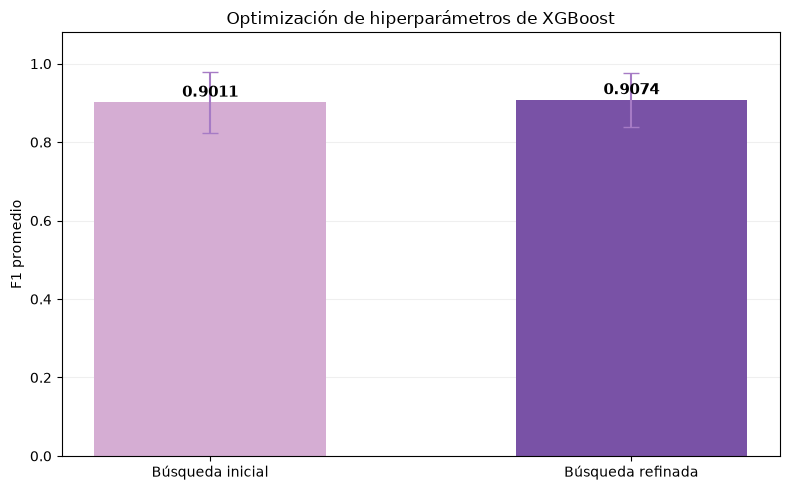

In [104]:
datos = comparacion_opt_xgb

fig, ax = plt.subplots(figsize=(8, 5))

colores = ["#D5ADD3", "#7952A6"]
x = np.arange(len(datos))

barras = ax.bar(
    x,
    datos["F1_promedio"],
    yerr=datos["F1_std"],
    color=colores,
    ecolor="#A67BC5",
    capsize=6,
    width=0.55
)

for barra, valor in zip(
    barras, datos["F1_promedio"]
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.015,
        f"{valor:.4f}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_xticks(x)
ax.set_xticklabels(datos["Búsqueda"])

ax.set_ylabel("F1 promedio")
ax.set_title("Optimización de hiperparámetros de XGBoost")
ax.set_ylim(0, 1.08)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

El refinamiento de hiperparámetros permitió mejorar el F1 promedio de XGBoost de 0.9011 a 0.9074, mientras que la desviación estándar disminuyó de 0.0767 a 0.0687.

La configuración refinada utilizó 200 árboles y profundidad máxima de 6, frente a los 300 árboles y profundidad de 5 seleccionados inicialmente. Esto muestra que una mayor cantidad de árboles no necesariamente produce mejores resultados.

Se seleccionó la configuración refinada como candidata final de XGBoost. Sin embargo, dado que las diferencias fueron pequeñas y los mismos pliegues se utilizaron para seleccionar los hiperparámetros, será necesario realizar una evaluación independiente antes de establecer conclusiones sobre su capacidad de generalización.

### 12. Evaluación comparativa de los modelos optimizados

Se realizará una evaluación comparativa de SVM, Random Forest y XGBoost para estimar su capacidad de generalización después de la optimización de hiperparámetros.

Debido a que los resultados anteriores se obtuvieron utilizando los mismos pliegues empleados para seleccionar los hiperparámetros, se utilizará validación cruzada anidada estratificada por grupos. Este procedimiento permitirá separar la selección de hiperparámetros de la evaluación del desempeño.

Se utilizará el F1 de la clase tóxica como métrica principal y se calcularán métricas adicionales para comparar el comportamiento de los clasificadores.

#### 12.1. Preparación de la evaluación comparativa

Se definirán cinco pliegues externos para evaluar los modelos y tres pliegues internos para seleccionar sus hiperparámetros. En ambos niveles se respetará la separación por grupos para evitar que observaciones relacionadas aparezcan simultáneamente en entrenamiento y validación.

In [105]:
# Validación externa: evaluación del desempeño
cv_externo = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Validación interna: selección de hiperparámetros
cv_interno = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=21
)

# Crear particiones externas
pliegues_externos = list(
    cv_externo.split(X, y, groups)
)

# Comprobar que no exista superposición de grupos
resumen_pliegues = []

grupos_array = np.asarray(groups)
y_array = np.asarray(y)

for i, (idx_train, idx_test) in enumerate(
    pliegues_externos, start=1
):
    grupos_train = set(grupos_array[idx_train])
    grupos_test = set(grupos_array[idx_test])

    interseccion = grupos_train.intersection(
        grupos_test
    )

    resumen_pliegues.append({
        "Pliegue": i,
        "Entrenamiento": len(idx_train),
        "Evaluación": len(idx_test),
        "Grupos train": len(grupos_train),
        "Grupos test": len(grupos_test),
        "Grupos compartidos": len(interseccion),
        "% tóxicos test": round(
            100 * y_array[idx_test].mean(), 2
        )
    })

tabla_pliegues_externos = pd.DataFrame(
    resumen_pliegues
)

display(tabla_pliegues_externos)

assert (
    tabla_pliegues_externos["Grupos compartidos"] == 0
).all(), "Se detectó superposición de grupos."

print("\nValidación externa preparada correctamente.")

,Pliegue,Entrenamiento,Evaluación,Grupos train,Grupos test,Grupos compartidos,% tóxicos test
0,1,724,157,34,8,0,51.59
1,2,731,150,35,7,0,56.00
2,3,729,152,33,9,0,53.95
3,4,613,268,32,10,0,52.99
4,5,727,154,34,8,0,56.49



Validación externa preparada correctamente.


La validación externa se dividió en cinco pliegues estratificados por grupos. Se comprobó que no existió superposición de grupos entre entrenamiento y evaluación en ninguno de ellos, evitando que observaciones relacionadas aparecieran en ambas particiones.

#### 12.2. Validación cruzada anidada de los modelos optimizados

Se evaluarán conjuntamente SVM, Random Forest y XGBoost mediante validación cruzada anidada, utilizando cinco pliegues externos para estimar el desempeño y tres internos para seleccionar los hiperparámetros.

Cada modelo conservará su configuración de preprocesamiento y tratamiento de datos: SVM utilizará eliminación de duplicados y oversampling sin reducción de características; Random Forest utilizará los datos originales con selección mediante Mutual Information; y XGBoost utilizará los datos originales sin reducción ni balanceo.

En cada pliegue externo, los hiperparámetros se seleccionarán utilizando exclusivamente el conjunto de entrenamiento. Posteriormente, se calcularán F1, precisión, sensibilidad y especificidad sobre el conjunto de evaluación externo.

Se utilizarán las mismas particiones externas para los tres modelos, permitiendo una comparación consistente de su desempeño.

In [106]:
# Configuración de modelos y búsquedas internas
configuracion_modelos = {
    "SVM": {
        "estimador": estimador_svm,
        "parametros": {
            "pipeline__modelo__kernel": ["rbf"],
            "pipeline__modelo__C": [0.5, 1, 2],
            "pipeline__modelo__gamma": ["scale", 0.1, 0.15]
        },
        "tipo_busqueda": "grid"
    },

    "Random Forest": {
        "estimador": pipeline_rf,
        "parametros": {
            "modelo__n_estimators": [75, 100, 150],
            "modelo__max_depth": [8, 10, 12, 15],
            "modelo__min_samples_split": [3, 5, 7],
            "modelo__min_samples_leaf": [1, 2],
            "modelo__max_features": ["sqrt"]
        },
        "tipo_busqueda": "random",
        "n_iter": 15
    },

    "XGBoost": {
        "estimador": pipeline_xgb,
        "parametros": {
            "modelo__n_estimators": [200, 300, 400],
            "modelo__max_depth": [4, 5, 6],
            "modelo__learning_rate": [0.03, 0.05, 0.1],
            "modelo__subsample": [0.8, 0.85, 1.0],
            "modelo__colsample_bytree": [0.7, 0.85, 1.0],
            "modelo__min_child_weight": [1, 3],
            "modelo__reg_lambda": [0.1, 1, 5]
        },
        "tipo_busqueda": "random",
        "n_iter": 15
    }
}

print("Modelos configurados:")
for nombre in configuracion_modelos:
    print("-", nombre)

Modelos configurados:
- SVM
- Random Forest
- XGBoost


In [109]:
def evaluar_modelos_anidados(
    X, y, groups, configuraciones,
    pliegues_externos, cv_interno
):
    resultados = []
    hiperparametros = []

    grupos_array = np.asarray(groups)

    # Asegurar indexación por posición
    X = X.reset_index(drop=True)
    y = pd.Series(np.asarray(y)).reset_index(drop=True)

    for nombre, config in configuraciones.items():

        print(f"\nEvaluando {nombre}...")

        for i, (idx_train, idx_test) in enumerate(
            pliegues_externos, start=1
        ):
            X_train = X.iloc[idx_train]
            X_test = X.iloc[idx_test]
            y_train = y.iloc[idx_train]
            y_test = y.iloc[idx_test]

            grupos_train = grupos_array[idx_train]

            # Crear pliegues internos
            pliegues_internos = list(
                cv_interno.split(
                    X_train, y_train, grupos_train
                )
            )

            argumentos = dict(
                estimator=clone(config["estimador"]),
                param_grid=config["parametros"],
                scoring=f1_toxic,
                cv=pliegues_internos,
                refit=True,
                n_jobs=-1,
                error_score="raise"
            )

            if config["tipo_busqueda"] == "grid":
                busqueda = GridSearchCV(**argumentos)

            else:
                argumentos["param_distributions"] = (
                    argumentos.pop("param_grid")
                )
                argumentos["n_iter"] = config["n_iter"]
                argumentos["random_state"] = 42

                busqueda = RandomizedSearchCV(
                    **argumentos
                )

            # Optimización interna
            busqueda.fit(X_train, y_train)

            # Evaluación externa
            y_pred = busqueda.predict(X_test)

            tn, fp, fn, tp = confusion_matrix(
                y_test, y_pred, labels=[0, 1]
            ).ravel()

            resultados.append({
                "Modelo": nombre,
                "Pliegue": i,
                "F1": f1_score(
                    y_test, y_pred, zero_division=0
                ),
                "Precisión": precision_score(
                    y_test, y_pred, zero_division=0
                ),
                "Sensibilidad": recall_score(
                    y_test, y_pred, zero_division=0
                ),
                "Especificidad": (
                    tn / (tn + fp)
                    if (tn + fp) > 0 else np.nan
                )
            })

            hiperparametros.append({
                "Modelo": nombre,
                "Pliegue": i,
                "Mejores parámetros": busqueda.best_params_,
                "F1 interno": busqueda.best_score_
            })

            print(
                f"  Pliegue {i}/5 | "
                f"F1 externo: {resultados[-1]['F1']:.4f}"
            )

    return (
        pd.DataFrame(resultados),
        pd.DataFrame(hiperparametros)
    )


# Ejecutar evaluación de los tres modelos
resultados_anidados, parametros_anidados = (
    evaluar_modelos_anidados(
        X=X,
        y=y,
        groups=groups,
        configuraciones=configuracion_modelos,
        pliegues_externos=pliegues_externos,
        cv_interno=cv_interno
    )
)

display(resultados_anidados.round(4))



Evaluando SVM...
  Pliegue 1/5 | F1 externo: 0.8727
  Pliegue 2/5 | F1 externo: 0.6716
  Pliegue 3/5 | F1 externo: 0.9560
  Pliegue 4/5 | F1 externo: 0.8405
  Pliegue 5/5 | F1 externo: 0.9943

Evaluando Random Forest...
  Pliegue 1/5 | F1 externo: 0.9818
  Pliegue 2/5 | F1 externo: 0.7451
  Pliegue 3/5 | F1 externo: 0.9576
  Pliegue 4/5 | F1 externo: 0.8580
  Pliegue 5/5 | F1 externo: 0.9162

Evaluando XGBoost...
  Pliegue 1/5 | F1 externo: 0.9359
  Pliegue 2/5 | F1 externo: 0.7808
  Pliegue 3/5 | F1 externo: 0.9820
  Pliegue 4/5 | F1 externo: 0.8606
  Pliegue 5/5 | F1 externo: 0.9029


,Modelo,Pliegue,F1,Precisión,Sensibilidad,Especificidad
0,SVM,1,0.8727,0.8571,0.8889,0.8421
1,SVM,2,0.6716,0.9000,0.5357,0.9242
2,SVM,3,0.9560,0.9870,0.9268,0.9857
3,SVM,4,0.8405,0.7446,0.9648,0.6270
4,SVM,5,0.9943,0.9886,1.0000,0.9851
5,Random Forest,1,0.9818,0.9643,1.0000,0.9605
6,Random Forest,2,0.7451,0.8261,0.6786,0.8182
7,Random Forest,3,0.9576,0.9518,0.9634,0.9429
8,Random Forest,4,0.8580,0.7513,1.0000,0.6270
9,Random Forest,5,0.9162,0.8913,0.9425,0.8507


In [110]:

metricas = [
    "F1", "Precisión",
    "Sensibilidad", "Especificidad"
]

resumen_anidado = (
    resultados_anidados
    .groupby("Modelo")[metricas]
    .agg(["mean", "std"])
)

display(resumen_anidado.round(4))

F1         Precisión         Sensibilidad          \
                 mean     std      mean     std         mean     std   
Modelo                                                                 
Random Forest  0.8917  0.0945    0.8770  0.0892       0.9169  0.1355   
SVM            0.8670  0.1255    0.8955  0.1016       0.8632  0.1877   
XGBoost        0.8924  0.0766    0.9021  0.0878       0.8976  0.1314   

              Especificidad          
                       mean     std  
Modelo                               
Random Forest        0.8399  0.1333  
SVM                  0.8728  0.1495  
XGBoost              0.8711  0.1383

La validación cruzada anidada mostró que XGBoost obtuvo el mayor F1 promedio (0.8924 ± 0.0766), seguido de Random Forest (0.8917 ± 0.0945) y SVM (0.8670 ± 0.1255).

Aunque XGBoost presentó el mejor desempeño general y la menor variabilidad entre pliegues, la diferencia respecto a Random Forest fue mínima. Por su parte, Random Forest alcanzó la mayor sensibilidad (0.9169), lo que indica una mayor capacidad para identificar observaciones tóxicas, mientras que XGBoost obtuvo la mayor precisión (0.9021).

También se observaron diferencias importantes entre pliegues, lo que sugiere que la composición de los grupos influye en el desempeño predictivo. En conjunto, los resultados muestran que XGBoost y Random Forest son alternativas competitivas, sin evidencia suficiente para afirmar que uno supera claramente al otro.

#### 12.3. Comparación visual de los modelos

Se visualizarán los resultados de la validación cruzada anidada para comparar el desempeño de SVM, Random Forest y XGBoost.

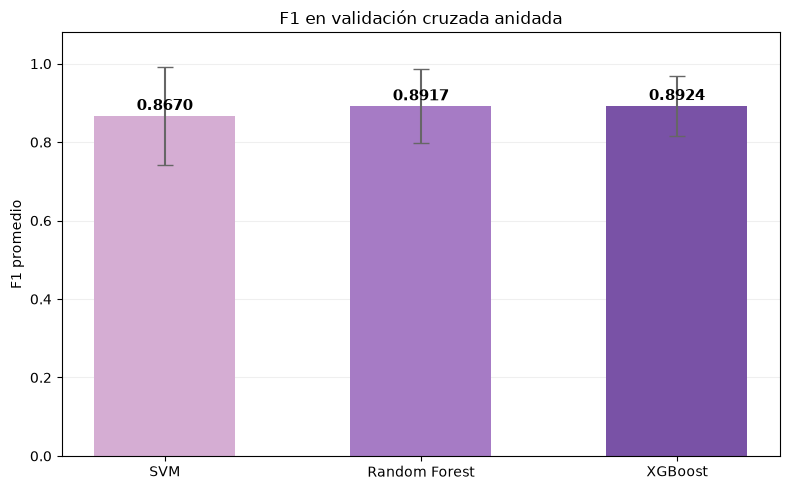

In [111]:
orden = ["SVM", "Random Forest", "XGBoost"]
colores = ["#D5ADD3", "#A67BC5", "#7952A6"]

resumen_f1 = (
    resultados_anidados
    .groupby("Modelo")["F1"]
    .agg(["mean", "std"])
    .reindex(orden)
)

fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(orden))

barras = ax.bar(
    x,
    resumen_f1["mean"],
    yerr=resumen_f1["std"],
    color=colores,
    capsize=6,
    ecolor="#666666",
    width=0.55
)

for barra, valor in zip(barras, resumen_f1["mean"]):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.015,
        f"{valor:.4f}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_xticks(x)
ax.set_xticklabels(orden)
ax.set_ylabel("F1 promedio")
ax.set_title("F1 en validación cruzada anidada")
ax.set_ylim(0, 1.08)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

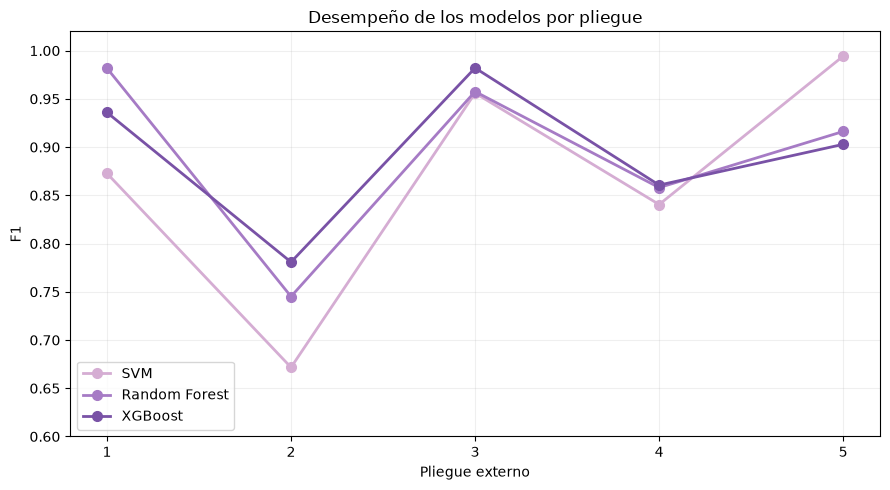

In [112]:
fig, ax = plt.subplots(figsize=(9, 5))

for modelo, color in zip(orden, colores):
    datos = (
        resultados_anidados[
            resultados_anidados["Modelo"] == modelo
        ]
        .sort_values("Pliegue")
    )

    ax.plot(
        datos["Pliegue"],
        datos["F1"],
        marker="o",
        linewidth=2,
        markersize=7,
        label=modelo,
        color=color
    )

ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel("Pliegue externo")
ax.set_ylabel("F1")
ax.set_title("Desempeño de los modelos por pliegue")
ax.set_ylim(0.6, 1.02)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


Las visualizaciones mostraron que XGBoost y Random Forest obtuvieron desempeños prácticamente equivalentes, con F1 promedio de 0.8924 y 0.8917, respectivamente. Sin embargo, XGBoost presentó una menor variabilidad entre pliegues, mientras que Random Forest alcanzó una sensibilidad ligeramente superior.

Por su parte, SVM obtuvo el menor F1 promedio (0.8670) y la mayor desviación estándar (0.1255), mostrando un comportamiento menos consistente entre particiones.

La comparación por pliegue reveló diferencias importantes en el desempeño de los tres modelos. Particularmente, el segundo pliegue presentó los resultados más bajos para todos los clasificadores, mientras que el tercero mostró desempeños elevados. Esto sugiere que la composición de los grupos de evaluación influye en la dificultad de clasificación.

En conjunto, los resultados indican que Random Forest y XGBoost son las alternativas más competitivas, aunque sus diferencias son demasiado pequeñas para establecer una superioridad clara.

#### 12.4. Discusión y selección de modelos

La validación cruzada anidada permitió comparar el desempeño de los tres clasificadores mediante una evaluación externa a la búsqueda interna de hiperparámetros.

XGBoost obtuvo el mayor F1 promedio (0.8924 ± 0.0766), seguido de Random Forest (0.8917 ± 0.0945) y SVM (0.8670 ± 0.1255). Aunque XGBoost presentó una menor variabilidad entre pliegues, la diferencia de desempeño respecto a Random Forest fue prácticamente insignificante.

También se observaron diferencias entre las métricas. Random Forest alcanzó la mayor sensibilidad (0.9169), lo que resulta relevante para identificar nanopartículas potencialmente tóxicas, mientras que XGBoost obtuvo la mayor precisión (0.9021). Esto refleja un compromiso entre detectar observaciones tóxicas y reducir las clasificaciones positivas incorrectas.

Por su parte, SVM presentó un desempeño promedio inferior y mayor variabilidad, aunque alcanzó resultados competitivos en algunos pliegues. Esto sugiere que su comportamiento puede ser más sensible a las características de los grupos utilizados para la evaluación.

En consecuencia, se seleccionaron **Random Forest y XGBoost como modelos principales** para los análisis posteriores, conservando SVM como referencia comparativa. 

Finalmente, aunque la validación por grupos permitió evaluar los modelos sobre observaciones relacionadas con grupos no vistos durante el entrenamiento, todavía no se ha determinado su capacidad para generalizar a tipos de nanopartículas completamente desconocidos. Para investigar esta limitación, se realizará un experimento *Leave-One-Nanoparticle-Type-Out*.

### 13. Evaluación de generalización a tipos de nanopartículas no vistos

Se evaluará la capacidad de generalización de los modelos mediante una estrategia *Leave-One-Nanoparticle-Type-Out*, en la que cada tipo de nanopartícula se excluirá completamente del entrenamiento y se utilizará como conjunto de evaluación. Este procedimiento permitirá determinar si los patrones aprendidos a partir de las propiedades fisicoquímicas de ciertos tipos de nanopartículas pueden transferirse a otros materiales.

Se evaluarán Random Forest y XGBoost como modelos principales, conservando SVM como referencia comparativa.

#### 13.1. Preparación de las particiones

Se analizará la cantidad de observaciones y la distribución de clases de cada tipo de nanopartícula. Posteriormente, se construirán cinco particiones, utilizando cuatro tipos para entrenamiento y uno para evaluación. Antes de entrenar los modelos, se comprobará que el tipo de nanopartícula utilizado para evaluación no aparezca en el conjunto de entrenamiento.

In [113]:
# Preparar los datos para el análisis
datos_np = X[["NPs"]].copy().reset_index(drop=True)
datos_np["Toxicidad"] = np.asarray(y)

# Distribución de clases por tipo de nanopartícula
distribucion_np = pd.crosstab(
    datos_np["NPs"],
    datos_np["Toxicidad"]
).reindex(columns=[0, 1], fill_value=0)

distribucion_np = distribucion_np.rename(
    columns={0: "No tóxicas", 1: "Tóxicas"}
)

distribucion_np["Total"] = distribucion_np.sum(axis=1)

distribucion_np["% tóxicas"] = (
    100 * distribucion_np["Tóxicas"]
    / distribucion_np["Total"]
)

display(distribucion_np.round(2))


Toxicidad,No tóxicas,Tóxicas,Total,% tóxicas
NPs,,,,
Al2O3,18,0,18,0.00
CuO,11,40,51,78.43
Fe2O3,18,0,18,0.00
TiO2,194,6,200,3.00
ZnO,164,430,594,72.39


In [115]:
# Cada tipo de nanopartícula define un grupo
tipos_np = X["NPs"].to_numpy()

logo_np = LeaveOneGroupOut()

pliegues_np = list(
    logo_np.split(X, y, groups=tipos_np)
)

resumen_np = []

for i, (idx_train, idx_test) in enumerate(
    pliegues_np, start=1
):
    tipos_train = set(tipos_np[idx_train])
    tipos_test = set(tipos_np[idx_test])

    assert tipos_train.isdisjoint(tipos_test), (
        "Se detectó un tipo compartido."
    )

    resumen_np.append({
        "Pliegue": i,
        "NP excluida": ", ".join(sorted(tipos_test)),
        "Entrenamiento": len(idx_train),
        "Evaluación": len(idx_test),
        "Grupos compartidos": len(
            tipos_train.intersection(tipos_test)
        ),
        "% tóxicas test": round(
            100 * np.asarray(y)[idx_test].mean(), 2
        )
    })

tabla_particiones_np = pd.DataFrame(resumen_np)

display(tabla_particiones_np)

print(
    "\nParticiones Leave-One-Nanoparticle-Type-Out "
    "preparadas correctamente."
)

,Pliegue,NP excluida,Entrenamiento,Evaluación,Grupos compartidos,% tóxicas test
0,1,Al2O3,863,18,0,0.00
1,2,CuO,830,51,0,78.43
2,3,Fe2O3,863,18,0,0.00
3,4,TiO2,681,200,0,3.00
4,5,ZnO,287,594,0,72.39



Particiones Leave-One-Nanoparticle-Type-Out preparadas correctamente.


Las particiones *Leave-One-Nanoparticle-Type-Out* se construyeron correctamente, sin superposición de tipos de nanopartículas entre entrenamiento y evaluación. Se identificaron diferencias importantes en la cantidad de observaciones y la distribución de clases. ZnO concentró la mayor cantidad de registros (594), mientras que Al₂O₃ y Fe₂O₃ contaron únicamente con 18 observaciones cada uno, todas clasificadas como no tóxicas.

También se observó un fuerte desbalance en TiO₂, con solo un 3% de observaciones tóxicas, en contraste con CuO (78.43%) y ZnO (72.39%).

Estas diferencias deberán considerarse al interpretar los resultados, ya que algunas métricas no estarán definidas para materiales que contienen una sola clase. Por ello, la evaluación incluirá métricas por clase y matrices de confusión, evitando depender exclusivamente del F1.

#### 13.2. Evaluación Leave-One-Nanoparticle-Type-Out

Se evaluará la capacidad de generalización de SVM, Random Forest y XGBoost mediante cinco particiones, dejando fuera un tipo de nanopartícula en cada una. En este experimento se excluirá la variable categórica `NPs` de las características predictoras, utilizando únicamente las propiedades fisicoquímicas. Esto permitirá estudiar si los patrones aprendidos de otros materiales pueden transferirse a un tipo de nanopartícula desconocido.

Se conservarán las estrategias de entrenamiento seleccionadas anteriormente para cada modelo, adaptando el preprocesamiento a las variables numéricas disponibles. La evaluación considerará las diferencias en tamaño y distribución de clases entre materiales.

In [116]:
# Variables fisicoquímicas
variables_numericas = [
    "coresize", "hydrosize", "surfcharge",
    "surfarea", "Ec", "Expotime",
    "dosage", "e", "NOxygen"
]

X_np = X[variables_numericas].copy()

# SVM: sin duplicados + oversampling
pipeline_svm_np = ImbPipeline([
    ("escalado", StandardScaler()),
    ("balanceo", RandomOverSampler(random_state=42)),
    ("modelo", SVC(
        kernel="rbf",
        C=1,
        gamma=0.15,
        random_state=42
    ))
])

estimador_svm_np = ClasificadorSinDuplicados(
    pipeline=pipeline_svm_np
)

# Random Forest: Mutual Information
selector_mi_np = SelectKBest(
    score_func=partial(
        mutual_info_classif,
        random_state=42
    ),
    k=5
)

pipeline_rf_np = Pipeline([
    ("escalado", StandardScaler()),
    ("seleccion", selector_mi_np),
    ("modelo", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=1,
        max_features="sqrt",
        random_state=42,
        n_jobs=1
    ))
])

# XGBoost: sin reducción
pipeline_xgb_np = Pipeline([
    ("escalado", StandardScaler()),
    ("modelo", XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=1.0,
        colsample_bytree=0.85,
        min_child_weight=1,
        reg_lambda=0.1,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=1
    ))
])

modelos_np = {
    "SVM": estimador_svm_np,
    "Random Forest": pipeline_rf_np,
    "XGBoost": pipeline_xgb_np
}

print("Preparación completada.")
print("Características utilizadas:", X_np.shape[1])
print("Modelos:", list(modelos_np.keys()))
print("Particiones:", len(pliegues_np))

Preparación completada.
Características utilizadas: 9
Modelos: ['SVM', 'Random Forest', 'XGBoost']
Particiones: 5


##### 13.2.1. Evaluación de los tres modelos

Se ejecutará el procedimiento *Leave-One-Nanoparticle-Type-Out* para SVM, Random Forest y XGBoost. En cada iteración, los modelos se entrenarán utilizando cuatro tipos de nanopartículas y se evaluarán sobre el material excluido.

Se calcularán F1, precisión, sensibilidad, especificidad, exactitud y exactitud balanceada. Cuando alguna clase no esté presente en el conjunto de evaluación, las métricas que dependan de ella se reportarán como no definidas.

También se almacenarán las matrices de confusión y las predicciones individuales para facilitar los análisis posteriores. La eliminación de duplicados, el balanceo y la selección de características se realizarán exclusivamente durante el entrenamiento, evitando utilizar información del material excluido.

In [117]:
resultados_np = []
predicciones_np = []
matrices_np = {}

y_np = np.asarray(y)
tipos_np = X["NPs"].to_numpy()

for nombre_modelo, estimador in modelos_np.items():

    print(f"\nEvaluando {nombre_modelo}...")

    for idx_train, idx_test in pliegues_np:

        material = str(tipos_np[idx_test][0])

        X_train = X_np.iloc[idx_train]
        X_test = X_np.iloc[idx_test]

        y_train = y_np[idx_train]
        y_test = y_np[idx_test]

        # Entrenar exclusivamente con los otros materiales
        modelo = clone(estimador)
        modelo.fit(X_train, y_train)

        # Predecir el material excluido
        y_pred = modelo.predict(X_test)

        # Matriz de confusión con ambas clases
        tn, fp, fn, tp = confusion_matrix(
            y_test, y_pred, labels=[0, 1]
        ).ravel()

        hay_positivos = (tp + fn) > 0
        hay_negativos = (tn + fp) > 0
        hay_pred_positivos = (tp + fp) > 0

        sensibilidad = (
            tp / (tp + fn)
            if hay_positivos else np.nan
        )

        especificidad = (
            tn / (tn + fp)
            if hay_negativos else np.nan
        )

        precision = (
            tp / (tp + fp)
            if hay_pred_positivos else np.nan
        )

        # F1 tóxico solo si la clase positiva existe
        f1 = (
            f1_score(
                y_test, y_pred,
                pos_label=1,
                zero_division=0
            )
            if hay_positivos else np.nan
        )

        # Promedio de recalls de clases presentes
        recalls = [
            valor for valor in
            [sensibilidad, especificidad]
            if not np.isnan(valor)
        ]
        exactitud_balanceada = np.mean(recalls)

        resultados_np.append({
            "Modelo": nombre_modelo,
            "NP excluida": material,
            "N": len(idx_test),
            "% tóxicas": 100 * np.mean(y_test),
            "F1": f1,
            "Precisión": precision,
            "Sensibilidad": sensibilidad,
            "Especificidad": especificidad,
            "Exactitud": accuracy_score(
                y_test, y_pred
            ),
            "Exactitud balanceada": exactitud_balanceada,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp
        })

        matrices_np[(nombre_modelo, material)] = np.array([
            [tn, fp],
            [fn, tp]
        ])

        # Guardar predicciones individuales
        for indice, real, predicho in zip(
            idx_test, y_test, y_pred
        ):
            predicciones_np.append({
                "Modelo": nombre_modelo,
                "Índice": indice,
                "NP excluida": material,
                "Real": int(real),
                "Predicción": int(predicho)
            })

        print(
            f"  {material}: "
            f"F1 = {f1:.4f}, "
            f"Exactitud = {accuracy_score(y_test, y_pred):.4f}"
        )

# Convertir resultados a tablas
resultados_np = pd.DataFrame(resultados_np)
predicciones_np = pd.DataFrame(predicciones_np)

display(
    resultados_np[
        [
            "Modelo", "NP excluida", "N",
            "F1", "Precisión", "Sensibilidad",
            "Especificidad", "Exactitud",
            "Exactitud balanceada"
        ]
    ].round(4)
)


Evaluando SVM...
  Al2O3: F1 = nan, Exactitud = 1.0000
  CuO: F1 = 0.8791, Exactitud = 0.7843
  Fe2O3: F1 = nan, Exactitud = 1.0000
  TiO2: F1 = 0.2667, Exactitud = 0.8350
  ZnO: F1 = 0.8398, Exactitud = 0.7239

Evaluando Random Forest...
  Al2O3: F1 = nan, Exactitud = 1.0000
  CuO: F1 = 0.9877, Exactitud = 0.9804
  Fe2O3: F1 = nan, Exactitud = 1.0000
  TiO2: F1 = 0.0889, Exactitud = 0.3850
  ZnO: F1 = 0.8353, Exactitud = 0.7172

Evaluando XGBoost...
  Al2O3: F1 = nan, Exactitud = 1.0000
  CuO: F1 = 0.9877, Exactitud = 0.9804
  Fe2O3: F1 = nan, Exactitud = 0.7778
  TiO2: F1 = 0.1143, Exactitud = 0.5350
  ZnO: F1 = 0.9208, Exactitud = 0.8754


,Modelo,NP excluida,N,F1,Precisión,Sensibilidad,Especificidad,Exactitud,Exactitud balanceada
0,SVM,Al2O3,18,NaN,NaN,NaN,1.0000,1.0000,1.0000
1,SVM,CuO,51,0.8791,0.7843,1.0000,0.0000,0.7843,0.5000
2,SVM,Fe2O3,18,NaN,NaN,NaN,1.0000,1.0000,1.0000
3,SVM,TiO2,200,0.2667,0.1538,1.0000,0.8299,0.8350,0.9149
4,SVM,ZnO,594,0.8398,0.7239,1.0000,0.0000,0.7239,0.5000
5,Random Forest,Al2O3,18,NaN,NaN,NaN,1.0000,1.0000,1.0000
6,Random Forest,CuO,51,0.9877,0.9756,1.0000,0.9091,0.9804,0.9545
7,Random Forest,Fe2O3,18,NaN,NaN,NaN,1.0000,1.0000,1.0000
8,Random Forest,TiO2,200,0.0889,0.0465,1.0000,0.3660,0.3850,0.6830
9,Random Forest,ZnO,594,0.8353,0.7220,0.9907,0.0000,0.7172,0.4953


La evaluación mostró diferencias importantes en la capacidad de generalización de los modelos según el material excluido.

Random Forest y XGBoost obtuvieron los mejores resultados en CuO, ambos con un F1 de 0.9877. En ZnO, XGBoost presentó el mejor desempeño (F1 = 0.9208), mientras que SVM y Random Forest mostraron una tendencia a clasificar las observaciones como tóxicas.

En contraste, TiO₂ fue el material más difícil de predecir. Aunque los tres modelos identificaron todas las observaciones tóxicas, produjeron numerosos falsos positivos, obteniendo valores de F1 entre 0.0889 y 0.2667.

Para Al₂O₃ y Fe₂O₃, que únicamente contienen observaciones no tóxicas, no fue posible evaluar el F1 de la clase tóxica. SVM y Random Forest clasificaron correctamente todas sus observaciones, mientras que XGBoost presentó algunos falsos positivos en Fe₂O₃.

En conjunto, los resultados evidenciaron que un buen desempeño en validación cruzada por grupos no garantiza una generalización equivalente a materiales completamente desconocidos. Esto destaca la importancia de considerar las diferencias entre tipos de nanopartículas al desarrollar modelos predictivos de toxicidad.

#### 13.3. Comparación visual por tipo de nanopartícula

Se visualizarán los resultados de la evaluación *Leave-One-Nanoparticle-Type-Out* para comparar el desempeño de SVM, Random Forest y XGBoost sobre materiales no observados durante el entrenamiento.

Para Al₂O₃ y Fe₂O₃, que no contienen observaciones tóxicas, el F1 de la clase positiva permanecerá sin definir.

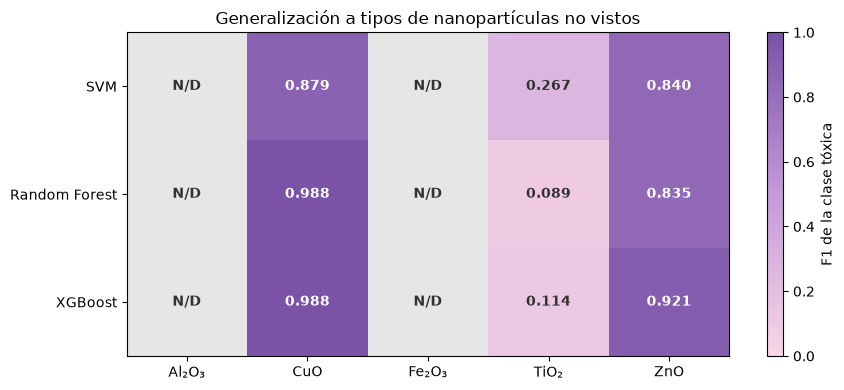

In [118]:
orden_modelos = ["SVM", "Random Forest", "XGBoost"]
orden_np = ["Al2O3", "CuO", "Fe2O3", "TiO2", "ZnO"]

tabla_f1_np = (
    resultados_np
    .pivot(index="Modelo", columns="NP excluida", values="F1")
    .reindex(index=orden_modelos, columns=orden_np)
)

cmap = LinearSegmentedColormap.from_list(
    "morado_rosa",
    ["#F7D6E6", "#C49AD9", "#7952A6"]
)
cmap.set_bad("#E6E6E6")

fig, ax = plt.subplots(figsize=(9, 4))

imagen = ax.imshow(
    np.ma.masked_invalid(tabla_f1_np.to_numpy(dtype=float)),
    cmap=cmap,
    vmin=0,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(orden_np)))
ax.set_xticklabels(
    ["Al₂O₃", "CuO", "Fe₂O₃", "TiO₂", "ZnO"]
)
ax.set_yticks(range(len(orden_modelos)))
ax.set_yticklabels(orden_modelos)

for i in range(len(orden_modelos)):
    for j in range(len(orden_np)):
        valor = tabla_f1_np.iloc[i, j]
        etiqueta = "N/D" if pd.isna(valor) else f"{valor:.3f}"

        ax.text(
            j, i, etiqueta,
            ha="center",
            va="center",
            color="white" if pd.notna(valor) and valor > 0.7 else "#333333",
            fontweight="bold"
        )

fig.colorbar(imagen, ax=ax, label="F1 de la clase tóxica")
ax.set_title("Generalización a tipos de nanopartículas no vistos")

plt.tight_layout()
plt.show()

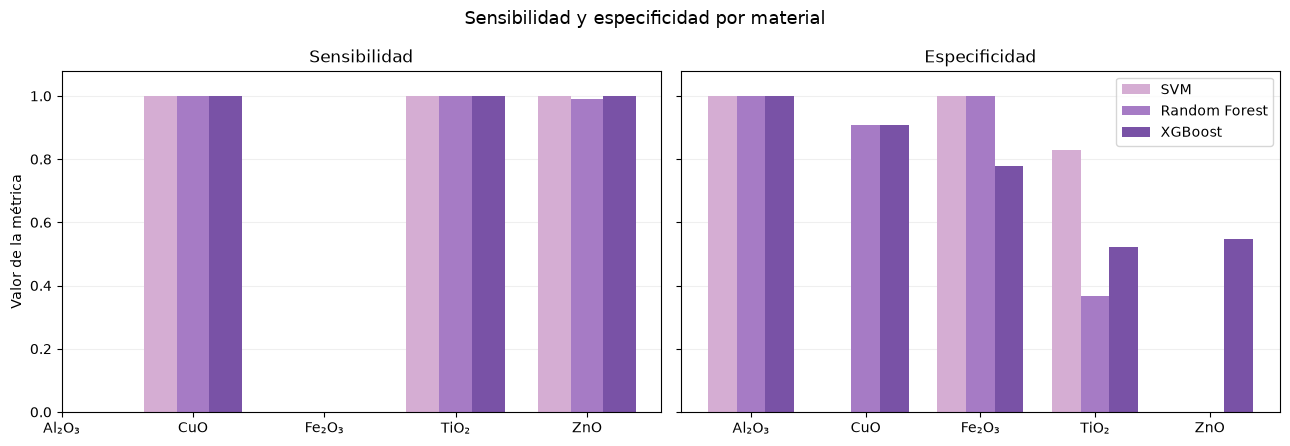

In [119]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.5),
    sharey=True
)

colores = ["#D5ADD3", "#A67BC5", "#7952A6"]
x = np.arange(len(orden_np))
ancho = 0.25

for ax, metrica in zip(
    axes, ["Sensibilidad", "Especificidad"]
):
    tabla = (
        resultados_np
        .pivot(
            index="NP excluida",
            columns="Modelo",
            values=metrica
        )
        .reindex(index=orden_np, columns=orden_modelos)
    )

    for i, modelo in enumerate(orden_modelos):
        ax.bar(
            x + (i - 1) * ancho,
            tabla[modelo],
            width=ancho,
            color=colores[i],
            label=modelo
        )

    ax.set_xticks(x)
    ax.set_xticklabels(
        ["Al₂O₃", "CuO", "Fe₂O₃", "TiO₂", "ZnO"]
    )
    ax.set_title(metrica)
    ax.set_ylim(0, 1.08)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

axes[0].set_ylabel("Valor de la métrica")
axes[1].legend(loc="upper right")

fig.suptitle(
    "Sensibilidad y especificidad por material",
    fontsize=13
)

plt.tight_layout()
plt.show()

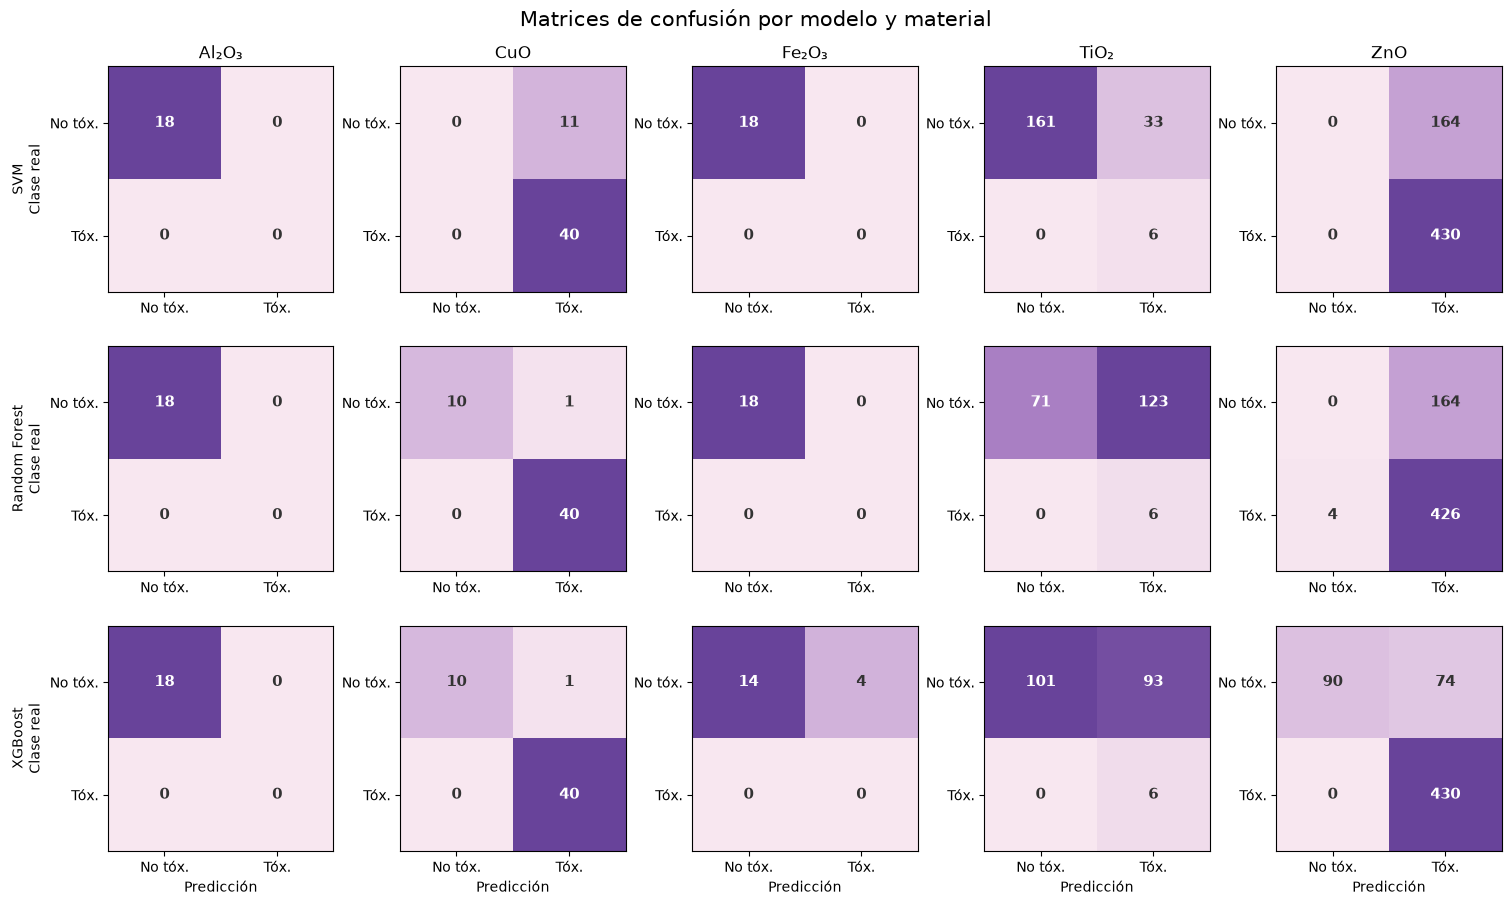

In [120]:
cmap_confusion = LinearSegmentedColormap.from_list(
    "confusion_morada",
    ["#F8E7F0", "#B58BCB", "#68439A"]
)

fig, axes = plt.subplots(
    3, 5,
    figsize=(15, 9),
    constrained_layout=True
)

for i, modelo in enumerate(orden_modelos):
    for j, material in enumerate(orden_np):

        ax = axes[i, j]
        matriz = matrices_np[(modelo, material)]

        # Escala relativa a cada matriz
        ax.imshow(
            matriz,
            cmap=cmap_confusion,
            vmin=0,
            vmax=max(1, matriz.max())
        )

        for fila in range(2):
            for columna in range(2):
                valor = matriz[fila, columna]

                ax.text(
                    columna, fila,
                    str(valor),
                    ha="center",
                    va="center",
                    fontsize=11,
                    fontweight="bold",
                    color=(
                        "white"
                        if valor > matriz.max() * 0.55
                        else "#333333"
                    )
                )

        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])

        ax.set_xticklabels(["No tóx.", "Tóx."])
        ax.set_yticklabels(["No tóx.", "Tóx."])

        if i == 0:
            ax.set_title(
                ["Al₂O₃", "CuO", "Fe₂O₃", "TiO₂", "ZnO"][j],
                fontsize=12
            )

        if j == 0:
            ax.set_ylabel(
                f"{modelo}\nClase real",
                fontsize=10
            )

        if i == 2:
            ax.set_xlabel("Predicción")

fig.suptitle(
    "Matrices de confusión por modelo y material",
    fontsize=15
)

plt.show()


Las visualizaciones confirmaron que la capacidad de generalización de los modelos dependió considerablemente del tipo de nanopartícula excluido.

Random Forest y XGBoost obtuvieron resultados elevados en CuO, mientras que XGBoost presentó el mejor desempeño en ZnO. En contraste, TiO₂ representó el mayor desafío para los tres clasificadores, con valores bajos de F1 debido a la gran cantidad de falsos positivos.

Las matrices de confusión mostraron que una sensibilidad elevada no necesariamente estuvo acompañada de una buena especificidad. Particularmente, SVM y Random Forest tendieron a clasificar casi todas las observaciones de ZnO como tóxicas, mientras que XGBoost logró distinguir una mayor proporción de observaciones no tóxicas.

Para Al₂O₃ y Fe₂O₃, la ausencia de observaciones tóxicas impidió evaluar el F1 de la clase positiva. Aunque la mayoría de los modelos clasificaron correctamente estas observaciones, los resultados deben interpretarse considerando el tamaño reducido de ambos conjuntos.

En general, los resultados evidenciaron limitaciones importantes en la transferencia de patrones de toxicidad entre materiales, especialmente cuando sus distribuciones de clases y características difieren de las utilizadas durante el entrenamiento.

#### 13.4. Discusión de la capacidad de generalización

La evaluación *Leave-One-Nanoparticle-Type-Out* mostró que un buen desempeño en validación cruzada por grupos no garantiza una generalización equivalente a tipos de nanopartículas desconocidos.

Los resultados variaron considerablemente según el material. Random Forest y XGBoost alcanzaron un F1 de 0.9877 en CuO, mientras que XGBoost obtuvo 0.9208 en ZnO. En contraste, los tres modelos presentaron dificultades en TiO₂, principalmente debido a la gran cantidad de falsos positivos, a pesar de alcanzar una sensibilidad de 1.0.

Estas diferencias podrían relacionarse con el desbalance de clases, la distribución desigual de observaciones y las propiedades fisicoquímicas de cada material. Además, Al₂O₃ y Fe₂O₃ contaron únicamente con 18 observaciones no tóxicas cada uno, lo que limitó su evaluación.

Otra limitación es que los hiperparámetros se seleccionaron previamente utilizando información de todos los materiales, por lo que este experimento debe considerarse exploratorio.

En general, **XGBoost mostró el desempeño más competitivo en algunos materiales, pero ningún modelo fue superior en todos los casos**. Los resultados destacan la necesidad de contar con datos más diversos y equilibrados para mejorar la generalización de los modelos de predicción de toxicidad.

### 14. Análisis de importancia de características

Se analizará la contribución de las propiedades fisicoquímicas a las predicciones de toxicidad mediante *Permutation Importance*. Esta técnica permitirá estimar la importancia de cada característica a partir de la disminución del F1 cuando sus valores se permutan aleatoriamente. A diferencia de Mutual Information, que evalúa la relación estadística entre las variables y la clase objetivo, Permutation Importance considera el comportamiento del modelo entrenado.

Se compararán Random Forest y XGBoost, los dos modelos que presentaron el mejor desempeño general durante la validación cruzada anidada.

#### 14.1. Preparación del análisis

Se utilizarán los cinco pliegues externos definidos anteriormente para calcular la importancia de las características sobre conjuntos de evaluación no utilizados durante el entrenamiento.

Los modelos conservarán sus configuraciones de preprocesamiento e hiperparámetros refinados. El cálculo se realizará sobre las características originales, de modo que los resultados puedan interpretarse en términos de las propiedades fisicoquímicas.

In [122]:
# Modelos seleccionados para el análisis
modelos_importancia = {
    "Random Forest": clone(
        busqueda_rf_refinada.best_estimator_
    ),
    "XGBoost": clone(
        busqueda_xgb_refinada.best_estimator_
    )
}

# Características predictoras originales
caracteristicas = X.columns.tolist()

# Configuración del análisis
n_repeticiones = 10
semilla = 42

print("Preparación de importancia de características completada.")
print("Modelos:", list(modelos_importancia.keys()))
print("Número de características:", len(caracteristicas))
print("Pliegues de evaluación:", len(pliegues_externos))
print("Repeticiones por característica:", n_repeticiones)


Preparación de importancia de características completada.
Modelos: ['Random Forest', 'XGBoost']
Número de características: 10
Pliegues de evaluación: 5
Repeticiones por característica: 10


#### 14.2. Cálculo de Permutation Importance

Se calculará la importancia de las características de Random Forest y XGBoost mediante *Permutation Importance*, utilizando los cinco pliegues externos.

En cada partición, el modelo se entrenará con los datos correspondientes y se evaluará la disminución del F1 al permutar individualmente cada característica. El procedimiento se repetirá diez veces por variable para reducir la variabilidad asociada a las permutaciones aleatorias.

In [123]:
resultados_importancia = []

for nombre, estimador in modelos_importancia.items():

    print(f"\nCalculando importancia: {nombre}")

    for i, (idx_train, idx_test) in enumerate(
        pliegues_externos, start=1
    ):

        X_train = X.iloc[idx_train]
        X_test = X.iloc[idx_test]

        y_train = np.asarray(y)[idx_train]
        y_test = np.asarray(y)[idx_test]

        # Entrenar únicamente con el pliegue de entrenamiento
        modelo = clone(estimador)
        modelo.fit(X_train, y_train)

        # Importancia sobre el pliegue de evaluación
        importancia = permutation_importance(
            estimator=modelo,
            X=X_test,
            y=y_test,
            scoring=f1_toxic,
            n_repeats=n_repeticiones,
            random_state=semilla,
            n_jobs=-1
        )

        # Guardar cada repetición
        for j, caracteristica in enumerate(caracteristicas):
            for repeticion, valor in enumerate(
                importancia.importances[j], start=1
            ):
                resultados_importancia.append({
                    "Modelo": nombre,
                    "Pliegue": i,
                    "Característica": caracteristica,
                    "Repetición": repeticion,
                    "Importancia": valor
                })

        print(f"  Pliegue {i}/5 completado")

# Resultados completos
importancias_df = pd.DataFrame(resultados_importancia)

# Resumen por modelo y característica
resumen_importancia = (
    importancias_df
    .groupby(["Modelo", "Característica"])["Importancia"]
    .agg(["mean", "std"])
    .reset_index()
    .rename(columns={
        "mean": "Importancia media",
        "std": "Desviación estándar"
    })
)

display(
    resumen_importancia
    .sort_values(
        ["Modelo", "Importancia media"],
        ascending=[True, False]
    )
    .round(4)
)



Calculando importancia: Random Forest
  Pliegue 1/5 completado
  Pliegue 2/5 completado
  Pliegue 3/5 completado
  Pliegue 4/5 completado
  Pliegue 5/5 completado

Calculando importancia: XGBoost
  Pliegue 1/5 completado
  Pliegue 2/5 completado
  Pliegue 3/5 completado
  Pliegue 4/5 completado
  Pliegue 5/5 completado


,Modelo,Característica,Importancia media,Desviación estándar
5,Random Forest,dosage,0.2196,0.0457
3,Random Forest,NPs,0.1106,0.0835
8,Random Forest,surfarea,0.0375,0.0260
9,Random Forest,surfcharge,0.0232,0.0146
4,Random Forest,coresize,0.0138,0.0134
6,Random Forest,e,0.0038,0.0080
0,Random Forest,Ec,0.0000,0.0000
1,Random Forest,Expotime,0.0000,0.0000
2,Random Forest,NOxygen,0.0000,0.0000
7,Random Forest,hydrosize,-0.0039,0.0136


##### 14.2.1. Comparación visual de importancia de características

Se compararán las importancias promedio obtenidas mediante *Permutation Importance* para Random Forest y XGBoost. La visualización permitirá identificar las variables que más contribuyeron al desempeño predictivo de ambos modelos y observar las diferencias en su dependencia de las propiedades fisicoquímicas.

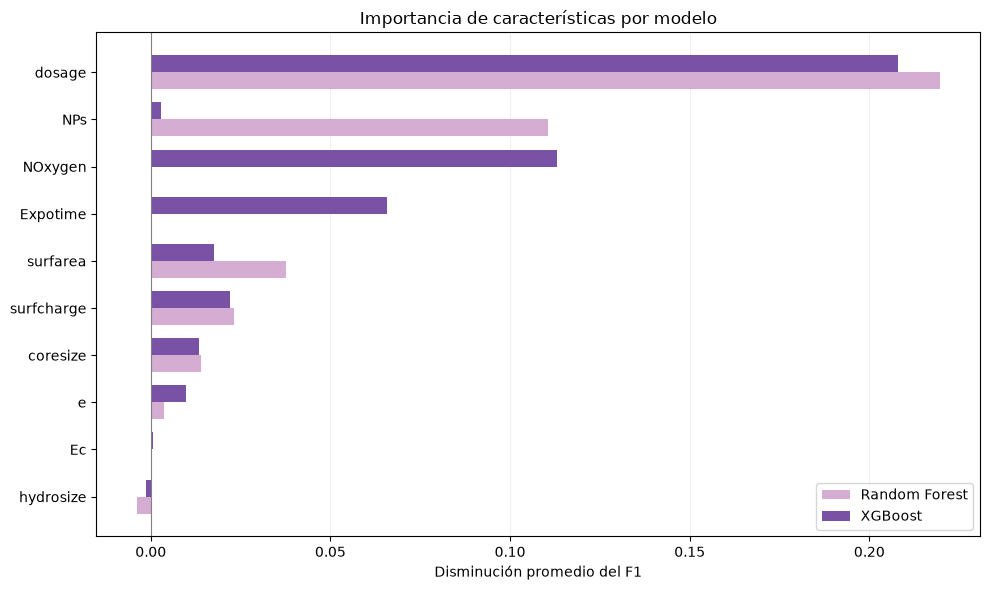

In [124]:
# Tabla comparativa
tabla_importancia = (
    resumen_importancia
    .pivot(
        index="Característica",
        columns="Modelo",
        values="Importancia media"
    )
)

# Ordenar por importancia promedio entre modelos
tabla_importancia["Promedio"] = (
    tabla_importancia[
        ["Random Forest", "XGBoost"]
    ].mean(axis=1)
)

tabla_importancia = tabla_importancia.sort_values(
    "Promedio", ascending=True
)

# Gráfica horizontal
fig, ax = plt.subplots(figsize=(10, 6))

y_pos = np.arange(len(tabla_importancia))
altura = 0.36

ax.barh(
    y_pos - altura / 2,
    tabla_importancia["Random Forest"],
    height=altura,
    color="#D5ADD3",
    label="Random Forest"
)

ax.barh(
    y_pos + altura / 2,
    tabla_importancia["XGBoost"],
    height=altura,
    color="#7952A6",
    label="XGBoost"
)

ax.set_yticks(y_pos)
ax.set_yticklabels(tabla_importancia.index)

ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Disminución promedio del F1")
ax.set_title("Importancia de características por modelo")
ax.legend()
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### 14.3. Interpretación de las propiedades fisicoquímicas relevantes

El análisis de *Permutation Importance* mostró que la dosis (`dosage`) fue la característica más relevante para ambos modelos, lo que sugiere que la cantidad de exposición desempeña un papel importante en la predicción de toxicidad.

Sin embargo, se observaron diferencias en las variables secundarias. Random Forest mostró una mayor dependencia del tipo de nanopartícula (`NPs`), mientras que XGBoost utilizó principalmente el número de oxígenos (`NOxygen`) y el tiempo de exposición (`Expotime`). Las propiedades superficiales, como `surfarea` y `surfcharge`, también presentaron contribuciones positivas, aunque menores.

Por otro lado, `hydrosize` tuvo una importancia prácticamente nula, a pesar de haber destacado anteriormente mediante Mutual Information. Esto evidencia que una asociación estadística con la toxicidad no necesariamente implica una contribución importante al desempeño de un modelo.

En conjunto, los resultados sugieren que la dosis fue el predictor más influyente en los modelos evaluados. No obstante, estas importancias reflejan contribuciones predictivas y no permiten establecer relaciones causales entre las propiedades fisicoquímicas y la toxicidad.

### 15. Conclusiones generales

Este proyecto permitió evaluar distintas técnicas de aprendizaje automático para predecir la toxicidad de nanopartículas de óxidos metálicos a partir de sus propiedades fisicoquímicas y condiciones de exposición.

**Desempeño predictivo.** Random Forest y XGBoost fueron los modelos más competitivos, alcanzando valores de F1 de 0.8917 y 0.8924, respectivamente, mediante validación cruzada anidada. Aunque XGBoost presentó una menor variabilidad, las diferencias entre ambos fueron mínimas, por lo que no se identificó una superioridad clara.

**Preprocesamiento y selección de características.** La comparación de distintas representaciones mostró que técnicas como PCA y Mutual Information no necesariamente mejoraron el desempeño. En particular, Random Forest se benefició de la selección de características, mientras que XGBoost obtuvo mejores resultados utilizando todas las variables. Esto demuestra la importancia de adaptar el preprocesamiento a cada modelo.

**Tratamiento de duplicados.** Se identificó una cantidad considerable de registros duplicados y algunas combinaciones de características con etiquetas contradictorias. Su eliminación modificó significativamente la distribución de clases y produjo efectos diferentes según el clasificador, por lo que no resultó conveniente aplicar una misma estrategia de limpieza a todos los modelos.

**Generalización a materiales desconocidos.** La evaluación *Leave-One-Nanoparticle-Type-Out* reveló que un buen desempeño en validación cruzada no garantiza resultados equivalentes sobre tipos de nanopartículas ausentes del entrenamiento. Aunque los modelos alcanzaron resultados elevados en CuO y ZnO, presentaron dificultades importantes en TiO₂, principalmente debido a los falsos positivos.

**Importancia de características.** El análisis de *Permutation Importance* identificó la dosis (`dosage`) como la variable de mayor contribución predictiva en Random Forest y XGBoost. También se observaron diferencias en la importancia de otras propiedades, como el tipo de nanopartícula, el tiempo de exposición y el número de oxígenos.

En conjunto, los resultados muestran que el aprendizaje automático tiene potencial para apoyar la predicción de toxicidad de nanopartículas. Sin embargo, **la calidad y diversidad de los datos, las decisiones de preprocesamiento y la estrategia de validación son tan importantes como la elección del algoritmo**.

#### 15.1. Limitaciones y trabajo futuro

La principal limitación del estudio fue la distribución desigual de observaciones entre tipos de nanopartículas, junto con la presencia de duplicados y etiquetas contradictorias. Algunos materiales contaron con muy pocos registros y una sola clase de toxicidad, lo que dificultó evaluar su capacidad de generalización.

Además, aunque se utilizó validación cruzada anidada para la optimización de hiperparámetros, algunas decisiones de selección de modelos y preprocesamiento se realizaron previamente utilizando el conjunto completo. Por ello, los resultados no representan una evaluación completamente independiente de todas las decisiones metodológicas.

Como trabajo futuro, sería conveniente ampliar el conjunto de datos con más observaciones de los materiales menos representados, incorporar nuevas propiedades fisicoquímicas y explorar estrategias de validación que contemplen simultáneamente los grupos experimentales y los tipos de nanopartículas.

También sería interesante evaluar técnicas de interpretación adicionales y comprobar experimentalmente las predicciones, con el objetivo de desarrollar modelos más confiables para apoyar la evaluación de nanotoxicidad.